# DPF Data Training — 5 Days, Hands-on
### Data cleaning, analysis, visualisation and machine learning for Single Customer View (SCV) data

**Deposit Protection Fund (DPF) of Uganda · 9:00 AM – 4:00 PM daily**

**No coding experience is needed.** We start from the very beginning and build up one small step at a time.

By Friday you will be able to:
1. Check SCV data against DPF's rules (NIN, other ID, phone, alternative mode of payment)
2. Clean and combine data from several banks — even files too big for Excel
3. Work out the protected amount for every depositor, and produce exception reports automatically
4. Make clear charts and a dashboard (in Python and in Tableau)
5. Use simple machine learning to spot unusual records

> All the data in this course is **made up** (fictional banks, people and numbers). It looks like real SCV data, so what you learn works on real files.

## How to use this notebook

**A notebook has two kinds of boxes ("cells"):**
- **Text cells** like this one — read them.
- **Code cells** (grey boxes with `[ ]` on the left) — these are instructions for the computer.

**To run a code cell:** click inside it and press **Shift + Enter**.
- While it runs you see `[*]`. When it finishes, a number appears, e.g. `[5]`, and any result is shown underneath.

**Three rules:**
1. **Run the cells in order, from the top.** Later cells use things made by earlier cells.
2. **If you close the notebook or restart, run it again from the top** (menu: *Run All*).
3. **If you see an error, read the last line first.** It usually tells you what is wrong.
   The most common one, `NameError: name '...' is not defined`, just means an earlier cell has not been run yet.

At the end of each section, take one minute to write in your own words: *What did I learn? Why does it matter for DPF?*

---
# Setup (do this before Day 1)

## Step 1 — Install Anaconda
Anaconda installs Python and everything else we need in one go.

1. Go to **https://www.anaconda.com/download** and download the installer for your computer (Windows 64-bit, or Mac).
2. Run the installer. Click **Next**, **I Agree**, choose **Just Me**, keep the suggested folder, and click **Install**.
3. When it finishes, open **Anaconda Navigator** from the Start menu, and click **Launch** under **JupyterLab**.

## Step 2 — Put the files in one folder
Make a folder, for example `Documents\DPF_Training`, and put **both** of these files in it:
- this notebook (`DPF_SCV_5Day_Training_Notebook.ipynb`)
- the data file (`DPF_SCV_Training_Dummy_Data.xlsx`)

In JupyterLab, find the folder in the left-hand panel and double-click the notebook to open it.

## Using VS Code instead of JupyterLab?
That works too, but VS Code must use **Anaconda's Python**. Some programs (PyMOL, ArcGIS, QGIS…) install their
own Python, and that one crashes with our charts.
- Click **Select Kernel** (top right of the notebook) → **Python Environments** → choose the one with **`anaconda3`** in its path.

## No installation possible?
Use **Google Colab** (free, in the browser): go to https://colab.research.google.com, upload this notebook,
then upload the Excel file using the 📁 folder icon on the left.

## Step 3 — Run the check below

In [49]:
# CHECK: is the right Python running, and are all the tools installed?
# Just run this cell (Shift + Enter). It installs anything that is missing.

import sys
print("Python being used:", sys.executable)

if "pymol" in sys.executable.lower() or "schrodinger" in sys.executable.lower():
    print("WARNING: this is PyMOL's Python. Please switch the kernel to Anaconda (see 'Using VS Code' above).")

# The tools (packages) this course needs
needed = ["pandas", "numpy", "matplotlib", "seaborn", "plotly", "openpyxl", "sklearn", "nbformat"]

missing = []
for package in needed:
    try:
        __import__(package)          # try to load the package
        print("OK      ", package)
    except ImportError:
        print("MISSING ", package)
        missing.append(package)

if missing:
    # the install name of "sklearn" is "scikit-learn"
    to_install = ["scikit-learn" if p == "sklearn" else p for p in missing]
    get_ipython().run_line_magic("pip", "install " + " ".join(to_install))
    print("Installed. Now restart the kernel (Kernel -> Restart) and run the notebook from the top.")
else:
    print("All tools are installed. You are ready!")

Python being used: /usr/local/bin/python3
OK       pandas
OK       numpy
OK       matplotlib
OK       seaborn
OK       plotly
OK       openpyxl
OK       sklearn
OK       nbformat
All tools are installed. You are ready!


| If you see… | It means… | Do this |
|---|---|---|
| `FileNotFoundError` | Python cannot find the Excel file | Put the Excel file in the same folder as the notebook |
| `NameError: name '...' is not defined` | An earlier cell has not been run | Run the notebook from the top |
| "The kernel died / crashed" | Usually the wrong Python is being used | Switch the kernel to **Anaconda** and run from the top |
| `PermissionError` when saving | The Excel file is open in Excel | Close it in Excel and run the cell again |
| `[*]` stays for a long time | The cell is still working | Wait. If it never finishes: *Kernel → Interrupt* |

---
## Step 4 — Load the tools (run this every time you open the notebook)

`import` loads a tool so we can use it. The short names after `as` (`pd`, `np`, `plt`…) are the usual nicknames
— you will see them in every Python tutorial.

In [50]:
%matplotlib inline
# The line above tells charts to appear inside the notebook.

import os                          # work with folders and files
import re                          # search text using patterns
import sys                         # information about Python itself
import time                        # measure how long something takes
import warnings                    # control warning messages
from pathlib import Path           # handle file paths
from difflib import SequenceMatcher   # compare how similar two names are
from IPython.display import display   # show tables nicely

import pandas as pd                # TABLES  - the main tool of the week
import numpy as np                 # NUMBERS - fast maths
import matplotlib.pyplot as plt    # CHARTS
import seaborn as sns              # nicer CHARTS
import plotly.express as px        # INTERACTIVE charts
import plotly.graph_objects as go  # INTERACTIVE charts (more control)
from plotly.subplots import make_subplots   # several interactive charts on one page

warnings.filterwarnings("ignore", category=FutureWarning)   # hide "this will change in future" messages
pd.set_option("display.max_columns", 60)                   # show up to 60 columns of a table
pd.set_option("display.float_format", "{:,.2f}".format)    # show numbers like 4,500,000.50
sns.set_theme(style="whitegrid")                           # a clean look for charts

print("Tools loaded. pandas version:", pd.__version__)

Tools loaded. pandas version: 2.1.4


In [51]:
# Colours we use for charts all week (you do not need to change anything here).
# The same colour always means the same thing: blue = protected, orange = above the limit, etc.
COLOURS = {
    "protected": "#2a78d6",     # blue
    "outstanding": "#eb6834",   # orange
    "good": "#0ca30c",          # green  - OK / ready
    "warning": "#fab219",       # amber  - needs attention
    "serious": "#ec835a",       # light red
    "critical": "#d03b3b",      # red    - blocked
    "neutral": "#898781",       # grey
}
CATEGORY_ORDER_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
print("Chart colours ready.")

Chart colours ready.


## Step 5 — Can Python see the data file?

In [52]:
DATA_FILE = "DPF_SCV_Training_Dummy_Data.xlsx"     # the name of our data file
OUTPUT_DIR = Path("DPF_outputs")                   # a folder for everything we create
OUTPUT_DIR.mkdir(exist_ok=True)                    # make the folder (if it is not there yet)

print("This notebook is working in the folder:", os.getcwd())
print("Is the data file there?", Path(DATA_FILE).exists())

✅ **You should see** `Is the data file there? True`. If it says `False`, move the Excel file into the folder shown, then run the cell again.

An Excel file can have several sheets. Let us list them:

In [53]:
workbook = pd.ExcelFile(DATA_FILE)
for sheet in workbook.sheet_names:
    print(sheet)

README
SCV_Dummy_Data
RawExport_BankA
RawExport_BankB
RawExport_BankC
RawExport_BankD
Target_Schema
Lookup_Institutions
Lookup_Branches
Lookup_Telecoms
Lookup_FX_Rates
Lab_Payout_File
Survey_Awareness


## Words you will meet this week

| Word | Meaning |
|---|---|
| **Python** | The language we use to give the computer instructions |
| **pandas** | A Python tool for working with tables |
| **DataFrame** | A table in pandas (rows and columns, like an Excel sheet) |
| **Data type** | The kind of value: text, whole number, decimal number, date, True/False |
| **Identifier** | A code that *names* something: NIN, account number, phone number. We never do maths on it. |
| **Missing value** | A blank cell. pandas shows it as `NaN` (or `NaT` for dates) |
| **Function** | A named set of steps you can re-use: give it an input, get an output |
| **Validation rule** | A yes/no test, e.g. "does this Ugandan depositor have a valid NIN?" |
| **Exception** | A record that fails a rule and needs follow-up |

---
---
# DAY 1 — First Steps in Python and pandas, and the SCV Rules

**Today's goal:** learn the basic building blocks of Python, open the SCV data as a table, and write your
first checks for missing or invalid NINs, phone numbers and alternative modes of payment.

## 🗓️ Day 1 — schedule

| Time | Session |
|---|---|
| 9:00 – 9:30 | Welcome, training goals, the SCV record and DPF's data challenges |
| 9:30 – 10:30 | Python basics — values and data types, indexing, if/else, for loops, functions |
| 10:30 – 11:00 | Break |
| 11:00 – 12:00 | Introduction to pandas — opening the data, data types, selecting and filtering |
| 12:00 – 1:00 | Data quality and the SCV business rules |
| 1:00 – 1:45 | Lunch |
| 1:45 – 3:15 | Guided lab: checking NINs, IDs, phones and alternative payment details |
| 3:15 – 4:00 | Lab tasks on a second dataset (payout file) · exit ticket |

## 1.0 Welcome — what is SCV data?

Every contributing institution (bank) sends DPF a **Single Customer View (SCV)** file. It has
**one row for each deposit account**, with three kinds of information:

| Who owns it | How to reach and pay them | How much is held |
|---|---|---|
| client type, name, NIN or other ID, date of birth | phone number, alternative mode of payment (mobile money or another bank) | balance, interest, currency, loans |

**This week we tackle the data problems DPF told us about:**

| DPF's challenge | Day |
|---|---|
| Invalid, missing or mismatched NINs | 1, 2, 3 |
| Invalid or incomplete alternative modes of payment | 1, 2, 3 |
| Manual compilation and consolidation of files | 2, 3 |
| Cleaning large datasets that are too big for Excel | 2 |
| Exception identification and reporting | 3 |
| Charts, dashboards, survey results | 4, 5 |
| Predictive analytics | 5 |

## 1.1 Python basics — values and data types

A **variable** is a name that holds a value. You create one with `=`:

```python
balance = 4500000
```

Read it as *"balance **is given the value** 4500000"*.

Every value has a **type**. The type decides what you can do with it:

| Type | Example | Used for |
|---|---|---|
| `str` (text, "string") | `"Grace Namubiru"` | names, NINs, phone numbers, account numbers |
| `int` (whole number) | `2` | counts, e.g. number of accounts |
| `float` (decimal number) | `4500000.50` | money: balances, interest |
| `bool` (True or False) | `True` | answers to yes/no questions |

Text always goes inside quotes `" "`. Numbers do not.

In [54]:
# Create four variables - one of each type
account_name = "Grace Namubiru"     # text (str)
current_balance = 4500000.50        # decimal number (float)
number_of_accounts = 2              # whole number (int)
has_valid_nin = True                # True/False (bool)

# print() shows values on the screen
print(account_name)
print(current_balance)
print(number_of_accounts)
print(has_valid_nin)

Grace Namubiru
4500000.5
2
True


In [55]:
# type() tells you the type of a value
print(type(account_name))
print(type(current_balance))
print(type(number_of_accounts))
print(type(has_valid_nin))

<class 'str'>
<class 'float'>
<class 'int'>
<class 'bool'>


💡 **Tip:** in long numbers you may write `_` to make them easier to read — Python ignores it.
`10_000_000` is exactly the same as `10000000`. You will see this often for the UGX 10 million limit.

### The type changes what `+` does

In [56]:
print(4500000 + 100000)          # two numbers: they are ADDED
print("4500000" + "100000")      # two texts: they are JOINED together

4600000
4500000100000


✅ **You should see** `4600000` and then `4500000100000`. Same digits, completely different result — because
the second pair is text.

### Why phone numbers and NINs must stay as text

In [57]:
phone = "0772123456"             # a phone number stored as text
phone_as_number = int(phone)     # int() turns text into a whole number

print("As text:  ", phone)
print("As number:", phone_as_number)

As text:   0772123456
As number: 772123456


✅ **You should see** the number `772123456` — **the leading 0 has disappeared.** A number cannot start with 0.
The same happens to account numbers like `0123456789`.

> **Rule for the week:** NINs, phone numbers and account numbers are **identifiers**. Always keep them as **text**.
> We never add or subtract them.

## 1.2 Indexing — taking a piece of a value

You can take a single character, or a slice, out of a text value using square brackets `[ ]`.

**Python counts from 0**, not from 1:

```
NIN:       C  F  8  5  1  2  3  4  5  6  A  B  C  D
position:  0  1  2  3  4  5  6  7  8  9 10 11 12 13
```

- `nin[0]` → the character at position 0 → `C`
- `nin[0:2]` → from position 0 **up to, but not including**, position 2 → `CF`

In [58]:
nin = "CF85123456ABCD"

print(nin[0])       # the first character
print(nin[1])       # the second character
print(nin[0:2])     # the first two characters (positions 0 and 1)
print(nin[2:4])     # positions 2 and 3
print(len(nin))     # len() counts the characters

C
F
CF
85
14


✅ **You should see** `C`, `F`, `CF`, `85` and `14`.

Why this matters: in our training data, a NIN starts with `CM` (male) or `CF` (female), and characters 3–4 are the
last two digits of the **birth year**. So `nin[0:2]` checks the start, and `nin[2:4]` gives `85` for someone born in 1985.

In [59]:
# Indexing also works on a LIST (several values in order, inside [ ])
branches = ["Kampala Main", "Jinja", "Mbale", "Gulu"]

print(branches[0])      # first item
print(branches[-1])     # -1 means the LAST item
print(len(branches))    # how many items

Kampala Main
Gulu
4


In [60]:
# A DICTIONARY holds labelled values inside { }. You look them up by their label (key), not by position.
depositor = {"name": "Grace Namubiru", "nin": "CF85123456ABCD", "balance": 4500000.50}

print(depositor["name"])
print(depositor["balance"])

Grace Namubiru
4500000.5


✍️ **Try it:** in the cell below, create `phone = "+256772123456"` and print `phone[0:4]` (the country code part)
and `phone[4:6]` (the network prefix: 77 = MTN).

In [61]:
# YOUR CODE HERE

## 1.3 Making decisions — `if`, `elif`, `else`

An `if` lets the computer choose what to do:

```python
if  condition is True:
    do this
elif  another condition is True:
    do this instead
else:
    do this if nothing above was True
```

⚠️ Two things to notice: the line ends with a colon `:`, and the lines underneath are **indented**
(pushed in by 4 spaces). The indentation shows which lines belong to the `if`.

**Comparisons** give `True` or `False`:
`==` equal · `!=` not equal · `>` greater · `<` less · `>=` · `<=`

In [62]:
PROTECTION_LIMIT = 10_000_000      # UGX 10 million. A fixed value is written in CAPITALS.

amount_due = 12_000_000

if amount_due > PROTECTION_LIMIT:
    print("Above the limit: DPF pays 10,000,000")
elif amount_due > 0:
    print("Below the limit: DPF pays the full amount")
else:
    print("Nothing is due")

Above the limit: DPF pays 10,000,000


✅ **You should see** *Above the limit*. Change `amount_due` to `4_000_000`, run again, and watch the answer change.
Then try `0`.

You can combine conditions with `and`, `or`, `not`:

In [63]:
client_type = "Individual Account"
nationality = "Uganda"

# A Ugandan individual must have a NIN
if client_type == "Individual Account" and nationality == "Uganda":
    print("This depositor needs a NIN")
else:
    print("This depositor needs another kind of ID")

This depositor needs a NIN


## 1.4 Repeating — `for` loops

A `for` loop repeats the indented lines **once for every item** in a list.
Read `for branch in branches:` as *"take each branch in the list, one at a time"*.

In [64]:
branches = ["Kampala Main", "Jinja", "Mbale", "Gulu"]

for branch in branches:
    print("Branch:", branch)

Branch: Kampala Main
Branch: Jinja
Branch: Mbale
Branch: Gulu


### A loop with a decision inside
This is the heart of every data check: **go through each value, test it, react.**

In [65]:
nins = ["CF85123456ABCD", "CF85123", "", "CM90012345WXYZ"]

for nin in nins:
    if nin == "":
        print(repr(nin), "-> MISSING")
    elif len(nin) != 14:
        print(repr(nin), "-> WRONG LENGTH")
    else:
        print(repr(nin), "-> OK")

# repr() shows the value with quotes, so you can see an empty value ''

'CF85123456ABCD' -> OK
'CF85123' -> WRONG LENGTH
'' -> MISSING
'CM90012345WXYZ' -> OK


### Counting with a loop
Start a counter at 0 and add 1 each time something is wrong.

In [66]:
nins = ["CF85123456ABCD", "CF85123", "", "CM90012345WXYZ"]

problems = 0                      # start counting from zero
for nin in nins:
    if len(nin) != 14:
        problems = problems + 1   # add one to the counter

print("NINs with a problem:", problems, "out of", len(nins))

NINs with a problem: 2 out of 4


In [67]:
# Adding up values in a loop: one depositor's three accounts
balances = [6_200_000, 5_500_000, -300_000]

total = 0
for b in balances:
    total = total + b

print("Total:", total)
print("Same answer with sum():", sum(balances))

Total: 11400000
Same answer with sum(): 11400000


## 1.5 Functions — steps you can re-use

A **function** is a named set of steps. You **define** it once with `def`, then **call** it as often as you like.

```python
def function_name(input):
    steps...
    return answer
```

- The **input** (in brackets) is called a *parameter*.
- `return` sends the answer back.
- The text in triple quotes `""" """` explains what the function does (good habit).

In [68]:
def protected_amount(amount_due):
    """DPF pays the amount due, but never less than 0 and never more than 10 million."""
    if amount_due <= 0:
        return 0
    elif amount_due > PROTECTION_LIMIT:
        return PROTECTION_LIMIT
    else:
        return amount_due

# Defining the function does nothing yet. Now we CALL it:
print(protected_amount(4_000_000))
print(protected_amount(12_000_000))
print(protected_amount(-500_000))

4000000
10000000
0


✅ **You should see** `4000000`, `10000000` and `0`.

**Why functions matter:** we will write the NIN check *once* as a function, then run it on thousands of records
with a single line. And next month, on a new file, with the same single line.

In [69]:
# A function + a loop: test several amounts at once
for amount in [4_000_000, 12_000_000, -500_000, 10_000_000]:
    print(amount, "->", protected_amount(amount))

4000000 -> 4000000
12000000 -> 10000000
-500000 -> 0
10000000 -> 10000000


✍️ **Try it (5 minutes):** write a function `limit_status(amount_due)` that returns the text `"Above limit"`,
`"Within limit"` or `"Nothing due"`. Test it with a loop on four amounts.

In [70]:
# YOUR CODE HERE

## 1.6 Introduction to pandas — tables in Python

**pandas** lets Python work with tables. A pandas table is called a **DataFrame**.
Think of it as an Excel sheet that you control with instructions, which you can re-run any time.

### Step 1 — Open the SCV sheet
`pd.read_excel()` opens an Excel sheet as a DataFrame.

In [71]:
scv = pd.read_excel(DATA_FILE, sheet_name="SCV_Dummy_Data")

scv.head()          # .head() shows the first 5 rows

,Record ID,Contributing Institution,Customer ID,Client Type,Account Title/Name,Date of Birth /Registration/Formation,Date of Account Opening,NI Number,Other Identification Type,Other Identification Number,Nationality,Contact Telephone Number,Domicile Branch Name,Account Number,Type of Account (Savings/Current/Fixed Deposit),Nature of Account (Individual-1/Joint-2/Company-3/Trust-4),Account Currency,Current Balance,Interest Due (Accrued),Exchange Rate Applicable,Non-performing/Outstanding Loan/Overdraft,"Suspended Interest, Penalties & Other Charges","Encumbrances, Liens etc.",Withhold Amount,Reason for Withhold,Alt Payment - Bank: Name of Institution,Alt Payment - Bank: Account Name,Alt Payment - Bank: Account No.,Alt Payment - Telecom: Name of Telecom,Alt Payment - Telecom: Registered Name,Alt Payment - Telecom: Mobile Money No.,Alt Payment - Other: Name,Alt Payment - Other: Registered Name,Alt Payment - Other: Ac/Number,Total Amount in UGX Equivalent,Total NPAs in UGX Equivalent,Amount Due to Depositor (after NPL offset),Total Amount Protected by DPF (Max 10M),Outstanding Depositor Claim to Institution
0,SCV00001,Elgon Microfinance Deposit-Taking Institution,EMD-100684,Individual Account,Brenda Ssali,2002-10-05,2021-07-20,CF02561768TYTE,NaN,NaN,Uganda,+256756395088,Kampala Main,EMD37526322,Savings,1,UGX,"45,280,961.80","148,532.75",1.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN,Airtel Uganda,Brenda Ssali,+256756395088,NaN,NaN,NaN,"45,280,962.00",0,"45,280,962.00","10,000,000.00","35,280,962.00"
1,SCV00002,Elgon Microfinance Deposit-Taking Institution,EMD-100140,Individual Account,Andrew Nsubuga,1960-01-25,1998-07-30,CM60647249YWQD,NaN,NaN,Uganda,0778500051,Masaka,EMD22747426,Savings,1,UGX,"6,225,332.41","6,347.03",1.00,0,0,NaN,NaN,NaN,Elgon MDI,Andrew Nsubuga,EMD68784348,NaN,NaN,NaN,NaN,NaN,NaN,"6,225,332.00",0,"6,225,332.00","6,225,332.00",0.00
2,SCV00003,Elgon Microfinance Deposit-Taking Institution,EMD-100384,Individual Account,Mercy Ojok,1976-09-24,2024-08-27,CF76928288AONK,NaN,NaN,Uganda,+256771834661,Arua,EMD47829432,Savings,1,UGX,"5,492,906.29","16,066.41",1.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN,MTN,Mercy Ojok,+256771834661,NaN,NaN,NaN,"5,492,906.00",0,"5,492,906.00","5,492,906.00",0.00
3,SCV00004,Elgon Microfinance Deposit-Taking Institution,EMD-100792,Company Account,Lango Farmers Cooperative Society,2008-01-22,2014-03-19,NaN,Registration Number,RCS/1066/2017,Uganda,+256760419051,Fort Portal,EMD13133330,Fixed Deposit,3,USD,"20,540.01",335.87,"3,680.00",90523811,0,NaN,NaN,NaN,NaN,NaN,NaN,Airtl,Lango Farmers Cooperative Society,+256705990081,NaN,NaN,NaN,"75,587,237.00",90523811,"-14,936,574.00",0.00,"-14,936,574.00"
4,SCV00005,Elgon Microfinance Deposit-Taking Institution,EMD-100260,Individual Account,Moses Mutebi,1997-09-05,2021-09-19,CM97617190EIEO,NaN,NaN,Uganda,+256788769354,Kampala Main,EMD66744591,Current,1,UGX,"8,506,411.57",0.00,1.00,257772,0,NaN,NaN,NaN,NaN,NaN,NaN,MTN,Moses Mutebi,+256788769354,NaN,NaN,NaN,"8,506,412.00",257772,"8,248,640.00","8,248,640.00",0.00


### Step 2 — How big is the table?

In [72]:
print("Rows and columns:", scv.shape)      # (number of rows, number of columns)

Rows and columns: (1064, 39)


In [73]:
# The names of all the columns
for column in scv.columns:
    print(column)

Record ID
Contributing Institution
Customer ID
Client Type
Account Title/Name
Date of Birth /Registration/Formation
Date of Account Opening
NI Number
Other Identification Type
Other Identification Number
Nationality
Contact Telephone Number
Domicile Branch Name
Account Number
Type of Account (Savings/Current/Fixed Deposit)
Nature of Account (Individual-1/Joint-2/Company-3/Trust-4)
Account Currency
Current Balance
Interest Due (Accrued)
Exchange Rate Applicable
Non-performing/Outstanding Loan/Overdraft
Suspended Interest, Penalties & Other Charges
Encumbrances, Liens etc.
Withhold Amount
Reason for Withhold
Alt Payment - Bank: Name of Institution
Alt Payment - Bank: Account Name
Alt Payment - Bank: Account No.
Alt Payment - Telecom: Name of Telecom
Alt Payment - Telecom: Registered Name
Alt Payment - Telecom: Mobile Money No.
Alt Payment - Other: Name
Alt Payment - Other: Registered Name
Alt Payment - Other: Ac/Number
Total Amount in UGX Equivalent
Total NPAs in UGX Equivalent
Amount Du

## 1.7 pandas data types — every column has one

pandas looks at each column and decides its data type. The names are a little different from plain Python:

| pandas type | Means | Example columns |
|---|---|---|
| `object` or `str` | text | names, NIN, phone, account number |
| `int64` | whole numbers | nature-of-account code (1–4) |
| `float64` | decimal numbers (can hold blanks) | balance, interest, exchange rate |
| `datetime64` | dates | date of birth, date of account opening |
| `bool` | True / False | results of our checks |

(Text shows as `object` in older pandas and `str` in newer pandas — they behave the same.)

In [74]:
scv.dtypes          # the data type of every column

Record ID                                                             object
Contributing Institution                                              object
Customer ID                                                           object
Client Type                                                           object
Account Title/Name                                                    object
Date of Birth /Registration/Formation                         datetime64[ns]
Date of Account Opening                                       datetime64[ns]
NI Number                                                             object
Other Identification Type                                             object
Other Identification Number                                           object
Nationality                                                           object
Contact Telephone Number                                              object
Domicile Branch Name                                                  object

✅ **Check:** `Current Balance` is `float64` (a number), `Date of Birth…` is `datetime64` (a date),
and `NI Number`, `Contact Telephone Number` and `Account Number` are text.

### What each type lets you do

In [75]:
# Numbers: you can do maths on the whole column at once
print(scv["Current Balance"].head(3))                    # the first 3 balances
print((scv["Current Balance"] / 1_000_000).head(3))      # the same balances in millions

0   45,280,961.80
1    6,225,332.41
2    5,492,906.29
Name: Current Balance, dtype: float64
0   45.28
1    6.23
2    5.49
Name: Current Balance, dtype: float64


In [76]:
# Text: you can change case, count characters, take slices
print(scv["Account Title/Name"].str.upper().head(3))

0      BRENDA SSALI
1    ANDREW NSUBUGA
2        MERCY OJOK
Name: Account Title/Name, dtype: object


In [77]:
# Dates: you can take the year, month, day
print(scv["Date of Birth /Registration/Formation"].dt.year.head(3))

0    2002
1    1960
2    1976
Name: Date of Birth /Registration/Formation, dtype: int32


### ⚠️ The identifier trap — when pandas *guesses* a number

Excel keeps text as text, so the table above looks fine. But banks often send **CSV files**, and then pandas
guesses: *"this column is only digits, so it must be a number"* — and the leading zeros are lost.

Let us see it happen with a tiny table we type ourselves:

In [78]:
# A small table with an account number and a phone number that start with 0
small = pd.DataFrame({
    "Account Number": ["0123456789", "0987654321"],
    "Phone": ["0772123456", "0701987654"],
})
print("Original:")
print(small)

# Save it as a CSV file, then read it back the normal way
small.to_csv(OUTPUT_DIR / "small_example.csv", index=False)
read_back = pd.read_csv(OUTPUT_DIR / "small_example.csv")

print()
print("Read back from CSV:")
print(read_back)

Original:
  Account Number       Phone
0     0123456789  0772123456
1     0987654321  0701987654

Read back from CSV:
   Account Number      Phone
0       123456789  772123456
1       987654321  701987654


✅ **You should see** that the zeros at the start are gone: `123456789`, `772123456`. pandas turned the identifiers into numbers.

**The fix:** tell pandas that these columns are text with `dtype=str`:

In [79]:
read_correctly = pd.read_csv(OUTPUT_DIR / "small_example.csv",
                             dtype={"Account Number": str, "Phone": str})
print(read_correctly)

  Account Number       Phone
0     0123456789  0772123456
1     0987654321  0701987654


✅ Now the zeros are kept.

### Reading the SCV data the safe way, every time
We list every identifier column once, and write a small function that always reads the data correctly.

In [80]:
# Every column that is an identifier -> read as text (str)
SCV_TEXT_COLUMNS = {
    "Record ID": str,
    "Customer ID": str,
    "NI Number": str,
    "Other Identification Number": str,
    "Contact Telephone Number": str,
    "Account Number": str,
    "Alt Payment - Bank: Account No.": str,
    "Alt Payment - Telecom: Mobile Money No.": str,
    "Alt Payment - Other: Ac/Number": str,
}


def read_scv(sheet_name="SCV_Dummy_Data", path=DATA_FILE):
    """Read an SCV sheet, keeping every identifier column as text."""
    return pd.read_excel(path, sheet_name=sheet_name, dtype=SCV_TEXT_COLUMNS)


raw_scv = read_scv()      # the data exactly as received - we will NEVER change this one
scv = raw_scv.copy()      # a copy that we work on

print("Rows and columns:", scv.shape)

Rows and columns: (1064, 39)


> **Golden rule:** keep the raw data untouched (`raw_scv`) and work on a copy (`scv`). If anything goes wrong,
> you can always start again from the original.

### Converting a column's type on purpose
Sometimes you must change a type yourself:

| You want | Code |
|---|---|
| text → number | `pd.to_numeric(column, errors="coerce")` — anything that is not a number becomes blank |
| text → date | `pd.to_datetime(column, format="%d-%m-%Y", errors="coerce")` — for dd-mm-yyyy dates |

In [81]:
amounts_as_text = pd.Series(["1250000", "300000", "unknown"])
print(pd.to_numeric(amounts_as_text, errors="coerce"))      # 'unknown' becomes NaN (blank)

0   1,250,000.00
1     300,000.00
2            NaN
dtype: float64


In [82]:
dates_as_text = pd.Series(["05-02-1985", "31-12-2001", "not a date"])
print(pd.to_datetime(dates_as_text, format="%d-%m-%Y", errors="coerce"))   # bad value -> NaT (blank date)

0   1985-02-05
1   2001-12-31
2          NaT
dtype: datetime64[ns]


## 1.8 Exploring a table — the first questions to ask

| Question | Code |
|---|---|
| What does it look like? | `scv.head()` (first rows), `scv.tail()` (last rows) |
| What types, and how many blanks? | `scv.info()` |
| What values appear in a column, and how often? | `scv["column"].value_counts()` |
| How many blanks in each column? | `scv.isna().sum()` |
| Summary of the numbers | `scv["column"].describe()` |

In [83]:
scv.info()      # one line per column: how many values are filled in, and the data type

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1064 entries, 0 to 1063
Data columns (total 39 columns):
 #   Column                                                      Non-Null Count  Dtype         
---  ------                                                      --------------  -----         
 0   Record ID                                                   1064 non-null   object        
 1   Contributing Institution                                    1064 non-null   object        
 2   Customer ID                                                 1064 non-null   object        
 3   Client Type                                                 1064 non-null   object        
 4   Account Title/Name                                          1064 non-null   object        
 5   Date of Birth /Registration/Formation                       1064 non-null   datetime64[ns]
 6   Date of Account Opening                                     1064 non-null   datetime64[ns]
 7   NI Number               

In [84]:
# How many accounts did each institution send?
scv["Contributing Institution"].value_counts()

Contributing Institution
Nile Commercial Bank                             331
Rwenzori Savings Bank                            259
Kagera Trust Bank                                238
Elgon Microfinance Deposit-Taking Institution    236
Name: count, dtype: int64

In [85]:
# How many accounts of each client type?
scv["Client Type"].value_counts()

Client Type
Individual Account    849
Company Account       140
Joint Account          45
Trust Account          30
Name: count, dtype: int64

In [86]:
# How many blanks in each column? (sorted, biggest first)
scv.isna().sum().sort_values(ascending=False).head(10)

Encumbrances, Liens etc.                1036
Withhold Amount                         1028
Reason for Withhold                     1028
Alt Payment - Other: Ac/Number          1023
Alt Payment - Other: Registered Name    1023
Alt Payment - Other: Name               1014
Other Identification Number              829
Other Identification Type                823
Alt Payment - Bank: Account No.          605
Alt Payment - Bank: Account Name         605
dtype: int64

In [87]:
# Summary of the balances: count, average (mean), smallest (min), largest (max)...
scv["Current Balance"].describe()

count           1,056.00
mean       25,752,577.04
std       246,223,776.46
min        -1,746,122.09
25%           412,741.74
50%         1,897,989.26
75%         6,513,648.68
max     4,794,728,910.32
Name: Current Balance, dtype: float64

✅ **Notice** the very large maximum balance. Is that real? Keep the question in mind — we come back to it on Day 5.

## 1.9 Selecting and filtering

| You want | Code |
|---|---|
| one column | `scv["Nationality"]` |
| several columns | `scv[["Account Title/Name", "NI Number"]]` (note the **double** brackets: a list of names) |
| one row by its position | `scv.iloc[0]` (first row) |
| one value by row label and column name | `scv.loc[0, "Account Title/Name"]` |
| rows that meet a condition | `scv[scv["Nationality"] != "Uganda"]` |

In [88]:
# Several columns, first 5 rows
scv[["Account Title/Name", "Client Type", "NI Number"]].head()

,Account Title/Name,Client Type,NI Number
0,Brenda Ssali,Individual Account,CF02561768TYTE
1,Andrew Nsubuga,Individual Account,CM60647249YWQD
2,Mercy Ojok,Individual Account,CF76928288AONK
3,Lango Farmers Cooperative Society,Company Account,NaN
4,Moses Mutebi,Individual Account,CM97617190EIEO


In [89]:
# One value: row 0, column "Account Title/Name"
print(scv.loc[0, "Account Title/Name"])

# The whole first row
scv.iloc[0]

Brenda Ssali


Record ID                                                                                          SCV00001
Contributing Institution                                      Elgon Microfinance Deposit-Taking Institution
Customer ID                                                                                      EMD-100684
Client Type                                                                              Individual Account
Account Title/Name                                                                             Brenda Ssali
Date of Birth /Registration/Formation                                                   2002-10-05 00:00:00
Date of Account Opening                                                                 2021-07-20 00:00:00
NI Number                                                                                    CF02561768TYTE
Other Identification Type                                                                               NaN
Other Identification Number 

### Filtering: keep only the rows you want
A filter has two steps: first make a True/False test for every row, then keep the rows where it is True.

In [90]:
# Step 1: a True/False test for every row
is_foreign = scv["Nationality"] != "Uganda"
print(is_foreign.head())

# Step 2: keep only the rows where the test is True
foreign_depositors = scv[is_foreign]
print("Non-Ugandan depositors:", len(foreign_depositors))
foreign_depositors[["Account Title/Name", "Nationality"]].head()

0    False
1    False
2    False
3    False
4    False
Name: Nationality, dtype: bool
Non-Ugandan depositors: 97


,Account Title/Name,Nationality
18,Patrick Tshibangu,Congolese (DRC)
62,Deng Malual,South Sudanese
67,Uwase Ingabire,Rwandan
69,Grace Ilunga,Congolese (DRC)
74,Achieng Wambui,Kenyan


In [91]:
# Two conditions together: use & for AND, | for OR. Put each condition in its own ( ).
ugandan_individuals = scv[(scv["Client Type"] == "Individual Account") & (scv["Nationality"] == "Uganda")]
print("Ugandan individual accounts:", len(ugandan_individuals))

Ugandan individual accounts: 752


In [92]:
# Sorting: the 5 largest balances
scv.sort_values("Current Balance", ascending=False)[["Account Title/Name", "Client Type", "Current Balance"]].head()

,Account Title/Name,Client Type,Current Balance
762,Grace Ainembabazi,Individual Account,"4,794,728,910.32"
351,Otieno Odhiambo,Individual Account,"4,541,678,633.25"
129,Grace Nansubuga,Individual Account,"4,268,422,258.10"
239,Sipi Teachers SACCO,Company Account,"866,182,281.31"
404,Bugisu Farmers Cooperative Society,Company Account,"611,809,734.41"


## 1.10 Data quality — what can be wrong with data?

| Problem type | Question | SCV example |
|---|---|---|
| **Completeness** | Is it filled in? | NIN blank for a Ugandan depositor |
| **Validity** | Does it follow the format? | NIN in lower case; phone without country code |
| **Consistency** | Do related fields agree? | NIN birth year ≠ date of birth |
| **Uniqueness** | Is each thing recorded once? | the same row sent twice |
| **Accuracy** | Is it true? | a wrong exchange rate |

Let us measure **completeness** of the fields every record must have.

In [93]:
MANDATORY_FIELDS = ["Client Type", "Account Title/Name", "Date of Birth /Registration/Formation",
                    "Date of Account Opening", "Nationality", "Contact Telephone Number",
                    "Domicile Branch Name", "Account Number", "Account Currency", "Current Balance"]

# .notna() is True where a value is filled in; .mean() turns True/False into a share (0 to 1)
percent_filled = scv[MANDATORY_FIELDS].notna().mean() * 100
percent_filled.round(1).sort_values()

Contact Telephone Number                 98.30
Current Balance                          99.20
Client Type                             100.00
Account Title/Name                      100.00
Date of Birth /Registration/Formation   100.00
Date of Account Opening                 100.00
Nationality                             100.00
Domicile Branch Name                    100.00
Account Number                          100.00
Account Currency                        100.00
dtype: float64

💬 Completeness is only the first question. A NIN can be **filled in but still wrong**. That is what the rules check.

## 1.11 The SCV business rules (DPF March 2024 Guidelines)

**The rules depend on who the depositor is.** This is called *conditional* validation.

| Client type | Identification required |
|---|---|
| Individual — Ugandan | **NIN** |
| Individual — non-Ugandan | passport, refugee ID or alien ID (in *Other Identification*) |
| Joint account | the ID of **any** of the account holders (NIN for Ugandans) |
| Trust — not registered | the **NIN** of a signatory |
| Trust — registered / escrow | **registration number** |
| Company / organisation | **registration number** (URSB or other authority) — *never a personal NIN* |

| Other field | Rule |
|---|---|
| Contact telephone | must include the **country code**, e.g. `+256…` |
| Alternative mode of payment | mobile money, an account in **another** bank, or another e-payment. **Cash is not allowed.** We expect **exactly one** to be given. |

> **Training note:** our NIN check uses a simplified format — 14 characters, starts with `CM` or `CF`,
> characters 3–4 are digits (birth year), capital letters, no spaces. The "exactly one channel" rule is our
> reading of the DPF section of the account-opening form; confirm both with DPF.

### Look before you check

In [94]:
columns = ["Account Title/Name", "Client Type", "Nationality", "NI Number",
           "Other Identification Type", "Other Identification Number"]

print("A Ugandan individual - should have a NIN:")
display(scv[(scv["Client Type"] == "Individual Account") & (scv["Nationality"] == "Uganda")][columns].head(2))

print("A non-Ugandan individual - should have another ID:")
display(scv[(scv["Client Type"] == "Individual Account") & (scv["Nationality"] != "Uganda")][columns].head(2))

print("A company - should have a registration number:")
display(scv[scv["Client Type"] == "Company Account"][columns].head(2))

A Ugandan individual - should have a NIN:


,Account Title/Name,Client Type,Nationality,NI Number,Other Identification Type,Other Identification Number
0,Brenda Ssali,Individual Account,Uganda,CF02561768TYTE,NaN,NaN
1,Andrew Nsubuga,Individual Account,Uganda,CM60647249YWQD,NaN,NaN


A non-Ugandan individual - should have another ID:


,Account Title/Name,Client Type,Nationality,NI Number,Other Identification Type,Other Identification Number
18,Patrick Tshibangu,Individual Account,Congolese (DRC),NaN,Passport,VN7539794
62,Deng Malual,Individual Account,South Sudanese,NaN,Refugee Number,RN08304681


A company - should have a registration number:


,Account Title/Name,Client Type,Nationality,NI Number,Other Identification Type,Other Identification Number
3,Lango Farmers Cooperative Society,Company Account,Uganda,NaN,Registration Number,RCS/1066/2017
5,Savannah Workers Union,Company Account,Uganda,NaN,Registration Number,MGLSD/TU/582


## 1.12 Guided lab — writing the checks

We use the same method for every rule:
1. Write **one small function**.
2. **Test it** on a few examples where you already know the answer.
3. **Apply it** to the whole column.
4. **Count** the problems.
5. **Look** at a few problem records yourself.

### Rule A — Is the NIN valid?
The function returns `""` (empty text) when the NIN is fine, or a **short reason** when it is not.
A reason is much more useful to the bank than just "False".

In [95]:
def nin_problem(nin):
    """Return "" if the NIN looks valid, otherwise a short reason."""
    if not isinstance(nin, str) or nin.strip() == "":   # not text, or empty
        return "missing"
    if " " in nin or "-" in nin:
        return "contains spaces or dashes"
    if nin != nin.upper():
        return "lower-case letters"
    if len(nin) != 14:
        return f"wrong length ({len(nin)} characters)"
    if nin[0:2] not in ["CM", "CF"]:
        return "must start with CM or CF"
    if not nin[2:4].isdigit():
        return "characters 3-4 (birth year) are not digits"
    return ""                                           # passed every test

**Reading the function, line by line**
- `isinstance(nin, str)` asks *"is this text?"*. A blank cell is not text, so it is reported as **missing**.
- `nin.upper()` makes a capital-letter copy. If the NIN is different from its capital copy, it has small letters.
- `nin[0:2]` is indexing from section 1.2 — the first two characters.
- `.isdigit()` asks *"is this text made only of digits?"*.
- The function stops at the **first** `return` it reaches.

**Step 2 — test it on examples where you know the answer:**

In [96]:
examples = ["CF85123456ABCD", "cf85123456abcd", "CF85 123456ABC", "CM9001234", None, "XM85123456ABCD"]

for example in examples:
    reason = nin_problem(example)
    if reason == "":
        reason = "OK"
    print(example, "->", reason)

CF85123456ABCD -> OK
cf85123456abcd -> lower-case letters
CF85 123456ABC -> contains spaces or dashes
CM9001234 -> wrong length (9 characters)
None -> missing
XM85123456ABCD -> must start with CM or CF


✅ Only the first one is OK. Do you agree with each reason?

**Step 3 — apply it to every row.** `.apply(function)` runs the function once for each value in the column:

In [97]:
scv["nin_problem"] = scv["NI Number"].apply(nin_problem)

scv[["Account Title/Name", "NI Number", "nin_problem"]].head()

,Account Title/Name,NI Number,nin_problem
0,Brenda Ssali,CF02561768TYTE,
1,Andrew Nsubuga,CM60647249YWQD,
2,Mercy Ojok,CF76928288AONK,
3,Lango Farmers Cooperative Society,NaN,missing
4,Moses Mutebi,CM97617190EIEO,


**Step 4 — count.** Remember the rules: only *Ugandan individual and joint* holders must have a NIN.

In [98]:
needs_nin = (scv["Client Type"].isin(["Individual Account", "Joint Account"])) & (scv["Nationality"] == "Uganda")

print("Records that must have a NIN:", needs_nin.sum())
scv.loc[needs_nin, "nin_problem"].replace("", "OK").value_counts()

Records that must have a NIN: 797


nin_problem
OK                              731
missing                          30
lower-case letters               10
contains spaces or dashes         8
wrong length (13 characters)      7
must start with CM or CF          6
wrong length (15 characters)      5
Name: count, dtype: int64

**Step 5 — look at some of the problem records yourself:**

In [99]:
nin_failures = scv[needs_nin & (scv["nin_problem"] != "")]
nin_failures[["Record ID", "Account Title/Name", "NI Number", "nin_problem"]].head(8)

,Record ID,Account Title/Name,NI Number,nin_problem
29,SCV00030,Paul Nansubuga,NaN,missing
45,SCV00046,Gloria Mukasa,CF50732609ZWCU,contains spaces or dashes
48,SCV00049,Simon Ssemakula,cm82734010wnew,lower-case letters
51,SCV00052,Christine Kagimu,CF62625390OBJ,wrong length (13 characters)
52,SCV00053,Simon Ssemakula,CM82734010WNE,wrong length (13 characters)
63,SCV00064,Henry Nabirye,CM06515-549OVOM,contains spaces or dashes
112,SCV00113,Peace Wandera and Brenda Nalwoga,CF64537-275XYMM,contains spaces or dashes
118,SCV00119,Allan Nantongo,NaN,missing


### Rule B — The right ID for each type of depositor
This function looks at a whole **row** (several columns at once), and applies the table from section 1.11.

In [100]:
def identification_problem(row):
    """Check that each depositor has the right kind of ID. Returns "" if OK, else a reason."""
    client = row["Client Type"]
    ugandan = row["Nationality"] == "Uganda"
    nin_ok = nin_problem(row["NI Number"]) == ""
    other_id = row["Other Identification Number"]
    has_other_id = isinstance(other_id, str) and other_id.strip() != ""

    # Individuals and joint accounts
    if client in ["Individual Account", "Joint Account"]:
        if ugandan:
            if nin_ok:
                return ""
            return "Ugandan holder - NIN " + nin_problem(row["NI Number"])
        if has_other_id:
            return ""
        return "Non-Ugandan holder - passport/refugee/alien ID missing"

    # Companies
    if client == "Company Account":
        if has_other_id:
            return ""
        if nin_ok:
            return "Company carries a personal NIN instead of a registration number"
        return "Company - registration number missing"

    # Trusts: registration number OR a signatory's NIN
    if client == "Trust Account":
        if has_other_id or nin_ok:
            return ""
        return "Trust - needs registration number or a signatory's NIN"

    return "Unknown client type"

In [101]:
# axis=1 means: give the function one whole ROW at a time
scv["id_problem"] = scv.apply(identification_problem, axis=1)

scv["id_problem"].replace("", "OK").value_counts()

id_problem
OK                                                                 976
Ugandan holder - NIN missing                                        30
Ugandan holder - NIN lower-case letters                             10
Company carries a personal NIN instead of a registration number      8
Ugandan holder - NIN contains spaces or dashes                       8
Non-Ugandan holder - passport/refugee/alien ID missing               8
Ugandan holder - NIN wrong length (13 characters)                    7
Company - registration number missing                                6
Ugandan holder - NIN must start with CM or CF                        6
Ugandan holder - NIN wrong length (15 characters)                    5
Name: count, dtype: int64

### Rule C — Does the phone number have a country code?

In [102]:
def phone_problem(phone):
    """Return "" if the phone looks like +256772123456, otherwise a reason."""
    if not isinstance(phone, str) or phone.strip() == "":
        return "missing"
    phone = phone.strip()
    digits = phone.replace("+", "").replace(" ", "")
    if not digits.isdigit():
        return "not a number (e.g. 'unknown')"
    if phone.startswith("0"):
        return "no country code (starts with 0)"
    if not phone.startswith("+"):
        return "country code without '+'"
    if " " in phone:
        return "contains spaces"
    if len(digits) != 12:
        return f"wrong length ({len(digits)} digits)"
    return ""

In [103]:
# Test first
for example in ["+256772123456", "0772123456", "256772123456", "+256 772 123 456", "unknown", None]:
    reason = phone_problem(example)
    if reason == "":
        reason = "OK"
    print(example, "->", reason)

+256772123456 -> OK
0772123456 -> no country code (starts with 0)
256772123456 -> country code without '+'
+256 772 123 456 -> contains spaces
unknown -> not a number (e.g. 'unknown')
None -> missing


In [104]:
# Then apply and count
scv["phone_problem"] = scv["Contact Telephone Number"].apply(phone_problem)
scv["phone_problem"].replace("", "OK").value_counts()

phone_problem
OK                                 967
no country code (starts with 0)     51
missing                             18
country code without '+'            15
contains spaces                     10
not a number (e.g. 'unknown')        3
Name: count, dtype: int64

### Rule D — Exactly one alternative mode of payment, and never cash
There are three possible channels: an account in another **bank**, a **mobile money** number, or **other** e-payment.
We count how many of the three are filled in for each record.

In [105]:
# .notna() is True where something is filled in. Adding True/False counts the Trues (True = 1, False = 0).
bank_given = scv["Alt Payment - Bank: Name of Institution"].notna()
mobile_given = scv["Alt Payment - Telecom: Mobile Money No."].notna()
other_given = scv["Alt Payment - Other: Name"].notna()

scv["alt_channels"] = bank_given.astype(int) + mobile_given.astype(int) + other_given.astype(int)

scv["alt_channels"].value_counts().sort_index()

alt_channels
0      28
1    1018
2      18
Name: count, dtype: int64

✅ **You should see** how many records have 0, 1 and 2 channels. Only **1** is correct.

In [106]:
# Is CASH given as the alternative mode? (case=False ignores capital/small letters)
scv["alt_is_cash"] = scv["Alt Payment - Other: Name"].str.contains("cash", case=False, na=False)
print("Records with CASH as the alternative mode:", scv["alt_is_cash"].sum())

scv[scv["alt_is_cash"]][["Account Title/Name", "Alt Payment - Other: Name"]].head()

Records with CASH as the alternative mode: 9


,Account Title/Name,Alt Payment - Other: Name
57,Simon Ojok,Cash
61,Sarah Byaruhanga,Cash
150,Denis Okello,CASH
256,Edward Opio,CASH
564,Garang Ajak,Cash


### Day 1 summary — how clean is the data?

In [107]:
total = len(scv)

summary = pd.DataFrame({
    "Check": ["Identification problem", "Phone problem", "No alternative channel",
              "More than one channel", "Cash as alternative mode"],
    "Records failing": [(scv["id_problem"] != "").sum(),
                        (scv["phone_problem"] != "").sum(),
                        (scv["alt_channels"] == 0).sum(),
                        (scv["alt_channels"] > 1).sum(),
                        scv["alt_is_cash"].sum()],
})
summary["% of records"] = (summary["Records failing"] / total * 100).round(1)

print("Total records:", total)
summary

Total records: 1064


,Check,Records failing,% of records
0,Identification problem,88,8.30
1,Phone problem,97,9.10
2,No alternative channel,28,2.60
3,More than one channel,18,1.70
4,Cash as alternative mode,9,0.80


💬 **Discuss**
- Which of these problems would **stop DPF from paying** a depositor?
- What would you need from the bank to *fix* a missing NIN, not just flag it?
- Tomorrow: how many of these problems are just **formatting** (we can clean them), and how many are real?

---
## 🧪 DAY 1 LAB TASKS — a second dataset: the payout file

The sheet **`Lab_Payout_File`** lists claimants being paid after a (fictional) institution, *Ssese Finance Ltd*,
was closed on **31-03-2026**. One row = one claim. Use today's skills. Remove the `#` from starter lines when you use them.

1. Read the sheet so that `NIN`, `Phone` and `Payment Number / Account` stay as **text**. Show the shape and the dtypes.
2. How many claims are there for each `Payment Status`? For each `Payment Channel`?
3. Use `nin_problem()` to count claims with an invalid NIN. Show 5 of them.
4. Use `phone_problem()`: how many phone numbers have no country code?
5. Filter the claims where `Verified Claim (UGX)` is above `PROTECTION_LIMIT`. How many? Why is that a problem?
6. Write a function `claim_band(amount)` that returns `"Below 1M"`, `"1M to 10M"` or `"Above 10M"`. Apply it and count each band.
7. ⭐ Stretch: use a `for` loop over the regions to print the number of claims and the total verified amount in each region.

In [108]:
# Task 1
# payout = pd.read_excel(DATA_FILE, sheet_name="Lab_Payout_File", dtype={"NIN": str, ...})

In [109]:
# Task 2

In [110]:
# Task 3

In [111]:
# Task 4

In [112]:
# Task 5

In [113]:
# Task 6
# def claim_band(amount):
#     if amount < 1_000_000:
#         return ...

In [114]:
# Task 7 (stretch)

## ✅ Day 1 exit ticket
In your own words:
1. Why must NINs, phone numbers and account numbers be kept as **text**?
2. What does `nin[0:2]` give you, and why does Python start counting at 0?
3. What is the difference between `if` and `for`?
4. Why does `nin_problem()` return a *reason* instead of just True/False?
5. Why does the NIN rule apply to some depositors but not others?

---
---
# DAY 2 — Data Cleaning, Preprocessing & Consolidation

**Objective:** fix what *can* be fixed with confidence, flag what cannot, match the same depositor across
records and banks, merge four differently-formatted bank files into one table, and handle a file that is
too big for Excel. Every change is made with **LOOK → ACT → CHECK** and written to a cleaning log.

## 🗓️ Day 2 — schedule

| Time | Session |
|---|---|
| 9:00 – 9:45 | Handling missing data — find, decide, fill or flag (dropna, fillna, disguised blanks) |
| 9:45 – 10:30 | String cleaning & standardisation — names, NINs, phone numbers, telecoms, bank names, currencies |
| 10:30 – 11:00 | Break |
| 11:00 – 12:00 | Duplicates, mismatched NINs, name matching; merging/joining lookups and records across banks |
| 12:00 – 1:00 | Large datasets beyond Excel — chunked reading, efficient dtypes, vectorised checks |
| 1:00 – 1:45 | Lunch |
| 1:45 – 3:15 | Lab: consolidating four bank exports into DPF's standard schema |
| 3:15 – 4:00 | 🧪 Day 2 lab tasks (payout file) · learning journal |

## Our viewing helpers: LOOK → ACT → CHECK

Today we **change** data, so we follow one habit every time:

| Step | What you do |
|---|---|
| 👀 **LOOK** | view the data *before* changing it |
| ✋ **ACT** | make the change (on a copy, never on the raw data) |
| ✅ **CHECK** | view the same rows *after*, and count what changed |

Now that you know how to write functions (Day 1), here are four small ones that make this quick.
Run the cell — you will use them all week.

| Function | What it does |
|---|---|
| `look(table, columns, n)` | shows the size of a table and its first `n` rows |
| `compare(before, after, column)` | shows only the rows where `column` changed, **before and after side by side**, and counts them |
| `filled(value)` | `True` if one value is filled in (not blank, not just spaces) |
| `is_blank(column)` | `True` for every blank value in a whole column |

In [115]:
def look(df, columns=None, n=5, title=None):
    """LOOK: print the size of a table and show the first n rows (optionally only some columns)."""
    if title:
        print("---", title, "---")
    print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
    if columns is None:
        display(df.head(n))
    else:
        display(df[columns].head(n))


def compare(before, after, column, n=8, key=None):
    """CHECK: show the rows where `column` differs between two versions of a table, and count them."""
    old = before[column].astype("object")
    new = after[column].astype("object")
    both_blank = old.isna() & new.isna()
    changed = ~(both_blank | (old == new))
    print(f"'{column}': {changed.sum():,} of {len(old):,} values changed")
    side_by_side = pd.DataFrame({column + " BEFORE": old[changed], column + " AFTER": new[changed]})
    if key is not None:
        side_by_side.insert(0, key, before.loc[changed, key])
    display(side_by_side.head(n))
    return int(changed.sum())


def filled(value):
    """True if a single value is present and not just spaces."""
    return pd.notna(value) and str(value).strip() != ""


def is_blank(series):
    """True for every value in a column that is missing or only spaces."""
    return ~series.map(filled)


print("Helpers ready: look(), compare(), filled(), is_blank()")

Helpers ready: look(), compare(), filled(), is_blank()


## 2.0 Start clean: raw stays raw

We keep `raw_scv` exactly as received and work on `clean`. A small **cleaning log** records every step and
how many values it changed — this is the audit trail a supervisor or internal auditor will ask for.

In [116]:
clean = raw_scv.copy()
cleaning_log = []          # one entry per cleaning step


def log_step(step, column, values_changed):
    cleaning_log.append({"Step": step, "Column": column, "Values changed": values_changed})


print("raw_scv:", raw_scv.shape, " clean:", clean.shape)

raw_scv: (1064, 39)  clean: (1064, 39)


### 🧹 Case Study 2 — Blank does not always mean zero

| Field | Record A | Record B |
|---|---:|---:|
| Current Balance | *blank* | 0 |
| Withhold Amount | *blank* | 0 |

A blank **balance** means the bank did not send it — we cannot pay without it, so it must be **flagged**,
never filled with 0. A blank **withhold amount** means "no withhold reported", so 0 is a safe, documented fill.
**The meaning of the field decides the treatment.**

## 2.1 Handling missing data

### 👀 LOOK — how much is missing, and where?

In [117]:
missing = pd.DataFrame({"Blank values": clean.isna().sum(), "% blank": (clean.isna().mean() * 100).round(1)})
missing = missing[missing["Blank values"] > 0].sort_values("Blank values", ascending=False)
missing

,Blank values,% blank
"Encumbrances, Liens etc.",1036,97.40
Withhold Amount,1028,96.60
Reason for Withhold,1028,96.60
Alt Payment - Other: Ac/Number,1023,96.10
Alt Payment - Other: Registered Name,1023,96.10
Alt Payment - Other: Name,1014,95.30
Other Identification Number,829,77.90
Other Identification Type,823,77.30
Alt Payment - Bank: Account No.,605,56.90
Alt Payment - Bank: Name of Institution,605,56.90


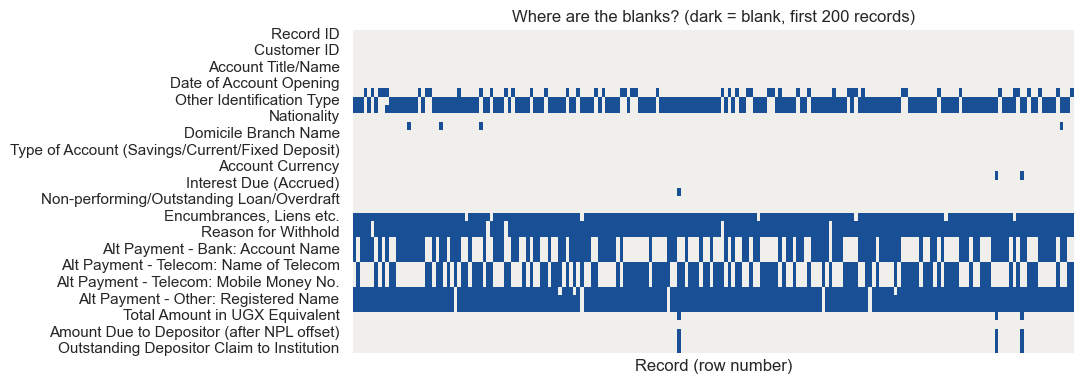

Most blanks are in optional fields (withholds, 'Other' payment, Other ID for Ugandans) - that is expected.


In [118]:
# A "missingness map": each row of the picture is a record, dark cells are blanks (first 200 records)
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(clean.head(200).isna().T, cbar=False, cmap=["#f0efec", "#184f95"], ax=ax)
ax.set_title("Where are the blanks? (dark = blank, first 200 records)")
ax.set_xlabel("Record (row number)")
ax.set_xticks([])
plt.tight_layout()
plt.show()
print("Most blanks are in optional fields (withholds, 'Other' payment, Other ID for Ugandans) - that is expected.")

### Disguised blanks — text that *means* missing
Values like `unknown`, `N/A` or `-` are not counted by `isna()`. Find them, then turn them into real blanks.

In [119]:
# 👀 LOOK: phone values that contain no digit at all
no_digit = ~clean["Contact Telephone Number"].str.contains(r"\d", na=True)
print(clean.loc[no_digit, "Contact Telephone Number"].value_counts())

Contact Telephone Number
unknown    2
none       1
Name: count, dtype: int64


In [120]:
PLACEHOLDERS = {"unknown", "n/a", "na", "-", "none", "null", "nil", "not available", ""}


def replace_placeholders(series):
    """Turn text that means 'missing' into a real blank (NaN)."""
    as_lower = series.astype("object").map(lambda v: str(v).strip().lower() if pd.notna(v) else v)
    return series.mask(as_lower.isin(PLACEHOLDERS))


before = clean.copy()
text_columns = ["Contact Telephone Number", "NI Number", "Other Identification Number",
                "Alt Payment - Telecom: Mobile Money No.", "Alt Payment - Bank: Account No."]
for column in text_columns:                                   # ✋ ACT
    clean[column] = replace_placeholders(clean[column])

n = compare(before, clean, "Contact Telephone Number", key="Record ID")      # ✅ CHECK
log_step("Disguised blanks -> NaN", "Contact Telephone Number", n)

'Contact Telephone Number': 3 of 1,064 values changed


,Record ID,Contact Telephone Number BEFORE,Contact Telephone Number AFTER
388,SCV00389,unknown,NaN
439,SCV00440,unknown,NaN
916,SCV00917,none,NaN


### Fill only where the blank has a documented meaning

In [121]:
# 👀 LOOK
print("Blank Withhold Amount    :", clean["Withhold Amount"].isna().sum())
print("Blank Encumbrances       :", clean["Encumbrances, Liens etc."].isna().sum())
print("Blank Reason for Withhold:", clean["Reason for Withhold"].isna().sum())

# ✋ ACT - blank means "none reported"
before = clean.copy()
clean["Withhold Amount"] = clean["Withhold Amount"].fillna(0)
clean["Encumbrances, Liens etc."] = clean["Encumbrances, Liens etc."].fillna(0)
clean["Reason for Withhold"] = clean["Reason for Withhold"].fillna("None reported")

# ✅ CHECK
for col in ["Withhold Amount", "Encumbrances, Liens etc.", "Reason for Withhold"]:
    changed = (before[col].isna() & clean[col].notna()).sum()
    log_step("Blank -> 'none reported' (documented)", col, int(changed))
    print(f"{col:<26} filled: {changed:>5}   still blank: {clean[col].isna().sum()}")
clean[["Record ID", "Withhold Amount", "Reason for Withhold"]].head(3)

Blank Withhold Amount    : 1028
Blank Encumbrances       : 1036
Blank Reason for Withhold: 1028
Withhold Amount            filled:  1028   still blank: 0
Encumbrances, Liens etc.   filled:  1036   still blank: 0
Reason for Withhold        filled:  1028   still blank: 0


,Record ID,Withhold Amount,Reason for Withhold
0,SCV00001,0.00,None reported
1,SCV00002,0.00,None reported
2,SCV00003,0.00,None reported


### ⚠️ Why we almost never `dropna()` regulatory data
`dropna()` removes every row that has **any** blank. Look at what it would do:

In [122]:
print("Rows now                               :", len(clean))
print("Rows left after clean.dropna()         :", len(clean.dropna()))
print("Rows left after dropna(subset=balance) :", len(clean.dropna(subset=["Current Balance"])))
print()
print("Dropping would make depositors disappear from DPF's exposure. We FLAG instead:")
clean["flag_balance_missing"] = clean["Current Balance"].isna()
look(clean[clean["flag_balance_missing"]], ["Record ID", "Contributing Institution", "Account Title/Name", "Current Balance"])

Rows now                               : 1064
Rows left after clean.dropna()         : 0
Rows left after dropna(subset=balance) : 1056

Dropping would make depositors disappear from DPF's exposure. We FLAG instead:
8 rows x 40 columns


,Record ID,Contributing Institution,Account Title/Name,Current Balance
178,SCV00179,Elgon Microfinance Deposit-Taking Institution,Moses Oryem,NaN
185,SCV00186,Elgon Microfinance Deposit-Taking Institution,Lillian Ssali,NaN
676,SCV00677,Nile Commercial Bank,Bunyoro Boda Boda SACCO,NaN
832,SCV00833,Rwenzori Savings Bank,Simon Lubega,NaN
897,SCV00898,Rwenzori Savings Bank,Aisha Kizza,NaN


> **What about imputation (filling with an average)?** It is useful for statistics and machine learning, but
> a *guessed* balance must never enter a payout. In this course we impute only inside models (Day 5).

## 2.2 String cleaning & standardisation

pandas text tools live behind `.str`. They work on the whole column at once:

In [123]:
demo = pd.Series(["  grace  NAMUBIRU ", "CF85-123456 abcd", "0772 123 456", None])
print(demo.str.strip().tolist())                      # remove spaces at both ends
print(demo.str.upper().tolist())                      # UPPER CASE
print(demo.str.replace(" ", "", regex=False).tolist())  # remove all spaces
print(demo.str.replace(r"\s+", " ", regex=True).str.strip().tolist())   # many spaces -> one (regex)
print(demo.str.len().tolist())                        # length
print(demo.str[0:2].tolist())                         # slicing, like nin[0:2]

['grace  NAMUBIRU', 'CF85-123456 abcd', '0772 123 456', None]
['  GRACE  NAMUBIRU ', 'CF85-123456 ABCD', '0772 123 456', None]
['graceNAMUBIRU', 'CF85-123456abcd', '0772123456', None]
['grace NAMUBIRU', 'CF85-123456 abcd', '0772 123 456', None]
[18.0, 16.0, 12.0, nan]
['  ', 'CF', '07', None]


### Names — trim spaces, and re-case only names typed ALL CAPS or all lower case
(We leave mixed-case names alone so we do not damage abbreviations like `SACCO` or `NGO`.)

In [124]:
def clean_name(name):
    if not filled(name):
        return name
    text = re.sub(r"\s+", " ", str(name)).strip()          # collapse repeated spaces
    if text.isupper() or text.islower():
        text = text.title()
    return text


before = clean.copy()
clean["Account Title/Name"] = clean["Account Title/Name"].apply(clean_name)
n = compare(before, clean, "Account Title/Name")
log_step("Trim / re-case names", "Account Title/Name", n)

'Account Title/Name': 9 of 1,064 values changed


,Account Title/Name BEFORE,Account Title/Name AFTER
10,EDWARD KAGIMU,Edward Kagimu
206,DOREEN AKELLO,Doreen Akello
296,FRED ASIIMWE,Fred Asiimwe
319,AGNES NALWOGA,Agnes Nalwoga
392,DOREEN NAMUBIRU,Doreen Namubiru
697,PHIONA TURYASINGURA,Phiona Turyasingura
833,HENRY OJOK,Henry Ojok
957,IBRAHIM KYOMUHENDO,Ibrahim Kyomuhendo


### NINs — fix the *format*, not the identity
Cleaning can remove spaces/dashes and fix lower case. It **cannot** invent a missing character or fix a
wrong prefix — those go back to the bank.

In [125]:
def clean_nin(nin):
    """Remove spaces and dashes and make upper case. Blank stays blank."""
    if not filled(nin):
        return np.nan
    return str(nin).replace(" ", "").replace("-", "").upper()


# 👀 LOOK
problems_before = clean["NI Number"].apply(nin_problem)

# ✋ ACT
before = clean.copy()
clean["NI Number"] = clean["NI Number"].apply(clean_nin)

# ✅ CHECK
n = compare(before, clean, "NI Number", key="Record ID")
log_step("Clean NIN format", "NI Number", n)
problems_after = clean["NI Number"].apply(nin_problem)

has_nin = clean["NI Number"].notna()
print("\nNIN problems among records that HAVE a NIN:")
print(pd.DataFrame({"before": problems_before[has_nin].replace("", "OK").value_counts(),
                    "after": problems_after[has_nin].replace("", "OK").value_counts()}).fillna(0).astype(int))

'NI Number': 18 of 1,064 values changed


,Record ID,NI Number BEFORE,NI Number AFTER
45,SCV00046,CF50732609ZWCU,CF50732609ZWCU
48,SCV00049,cm82734010wnew,CM82734010WNEW
63,SCV00064,CM06515-549OVOM,CM06515549OVOM
112,SCV00113,CF64537-275XYMM,CF64537275XYMM
163,SCV00164,cf67807666lvuj,CF67807666LVUJ
369,SCV00370,CM 66013101ASIZ,CM66013101ASIZ
389,SCV00390,cm58398282jsbx,CM58398282JSBX
470,SCV00471,cf73749354djze,CF73749354DJZE



NIN problems among records that HAVE a NIN:
                              before  after
NI Number                                  
OK                               749    767
contains spaces or dashes          8      0
lower-case letters                10      0
must start with CM or CF           6      6
wrong length (13 characters)       7      7
wrong length (15 characters)       5      5


### 📞 Case Study 2A — Phones: standardise when sure, flag when not

| Received | Result | Why |
|---|---|---|
| `+256772123456` | `+256772123456` | already correct |
| `256772123456` | `+256772123456` | add `+` |
| `0772123456` / `0772 123 456` | `+256772123456` | Ugandan local format → country code |
| `772123456` | `+256772123456` | Excel dropped the leading 0 (9 digits) |
| `07712`, `unknown` | *blank + flag* | cannot be fixed with confidence |

In [126]:
def standardise_phone(phone):
    """Return a phone in +<country code> format, or NaN if it cannot be fixed with confidence."""
    if not filled(phone):
        return np.nan
    text = str(phone).replace(" ", "").replace("-", "")
    if text.endswith(".0"):                       # numbers read from Excel as decimals
        text = text[:-2]
    if text.startswith("+") and text[1:].isdigit() and 11 <= len(text) - 1 <= 13:
        return text                               # already international (Uganda or elsewhere)
    if not text.isdigit():
        return np.nan
    if text.startswith("256") and len(text) == 12:
        return "+" + text
    if text.startswith("0") and len(text) == 10:
        return "+256" + text[1:]
    if text.startswith("7") and len(text) == 9:
        return "+256" + text
    return np.nan


for test in ["+256772123456", "256772123456", "0772 123 456", "772123456", "07712", "+254712345678", None]:
    print(f"{str(test):<16} -> {standardise_phone(test)}")

+256772123456    -> +256772123456
256772123456     -> +256772123456
0772 123 456     -> +256772123456
772123456        -> +256772123456
07712            -> nan
+254712345678    -> +254712345678
None             -> nan


In [127]:
# ✋ ACT on the contact phone and the mobile-money number
before = clean.copy()
for column in ["Contact Telephone Number", "Alt Payment - Telecom: Mobile Money No."]:
    clean[column] = clean[column].apply(standardise_phone)

# ✅ CHECK
n = compare(before, clean, "Contact Telephone Number", key="Record ID")
log_step("Standardise phone", "Contact Telephone Number", n)
n = compare(before, clean, "Alt Payment - Telecom: Mobile Money No.", n=4)
log_step("Standardise phone", "Alt Payment - Telecom: Mobile Money No.", n)

clean["flag_phone_unfixable"] = before["Contact Telephone Number"].notna() & clean["Contact Telephone Number"].isna()
print("Phones that could NOT be fixed (sent back to the bank):", clean["flag_phone_unfixable"].sum())

'Contact Telephone Number': 76 of 1,064 values changed


,Record ID,Contact Telephone Number BEFORE,Contact Telephone Number AFTER
1,SCV00002,0778500051,+256778500051
11,SCV00012,0742057261,+256742057261
28,SCV00029,0727474,NaN
36,SCV00037,0758693947,+256758693947
56,SCV00057,+256 764 270 864,+256764270864
82,SCV00083,0756752458,+256756752458
110,SCV00111,256785910952,+256785910952
114,SCV00115,0767718567,+256767718567


'Alt Payment - Telecom: Mobile Money No.': 8 of 1,064 values changed


,Alt Payment - Telecom: Mobile Money No. BEFORE,Alt Payment - Telecom: Mobile Money No. AFTER
12,074242,NaN
120,074612,NaN
375,+256789951,NaN
441,070238,NaN


Phones that could NOT be fixed (sent back to the bank): 6


### Telecom and bank names — many spellings, one standard

In [128]:
# 👀 LOOK
print(clean["Alt Payment - Telecom: Name of Telecom"].value_counts(dropna=False))

Alt Payment - Telecom: Name of Telecom
NaN              519
MTN              155
Airtel           117
mtn               62
MTN MoMo          53
MTN Uganda        47
Airtl             40
AIRTEL MONEY      38
Airtel Uganda     33
Name: count, dtype: int64


In [129]:
MTN_PREFIXES = ["77", "78", "76"]
AIRTEL_PREFIXES = ["70", "75", "74"]


def standardise_telecom(name):
    if not filled(name):
        return np.nan
    text = str(name).strip().lower()
    if "mtn" in text:
        return "MTN"
    if text.startswith("air"):
        return "Airtel"
    return "Unknown"


def telecom_from_number(number):
    """Which network does a +256 number belong to, judging by its prefix?"""
    if not filled(number) or not str(number).startswith("+256"):
        return np.nan
    prefix = str(number)[4:6]
    if prefix in MTN_PREFIXES:
        return "MTN"
    if prefix in AIRTEL_PREFIXES:
        return "Airtel"
    return "Unknown"


before = clean.copy()
clean["Alt Payment - Telecom: Name of Telecom"] = clean["Alt Payment - Telecom: Name of Telecom"].apply(standardise_telecom)
n = compare(before, clean, "Alt Payment - Telecom: Name of Telecom", n=5)
log_step("Standardise telecom names", "Alt Payment - Telecom: Name of Telecom", n)
print(clean["Alt Payment - Telecom: Name of Telecom"].value_counts(dropna=False))

'Alt Payment - Telecom: Name of Telecom': 273 of 1,064 values changed


,Alt Payment - Telecom: Name of Telecom BEFORE,Alt Payment - Telecom: Name of Telecom AFTER
0,Airtel Uganda,Airtel
3,Airtl,Airtel
12,MTN MoMo,MTN
13,mtn,MTN
16,AIRTEL MONEY,Airtel


Alt Payment - Telecom: Name of Telecom
NaN       519
MTN       317
Airtel    228
Name: count, dtype: int64


In [130]:
# 👀 LOOK - how banks type the alternative bank's name
clean["Alt Payment - Bank: Name of Institution"].value_counts()

Alt Payment - Bank: Name of Institution
Victoria Cooperative Bank                        80
Lake Kyoga Bank                                  75
Nile Commercial Bank                             52
Rwenzori Savings Bank                            52
Elgon Microfinance Deposit-Taking Institution    46
Kagera Trust Bank                                37
Lake Kyoga Bank Ltd                              19
Victoria Co-operative Bank                       11
KTB                                              11
LKB                                              10
Nile Commercial Bank Ltd                          9
Rwenzori Savings                                  9
Kagera Trust Bank Ltd                             8
kagera trust                                      7
EMD                                               6
nile commercial bank                              6
Elgon Microfinance                                5
NCB                                               4
Elgon MDI               

In [131]:
# One dictionary translates every known spelling into an institution code
BANK_ALIASES = {
    "nile commercial bank": "NCB", "nile commercial": "NCB", "ncb": "NCB",
    "rwenzori savings bank": "RSB", "rwenzori savings": "RSB", "rsb": "RSB",
    "elgon microfinance deposit taking institution": "EMD", "elgon microfinance": "EMD",
    "elgon mdi": "EMD", "emd": "EMD",
    "kagera trust bank": "KTB", "kagera trust": "KTB", "ktb": "KTB",
    "victoria cooperative bank": "VCB", "victoria co operative bank": "VCB", "vcb": "VCB",
    "lake kyoga bank": "LKB", "lkb": "LKB",
}


def bank_code(name):
    """Normalise a bank name and look it up. Returns a code, 'UNKNOWN', or NaN if blank."""
    if not filled(name):
        return np.nan
    text = str(name).lower().replace("-", " ").replace(".", " ")
    text = re.sub(r"\b(ltd|limited|plc)\b", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return BANK_ALIASES.get(text, "UNKNOWN")


clean["institution_code"] = clean["Contributing Institution"].apply(bank_code)
clean["alt_bank_code"] = clean["Alt Payment - Bank: Name of Institution"].apply(bank_code)

print(clean["institution_code"].value_counts(), "\n")
print(clean["alt_bank_code"].value_counts(dropna=False))

institution_code
NCB    331
RSB    259
KTB    238
EMD    236
Name: count, dtype: int64 

alt_bank_code
NaN    605
LKB    104
VCB     94
NCB     71
RSB     66
KTB     63
EMD     61
Name: count, dtype: int64


### Currencies and dates

In [132]:
VALID_CURRENCIES = ["UGX", "USD", "EUR", "GBP", "KES"]
CURRENCY_SYNONYMS = {"US$": "USD", "USD$": "USD", "EURO": "EUR", "UGS": "UGX", "USH": "UGX", "SHS": "UGX"}


def standardise_currency(code):
    if not filled(code):
        return np.nan
    text = str(code).strip().upper()
    text = CURRENCY_SYNONYMS.get(text, text)
    return text if text in VALID_CURRENCIES else "INVALID"


print(clean["Account Currency"].value_counts())       # 👀 LOOK
before = clean.copy()
clean["Account Currency"] = clean["Account Currency"].apply(standardise_currency)    # ✋ ACT
n = compare(before, clean, "Account Currency")       # ✅ CHECK
log_step("Standardise currency codes", "Account Currency", n)

Account Currency
UGX     934
USD      90
EUR      26
KES       4
GBP       3
Euro      3
UGS       2
Ush       1
usd       1
Name: count, dtype: int64
'Account Currency': 7 of 1,064 values changed


,Account Currency BEFORE,Account Currency AFTER
15,UGS,UGX
134,Ush,UGX
191,Euro,EUR
261,UGS,UGX
424,Euro,EUR
602,Euro,EUR
742,usd,USD


In [133]:
REPORTING_DATE = pd.Timestamp("2026-09-30")
dob = clean["Date of Birth /Registration/Formation"]
opened = clean["Date of Account Opening"]
is_person = clean["Client Type"].isin(["Individual Account", "Joint Account"])

clean["flag_date_problem"] = (
    (dob > REPORTING_DATE)                                            # born / registered in the future
    | (is_person & (dob < REPORTING_DATE - pd.DateOffset(years=110)))  # older than 110
    | (opened < dob)                                                  # opened before birth / registration
    | (opened > REPORTING_DATE)                                       # opened after the reporting date
)
print("Records with an impossible date:", clean["flag_date_problem"].sum())
display(clean.loc[clean["flag_date_problem"], ["Record ID", "Client Type", "Date of Birth /Registration/Formation",
                                                "Date of Account Opening"]].head(6))

# The Guidelines ask for dd-mm-yyyy. Keep real dates inside Python; format only when you SHOW or EXPORT:
print(dob.head(3).dt.strftime("%d-%m-%Y").tolist())

Records with an impossible date: 12


,Record ID,Client Type,Date of Birth /Registration/Formation,Date of Account Opening
72,SCV00073,Individual Account,1896-01-01,1998-12-02
138,SCV00139,Individual Account,2031-04-12,2013-06-28
325,SCV00326,Company Account,1997-10-27,1995-10-27
350,SCV00351,Company Account,1999-02-17,1997-02-17
501,SCV00502,Individual Account,2031-04-12,2012-12-14
512,SCV00513,Individual Account,1957-03-22,1955-03-22


['05-10-2002', '25-01-1960', '24-09-1976']


## 2.3 Duplicates and mismatched records

### 🔎 Case Study 2B — Duplicate does not automatically mean fraud
A repeated row may be an export glitch; one account number for two names may be a typing error or worse.
The workflow is always **flag → investigate → document → resolve**.

### Exact duplicate rows
⚠️ Every row has its own `Record ID`, so a duplicated export row is **not** identical in every column.
We compare all columns *except* `Record ID`.

In [134]:
compare_columns = [c for c in raw_scv.columns if c != "Record ID"]

# 👀 LOOK
is_dup = clean.duplicated(subset=compare_columns, keep=False)
print("Rows that appear more than once:", is_dup.sum())
display(clean.loc[is_dup, ["Record ID", "Account Title/Name", "Account Number", "Current Balance"]]
        .sort_values("Account Number").head(6))

# ✋ ACT - keep the first copy, remember which Record IDs were removed (audit trail)
rows_before = len(clean)
removed_ids = clean.loc[clean.duplicated(subset=compare_columns, keep="first"), "Record ID"].tolist()
clean = clean.drop_duplicates(subset=compare_columns, keep="first").reset_index(drop=True)

# ✅ CHECK
print(f"Rows before: {rows_before}  after: {len(clean)}  removed: {len(removed_ids)} -> {removed_ids}")
log_step("Drop exact duplicate rows", "(whole row)", len(removed_ids))

Rows that appear more than once: 12


,Record ID,Account Title/Name,Account Number,Current Balance
566,SCV00567,Njeri Kamau,0121563375167,"1,146.90"
631,SCV00632,Njeri Kamau,0121563375167,"1,146.90"
831,SCV00832,Majok Malual,3082905429,"726,197.79"
992,SCV00993,Majok Malual,3082905429,"726,197.79"
853,SCV00854,Stella Ssali,3739682759,"6,180,258.18"
1059,SCV01060,Stella Ssali,3739682759,"6,180,258.18"


Rows before: 1064  after: 1058  removed: 6 -> ['SCV00104', 'SCV00397', 'SCV00430', 'SCV00632', 'SCV00993', 'SCV01060']


In [135]:
# One account number, two different names, inside the same institution -> flag (do NOT drop)
same_account = clean.groupby(["institution_code", "Account Number"])["Account Title/Name"].transform("nunique") > 1
clean["flag_account_number_clash"] = same_account
display(clean.loc[same_account, ["Record ID", "Contributing Institution", "Account Number", "Account Title/Name"]]
        .sort_values("Account Number"))

,Record ID,Contributing Institution,Account Number,Account Title/Name
487,SCV00491,Nile Commercial Bank,0107778793432,Grace Nansubuga
771,SCV00776,Nile Commercial Bank,0107778793432,Rose Nsubuga
832,SCV00837,Rwenzori Savings Bank,3310172783,Hassan Nantongo
965,SCV00970,Rwenzori Savings Bank,3310172783,Joseph Wasswa
286,SCV00288,Kagera Trust Bank,915255992118,Juliet Kusiima
425,SCV00428,Kagera Trust Bank,915255992118,Derrick Acen


### Mismatched NINs — two kinds

1. **Birth-year mismatch:** characters 3–4 of the NIN should equal the last two digits of the birth year.
2. **One NIN, two different people:** the same NIN appears with different dates of birth — almost always a
   copy/paste error, and dangerous: it would *merge two people's money* on Day 3.

To compare names fairly we build a **name key**: upper case, punctuation removed, words sorted — so
`Grace Namubiru`, `NAMUBIRU GRACE` and `Namubiru, Grace` all become `GRACE NAMUBIRU`.

In [136]:
def name_key(name):
    if not filled(name):
        return ""
    words = re.sub(r"[^A-Za-z ]", " ", str(name)).upper().split()
    return " ".join(sorted(words))


def name_similarity(a, b):
    """0 = completely different, 1 = identical (after building the name key)."""
    return round(SequenceMatcher(None, name_key(a), name_key(b)).ratio(), 2)


for a, b in [("Grace Namubiru", "NAMUBIRU GRACE"), ("Grace Namubiru", "Namubiru, Grace"),
             ("Grace Namubiru", "Grace Nambiru"), ("Grace Namubiru", "Moses Okello")]:
    print(f"{a:<16} vs {b:<16} key: {name_key(b):<16} similarity: {name_similarity(a, b)}")

Grace Namubiru   vs NAMUBIRU GRACE   key: GRACE NAMUBIRU   similarity: 1.0
Grace Namubiru   vs Namubiru, Grace  key: GRACE NAMUBIRU   similarity: 1.0
Grace Namubiru   vs Grace Nambiru    key: GRACE NAMBIRU    similarity: 0.96
Grace Namubiru   vs Moses Okello     key: MOSES OKELLO     similarity: 0.15


In [137]:
person = clean["Client Type"].isin(["Individual Account", "Joint Account"])
valid_nin = clean["NI Number"].apply(nin_problem) == ""

# 1) Birth-year mismatch (vectorised: .str[2:4] slices every NIN at once)
nin_year = clean["NI Number"].str[2:4]
dob_year = clean["Date of Birth /Registration/Formation"].dt.strftime("%y")
clean["flag_nin_birthyear_mismatch"] = person & valid_nin & (nin_year != dob_year)

# 2) Same NIN, different dates of birth
dob_per_nin = clean[person & valid_nin].groupby("NI Number")["Date of Birth /Registration/Formation"].nunique()
shared_nins = dob_per_nin[dob_per_nin > 1].index
clean["flag_nin_shared_by_different_people"] = person & clean["NI Number"].isin(shared_nins)

print("NIN birth-year mismatches     :", clean["flag_nin_birthyear_mismatch"].sum())
print("Records whose NIN is shared by different people:", clean["flag_nin_shared_by_different_people"].sum())
clean.loc[clean["flag_nin_shared_by_different_people"],
          ["Record ID", "Contributing Institution", "Account Title/Name", "NI Number",
           "Date of Birth /Registration/Formation"]].sort_values("NI Number").head(8)

NIN birth-year mismatches     : 21
Records whose NIN is shared by different people: 23


,Record ID,Contributing Institution,Account Title/Name,NI Number,Date of Birth /Registration/Formation
750,SCV00755,Nile Commercial Bank,Immaculate Wasswa,CF52314879GHZA,1952-02-20
660,SCV00665,Nile Commercial Bank,Immaculate Wasswa and Godfrey Ssemakula,CF52314879GHZA,1952-02-20
191,SCV00193,Elgon Microfinance Deposit-Taking Institution,Immaculate Wasswa,CF52314879GHZA,1952-02-20
200,SCV00202,Elgon Microfinance Deposit-Taking Institution,Immaculate Wasswa,CF52314879GHZA,1952-02-20
812,SCV00817,Rwenzori Savings Bank,Hassan Bwambale,CF52314879GHZA,1993-07-02
442,SCV00446,Kagera Trust Bank,Rose Opio,CF73428676RHPO,1984-01-25
259,SCV00261,Kagera Trust Bank,Olivia Tumusiime,CF73428676RHPO,1973-10-12
787,SCV00792,Nile Commercial Bank,Allan Ninsiima,CF80590757HZXF,2002-07-09


In [138]:
# Same NIN with different spellings of the name (same date of birth) -> same person, different banks
same_person = clean[person & valid_nin & ~clean["flag_nin_shared_by_different_people"]].copy()
names_per_nin = same_person.groupby("NI Number")["Account Title/Name"].nunique()
variant_nins = names_per_nin[names_per_nin > 1].index[:6]
variants = same_person[same_person["NI Number"].isin(variant_nins)][
    ["NI Number", "Contributing Institution", "Account Title/Name"]].sort_values("NI Number")
variants["name key"] = variants["Account Title/Name"].apply(name_key)
variants

,NI Number,Contributing Institution,Account Title/Name,name key
156,CF03696525PAMT,Elgon Microfinance Deposit-Taking Institution,Sharon Nabukenya and Joan Wandera,AND JOAN NABUKENYA SHARON WANDERA
288,CF03696525PAMT,Kagera Trust Bank,Sharon Nabukenya,NABUKENYA SHARON
536,CF04371846RGBW,Nile Commercial Bank,Gloria Kiggundu and Emmanuel Okello,AND EMMANUEL GLORIA KIGGUNDU OKELLO
613,CF04371846RGBW,Nile Commercial Bank,Gloria Kiggundu,GLORIA KIGGUNDU
642,CF04371846RGBW,Nile Commercial Bank,Gloria Kiggundu,GLORIA KIGGUNDU
1034,CF04470625TNBQ,Rwenzori Savings Bank,Stella Opio,OPIO STELLA
448,CF04470625TNBQ,Kagera Trust Bank,Stella Opio,OPIO STELLA
888,CF04470625TNBQ,Rwenzori Savings Bank,Opio Stella,OPIO STELLA
184,CF50077557NDYV,Elgon Microfinance Deposit-Taking Institution,Lillian Ssali,LILLIAN SSALI
228,CF50077557NDYV,Elgon Microfinance Deposit-Taking Institution,Lillian Ssali,LILLIAN SSALI


## 2.4 Merging and joining

`pd.merge(left, right, on=..., how=...)` works like Excel's VLOOKUP/XLOOKUP, but for whole tables.

| `how=` | Keeps | Use when |
|---|---|---|
| `"left"` | every row of the left table | adding information (region, FX rate) without losing records |
| `"inner"` | only rows found in both | you really want the overlap |
| `"outer"` | everything from both | reconciling two lists |

Add `indicator=True` to see which rows found a match.

In [139]:
branches = pd.read_excel(DATA_FILE, sheet_name="Lookup_Branches")
institutions = pd.read_excel(DATA_FILE, sheet_name="Lookup_Institutions")
fx_rates = pd.read_excel(DATA_FILE, sheet_name="Lookup_FX_Rates")
display(branches.head(3))

# ✋ ACT - add region and coordinates to every record
rows_before = len(clean)
clean = clean.merge(branches, left_on="Domicile Branch Name", right_on="Branch", how="left", indicator=True)

# ✅ CHECK - same number of rows, and every branch found
print("Rows before:", rows_before, " after:", len(clean))
print(clean["_merge"].value_counts())
clean = clean.drop(columns=["Branch", "_merge"])

,Branch,Region,Latitude,Longitude
0,Kampala Main,Central,0.31,32.58
1,Jinja,Eastern,0.42,33.20
2,Mbale,Eastern,1.08,34.17


Rows before: 1058  after: 1058
_merge
both          1058
left_only        0
right_only       0
Name: count, dtype: int64


### Seeing the same depositor across banks
Many depositors hold accounts in **more than one** institution. That matters twice:
- each failed institution is assessed separately, so DPF must know which accounts are in *which* bank;
- an account in a **healthy** bank is an excellent route to pay a depositor of a **failed** bank.

In [140]:
nin_banks = clean[person & valid_nin].groupby("NI Number")["institution_code"].nunique()
print("Individuals/joint holders (by NIN) in 1, 2, 3+ institutions:")
print(nin_banks.value_counts().sort_index())

company = clean["Client Type"] == "Company Account"
reg_banks = clean[company].groupby("Other Identification Number")["institution_code"].nunique()
print("\nCompanies (by registration number) in 1, 2, 3+ institutions:")
print(reg_banks.value_counts().sort_index())

example_nin = nin_banks[nin_banks >= 2].index[0]
clean.loc[clean["NI Number"] == example_nin, ["NI Number", "Contributing Institution", "Account Title/Name",
                                               "Account Number", "Type of Account (Savings/Current/Fixed Deposit)",
                                               "Current Balance", "Alt Payment - Bank: Name of Institution",
                                               "Alt Payment - Bank: Account No."]]

Individuals/joint holders (by NIN) in 1, 2, 3+ institutions:
institution_code
1    335
2    102
3     19
4      1
Name: count, dtype: int64

Companies (by registration number) in 1, 2, 3+ institutions:
institution_code
1    37
2    31
3     2
Name: count, dtype: int64


,NI Number,Contributing Institution,Account Title/Name,Account Number,Type of Account (Savings/Current/Fixed Deposit),Current Balance,Alt Payment - Bank: Name of Institution,Alt Payment - Bank: Account No.
47,CF00478755TAZT,Elgon Microfinance Deposit-Taking Institution,Olivia Ssali,EMD50364698,Savings,"578,642.14",Kagera Trust Bank Ltd,959055188890
206,CF00478755TAZT,Elgon Microfinance Deposit-Taking Institution,Olivia Ssali,EMD72268954,Fixed Deposit,"3,771,686.73",KTB,959055188890
260,CF00478755TAZT,Kagera Trust Bank,Olivia Ssali,959055188890,Savings,"8,064,378.55",NaN,NaN


In [141]:
# A SELF-MERGE: join the table to itself on NIN, then keep pairs from DIFFERENT institutions.
accounts = clean.loc[person & valid_nin, ["Record ID", "NI Number", "institution_code", "Account Number"]]
pairs = accounts.merge(accounts, on="NI Number", suffixes=("", "_other"))
pairs = pairs[pairs["institution_code"] != pairs["institution_code_other"]]

records_with_other_bank = pairs["Record ID"].nunique()
print(f"{records_with_other_bank} records belong to a depositor who also has an account in another contributing bank.")
pairs.head(5)

301 records belong to a depositor who also has an account in another contributing bank.


,Record ID,NI Number,institution_code,Account Number,Record ID_other,institution_code_other,Account Number_other
11,SCV00007,CM81365549UZEW,EMD,EMD54026023,SCV00743,NCB,0166167673202
12,SCV00007,CM81365549UZEW,EMD,EMD54026023,SCV00888,RSB,3761132547
13,SCV00743,CM81365549UZEW,NCB,0166167673202,SCV00007,EMD,EMD54026023
15,SCV00743,CM81365549UZEW,NCB,0166167673202,SCV00888,RSB,3761132547
16,SCV00888,CM81365549UZEW,RSB,3761132547,SCV00007,EMD,EMD54026023


### 🏛️ Case Study 2C — Four banks, four dialects

Bank A calls the name `FullName`, Bank B `CustomerName`, Bank C `Name`, Bank D `Depositor Full Name`.
Dates arrive as `18.03.1958`, `1958/03/18`, `March 18, 1958` and `18/03/1958`. One bank sends balances in
**thousands**, another sends them as **text with commas**. The computer only knows these mean the same thing
if we tell it — once, in code that can be re-run every month.

## 2.5 Lab: consolidating the four raw exports

### 👀 LOOK at each export first

In [142]:
raw_exports = {}
for sheet in ["RawExport_BankA", "RawExport_BankB", "RawExport_BankC", "RawExport_BankD"]:
    raw_exports[sheet] = pd.read_excel(DATA_FILE, sheet_name=sheet, dtype=str)   # read EVERYTHING as text first
    print(f"--- {sheet}: {raw_exports[sheet].shape}")
    print(list(raw_exports[sheet].columns))
display(raw_exports["RawExport_BankA"].head(3))

--- RawExport_BankA: (70, 10)
['FullName', 'DOB', 'ClientCode', 'NIN', 'Phone', 'Branch', 'AccNo', 'Bal', 'Ccy', 'AltChannel']
--- RawExport_BankB: (65, 12)
['CustomerName', 'CustType', 'DateOfBirth', 'NationalID', 'MobileNo', 'BranchName', 'AccountNo', 'CurrentBal', 'Currency', 'AltBankName', 'AltBankAccNo', 'InternalStatus']
--- RawExport_BankC: (60, 13)
['Name', 'Category', 'BirthDate', 'IDNumber', 'Nationality', 'Tel', 'Location', 'Acc', 'Bal', 'Cur', 'MMProvider', 'MMRegName', 'MMNumber']
--- RawExport_BankD: (65, 12)
['Depositor Full Name', 'Depositor Category', 'D.O.B', 'National ID / Passport No', 'Telephone', 'Branch', 'Acct No', "Balance ('000)", 'Currency Code', 'Bank Name for Alt Payment', 'Alt Acct Name', 'Alt Acct No']


,FullName,DOB,ClientCode,NIN,Phone,Branch,AccNo,Bal,Ccy,AltChannel
0,PAUL OGWANG,19.01.1956,IND,CM56925531VNBQ,NaN,Masaka,185931551774,1596747.7,UGX,NaN
1,BRIAN SSEMAKULA,13.11.1983,IND,XM83898191UAVX,256777699736,Kampala Main,100300181949,3387966.17,UGX,BANK:KTB|920165507940
2,EDWARD KAGIMU,05.08.1999,IND,CM96249265IEOI,256783086432,Kampala Main,131604363589,5099212.28,UGX,mtn:+256783086432


In [143]:
for sheet in ["RawExport_BankB", "RawExport_BankC", "RawExport_BankD"]:
    display(raw_exports[sheet].head(2))

,CustomerName,CustType,DateOfBirth,NationalID,MobileNo,BranchName,AccountNo,CurrentBal,Currency,AltBankName,AltBankAccNo,InternalStatus
0,"Stella, Opio",Individual,2004/04/17,CF04470625TNBQ,+256740216402,arua,3463658961,7502797.57,UGX,KTB,987107957783,ACTIVE
1,"Nabukenya, Collins",Individual,1983/01/13,CM83713659ZGKG,+256772272722,masaka,3566219565,11582906.44,UGX,NaN,NaN,ACTIVE


,Name,Category,BirthDate,IDNumber,Nationality,Tel,Location,Acc,Bal,Cur,MMProvider,MMRegName,MMNumber
0,Juliet Mukasa,Individual Account,"November 05, 1954",CF54094029TJJZ,Uganda,+256762675364,Kampala Main,EMD72596413,"353,164.40",UGX,NaN,NaN,NaN
1,Simon Ssemakula,Individual Account,"March 27, 1982",CM82734010WNE,Uganda,+256768937958,Kampala Main,EMD27515935,"835,668.04",UGX,NaN,NaN,NaN


,Depositor Full Name,Depositor Category,D.O.B,National ID / Passport No,Telephone,Branch,Acct No,Balance ('000),Currency Code,Bank Name for Alt Payment,Alt Acct Name,Alt Acct No
0,Lango Investment Club,Corporate,03/04/2019,80024006811899,+256312698977,Jinja,903067205174,58210.458,ugx,Lake Kyoga Bank Ltd,Lango Investment Club,48516463379
1,Mercy Auma,Personal,24/07/1980,CF80774804RPKX,+256786476427,Fort Portal,958359361510,254.649,ugx,NaN,NaN,NaN


**What we notice**
- Bank A: names in CAPITALS; account numbers lost their leading `0` (their system stored them as numbers);
  the alternative channel is packed into one text like `MTN:+256772…` or `BANK:Lake Kyoga Bank|4…`.
- Bank B: names written `Surname, First`; dates `yyyy/mm/dd`; an extra `InternalStatus` column.
- Bank C: dates like `March 18, 1958`; balances are **text with commas**; NIN and passport share one column; no exchange rate.
- Bank D: balance is in **thousands** (`'000`); currency codes in lower case.

### ✋ ACT — one small "prepare" function per bank, then one shared mapping function

In [144]:
TARGET_COLUMNS = pd.read_excel(DATA_FILE, sheet_name="Target_Schema")["Target Field"].tolist()
print("Target schema:", TARGET_COLUMNS)


def split_id(value):
    """Bank C and D put NIN and passport/registration numbers in one column - separate them."""
    cleaned = clean_nin(value)
    if filled(cleaned) and str(cleaned)[0:2] in ["CM", "CF"]:
        return pd.Series({"NI Number": cleaned, "Other Identification Number": np.nan})
    return pd.Series({"NI Number": np.nan, "Other Identification Number": value})


def prepare_bank_a(df):
    df = df.copy()
    df["FullName"] = df["FullName"].apply(clean_name)
    df["AccNo"] = df["AccNo"].str.zfill(13)                      # put back the lost leading zero(s)
    df["DOB"] = pd.to_datetime(df["DOB"], format="%d.%m.%Y", errors="coerce")
    df["ClientCode"] = df["ClientCode"].map({"IND": "Individual Account", "JNT": "Joint Account",
                                             "COR": "Company Account", "TRS": "Trust Account"})
    # "MTN:+2567..."  or  "BANK:Lake Kyoga Bank|4123..."
    parts = df["AltChannel"].str.split(":", n=1, expand=True)
    is_bank = parts[0] == "BANK"
    bank_parts = parts[1].where(is_bank).str.split("|", n=1, expand=True)
    df["AltBank"] = bank_parts[0]
    df["AltBankAcc"] = bank_parts[1]
    df["AltTelecom"] = parts[0].where(~is_bank)
    df["AltMM"] = parts[1].where(~is_bank)
    return df


def prepare_bank_b(df):
    df = df.copy()
    is_individual = df["CustType"] == "Individual"
    swapped = df["CustomerName"].str.split(", ", n=1).str[::-1].str.join(" ")    # "Okello, Moses" -> "Moses Okello"
    df["CustomerName"] = swapped.where(is_individual, df["CustomerName"])
    df["DateOfBirth"] = pd.to_datetime(df["DateOfBirth"], format="%Y/%m/%d", errors="coerce")
    df["BranchName"] = df["BranchName"].str.title()
    df["CustType"] = df["CustType"] + " Account"
    return df


def prepare_bank_c(df):
    df = df.copy()
    df["BirthDate"] = pd.to_datetime(df["BirthDate"], format="%B %d, %Y", errors="coerce")
    df["Bal"] = pd.to_numeric(df["Bal"].str.replace(",", "", regex=False), errors="coerce")
    df[["NI Number", "Other Identification Number"]] = df["IDNumber"].apply(split_id)
    return df


def prepare_bank_d(df):
    df = df.copy()
    df["D.O.B"] = pd.to_datetime(df["D.O.B"], format="%d/%m/%Y", errors="coerce")
    df["Balance ('000)"] = pd.to_numeric(df["Balance ('000)"], errors="coerce") * 1000   # thousands -> full units
    df["Currency Code"] = df["Currency Code"].str.upper()
    df["Depositor Category"] = df["Depositor Category"].map({"Personal": "Individual Account", "Joint": "Joint Account",
                                                             "Corporate": "Company Account", "Trust": "Trust Account"})
    df[["NI Number", "Other Identification Number"]] = df["National ID / Passport No"].apply(split_id)
    return df


print("Prepare functions defined.")

Target schema: ['Contributing Institution', 'Client Type', 'Account Title/Name', 'Date of Birth /Registration/Formation', 'NI Number', 'Other Identification Number', 'Nationality', 'Contact Telephone Number', 'Domicile Branch Name', 'Account Number', 'Account Currency', 'Current Balance', 'Alt Payment - Bank: Name of Institution', 'Alt Payment - Bank: Account No.', 'Alt Payment - Telecom: Name of Telecom', 'Alt Payment - Telecom: Registered Name', 'Alt Payment - Telecom: Mobile Money No.']
Prepare functions defined.


In [145]:
# {bank's column name: DPF target column name}
MAPPINGS = {
    "RawExport_BankA": {"FullName": "Account Title/Name", "ClientCode": "Client Type",
                        "DOB": "Date of Birth /Registration/Formation", "NIN": "NI Number",
                        "Phone": "Contact Telephone Number", "Branch": "Domicile Branch Name",
                        "AccNo": "Account Number", "Bal": "Current Balance", "Ccy": "Account Currency",
                        "AltBank": "Alt Payment - Bank: Name of Institution",
                        "AltBankAcc": "Alt Payment - Bank: Account No.",
                        "AltTelecom": "Alt Payment - Telecom: Name of Telecom",
                        "AltMM": "Alt Payment - Telecom: Mobile Money No."},
    "RawExport_BankB": {"CustomerName": "Account Title/Name", "CustType": "Client Type",
                        "DateOfBirth": "Date of Birth /Registration/Formation", "NationalID": "NI Number",
                        "MobileNo": "Contact Telephone Number", "BranchName": "Domicile Branch Name",
                        "AccountNo": "Account Number", "CurrentBal": "Current Balance", "Currency": "Account Currency",
                        "AltBankName": "Alt Payment - Bank: Name of Institution",
                        "AltBankAccNo": "Alt Payment - Bank: Account No."},
                        # "InternalStatus" has no home in the target schema -> it will be left out
    "RawExport_BankC": {"Name": "Account Title/Name", "Category": "Client Type",
                        "BirthDate": "Date of Birth /Registration/Formation", "Nationality": "Nationality",
                        "Tel": "Contact Telephone Number", "Location": "Domicile Branch Name",
                        "Acc": "Account Number", "Bal": "Current Balance", "Cur": "Account Currency",
                        "MMProvider": "Alt Payment - Telecom: Name of Telecom",
                        "MMRegName": "Alt Payment - Telecom: Registered Name",
                        "MMNumber": "Alt Payment - Telecom: Mobile Money No."},
    "RawExport_BankD": {"Depositor Full Name": "Account Title/Name", "Depositor Category": "Client Type",
                        "D.O.B": "Date of Birth /Registration/Formation", "Telephone": "Contact Telephone Number",
                        "Branch": "Domicile Branch Name", "Acct No": "Account Number",
                        "Balance ('000)": "Current Balance", "Currency Code": "Account Currency",
                        "Bank Name for Alt Payment": "Alt Payment - Bank: Name of Institution",
                        "Alt Acct No": "Alt Payment - Bank: Account No."},
}


def map_to_target(df, mapping, institution_name):
    """Rename to DPF names, keep only target columns, add missing ones as blank, tag the institution."""
    renamed = df.rename(columns=mapping)
    out = pd.DataFrame(index=renamed.index)
    for column in TARGET_COLUMNS:
        out[column] = renamed[column] if column in renamed.columns else np.nan
    out["Contributing Institution"] = institution_name
    return out

In [146]:
# The whole consolidation is now ONE LOOP over a small configuration table
PIPELINE_CONFIG = [
    ("RawExport_BankA", prepare_bank_a, "Nile Commercial Bank"),
    ("RawExport_BankB", prepare_bank_b, "Rwenzori Savings Bank"),
    ("RawExport_BankC", prepare_bank_c, "Elgon Microfinance Deposit-Taking Institution"),
    ("RawExport_BankD", prepare_bank_d, "Kagera Trust Bank"),
]

standardised = []
for sheet, prepare, institution in PIPELINE_CONFIG:
    prepared = prepare(raw_exports[sheet])
    mapped = map_to_target(prepared, MAPPINGS[sheet], institution)
    standardised.append(mapped)
    print(f"{sheet:<16} {len(raw_exports[sheet]):>3} rows in -> {len(mapped):>3} rows out")

consolidated = pd.concat(standardised, ignore_index=True)

# Shared cleaning steps for every bank
consolidated["Contact Telephone Number"] = consolidated["Contact Telephone Number"].apply(standardise_phone)
consolidated["Alt Payment - Telecom: Mobile Money No."] = consolidated["Alt Payment - Telecom: Mobile Money No."].apply(standardise_phone)
consolidated["Alt Payment - Telecom: Name of Telecom"] = consolidated["Alt Payment - Telecom: Name of Telecom"].apply(standardise_telecom)
consolidated["NI Number"] = consolidated["NI Number"].apply(clean_nin)
consolidated["Current Balance"] = pd.to_numeric(consolidated["Current Balance"], errors="coerce")
consolidated["Account Currency"] = consolidated["Account Currency"].apply(standardise_currency)

print("\nConsolidated:", consolidated.shape)
consolidated.sample(6, random_state=1)

RawExport_BankA   70 rows in ->  70 rows out
RawExport_BankB   65 rows in ->  65 rows out
RawExport_BankC   60 rows in ->  60 rows out
RawExport_BankD   65 rows in ->  65 rows out

Consolidated: (260, 17)


,Contributing Institution,Client Type,Account Title/Name,Date of Birth /Registration/Formation,NI Number,Other Identification Number,Nationality,Contact Telephone Number,Domicile Branch Name,Account Number,Account Currency,Current Balance,Alt Payment - Bank: Name of Institution,Alt Payment - Bank: Account No.,Alt Payment - Telecom: Name of Telecom,Alt Payment - Telecom: Registered Name,Alt Payment - Telecom: Mobile Money No.
102,Rwenzori Savings Bank,Individual Account,Njeri Odhiambo,1969-07-20,NaN,NaN,NaN,+256780107118,Lira,3797926046,UGX,"919,287.82",NaN,NaN,NaN,NaN,NaN
245,Kagera Trust Bank,Individual Account,Sarah Kato,1961-05-29,CF61120761UCFQ,NaN,NaN,+256777816603,Kampala Main,939756438447,UGX,"379,499.00",NaN,NaN,NaN,NaN,NaN
194,Elgon Microfinance Deposit-Taking Institution,Individual Account,Henry Kizza,1996-12-21,CM96249265IEOI,NaN,Uganda,+256702482909,Kampala Main,EMD58629413,UGX,"35,619,514.15",NaN,NaN,NaN,NaN,NaN
117,Rwenzori Savings Bank,Individual Account,Garang Akol,1967-07-21,NaN,NaN,NaN,+256776307911,Mbarara,3621222637,UGX,"2,405,118.52",NaN,NaN,NaN,NaN,NaN
190,Elgon Microfinance Deposit-Taking Institution,Individual Account,Furaha Mukendi,1978-08-24,NaN,UO3018725,Congolese (DRC),+256769836145,Kampala Main,EMD41156558,UGX,"986,443.88",NaN,NaN,MTN,MUKENDI FURAHA,+256769836145
219,Kagera Trust Bank,Individual Account,Rose Opio,1984-01-25,CF84984676TMHA,NaN,NaN,+256756088635,Gulu,966692815574,UGX,"999,453.00",NaN,NaN,NaN,NaN,NaN


In [147]:
# ✅ CHECK - is every column the right type, and what is honestly missing?
check = pd.DataFrame({"dtype": consolidated.dtypes.astype(str),
                      "blank %": (consolidated.isna().mean() * 100).round(0)})
display(check)

# Quick quality table per bank, re-using Day 1 rule functions
quality = consolidated.assign(
    nin_ok=consolidated["NI Number"].apply(nin_problem) == "",
    phone_ok=consolidated["Contact Telephone Number"].apply(phone_problem) == "",
).groupby("Contributing Institution")[["nin_ok", "phone_ok"]].mean().mul(100).round(1)
quality.columns = ["% valid NIN (all client types)", "% valid phone"]
quality

,dtype,blank %
Contributing Institution,object,0.00
Client Type,object,0.00
Account Title/Name,object,0.00
Date of Birth /Registration/Formation,datetime64[ns],0.00
NI Number,object,29.00
Other Identification Number,object,86.00
Nationality,object,77.00
Contact Telephone Number,object,3.00
Domicile Branch Name,object,0.00
Account Number,object,0.00


,% valid NIN (all client types),% valid phone
Contributing Institution,,
Elgon Microfinance Deposit-Taking Institution,65.00,95.00
Kagera Trust Bank,67.70,96.90
Nile Commercial Bank,70.00,97.10
Rwenzori Savings Bank,72.30,98.50


**Notice:** Bank B has no Nationality column, and Bank C sent no exchange rates — those cells are blank in the
consolidated table. That is honest: we never invent values a bank did not send. The *mapping dictionaries* are
now an asset: onboarding a fifth bank's format means writing one new dictionary, not a new process.

## 2.6 Large datasets — beyond Excel's 1,048,576 rows

Excel stops at **1,048,576 rows**. DPF's full SCV across all institutions can be larger. pandas handles it;
for really big files we read in **chunks** and use **efficient dtypes**.

> On a slow laptop, change `N_ROWS` below to `300_000`. The ideas are the same.

In [148]:
N_ROWS = 1_200_000
big_file = OUTPUT_DIR / "large_scv_extract.csv"


def make_large_extract(n_rows, path, seed=7):
    """Write a big, simple SCV-like CSV (account level) using fast numpy operations."""
    rng = np.random.default_rng(seed)
    prefixes = np.where(rng.random(n_rows) < 0.5, "CM", "CF")
    years = rng.integers(50, 100, n_rows).astype(str)
    body = rng.integers(10**9, 10**10, n_rows).astype(str)
    nins = pd.Series(prefixes) + pd.Series(years) + pd.Series(body)
    bad = rng.random(n_rows) < 0.03                    # 3% broken NINs
    nins[bad] = nins[bad].str.lower()
    pd.DataFrame({
        "institution_code": rng.choice(["NCB", "RSB", "EMD", "KTB"], n_rows),
        "account_number": pd.Series(rng.integers(10**11, 10**12, n_rows)).astype(str).radd("0"),
        "nin": nins,
        "client_type": rng.choice(["Individual Account", "Joint Account", "Company Account", "Trust Account"],
                                  n_rows, p=[0.82, 0.05, 0.1, 0.03]),
        "currency": rng.choice(["UGX", "USD", "EUR"], n_rows, p=[0.9, 0.08, 0.02]),
        "balance_ugx": rng.lognormal(np.log(1.5e6), 1.4, n_rows).round(2),
    }).to_csv(path, index=False)


start = time.perf_counter()
make_large_extract(N_ROWS, big_file)
print(f"Wrote {N_ROWS:,} rows in {time.perf_counter() - start:.1f} s; "
      f"file size {big_file.stat().st_size / 1e6:.0f} MB  (Excel would cut it at 1,048,576 rows)")

Wrote 1,200,000 rows in 2.8 s; file size 79 MB  (Excel would cut it at 1,048,576 rows)


In [149]:
# Read it all at once, with text IDs - and see how much memory it takes
start = time.perf_counter()
big = pd.read_csv(big_file, dtype={"account_number": str, "nin": str})
print(f"Read {len(big):,} rows in {time.perf_counter() - start:.1f} s")
memory_before = big.memory_usage(deep=True).sum() / 1e6

# Repeated labels -> 'category' dtype saves a lot of memory
for column in ["institution_code", "client_type", "currency"]:
    big[column] = big[column].astype("category")
memory_after = big.memory_usage(deep=True).sum() / 1e6
print(f"Memory: {memory_before:,.0f} MB -> {memory_after:,.0f} MB after using 'category'")

Read 1,200,000 rows in 0.8 s
Memory: 412 MB -> 182 MB after using 'category'


In [150]:
# A regular expression describes the whole valid NIN pattern in one line:
#   C, then M or F, then 2 digits, then 10 upper-case letters/digits  = 14 characters
NIN_PATTERN = r"C[MF]\d{2}[A-Z0-9]{10}"
print(pd.Series(["CF85123456ABCD", "cf85123456abcd", "CF851234"]).str.fullmatch(NIN_PATTERN).tolist())

# Row-by-row (.apply with axis=1) versus whole-column ("vectorised") work on 200,000 rows
sample = big.head(200_000)


def needs_attention(row):
    return (row["client_type"] == "Individual Account") and (row["currency"] != "UGX") and (row["balance_ugx"] > 10_000_000)


start = time.perf_counter()
slow = sample.apply(needs_attention, axis=1)
t_rows = time.perf_counter() - start

start = time.perf_counter()
fast = (sample["client_type"] == "Individual Account") & (sample["currency"] != "UGX") & (sample["balance_ugx"] > 10_000_000)
t_columns = time.perf_counter() - start

print(f"Row by row  : {t_rows:.2f} s")
print(f"Whole column: {t_columns:.3f} s  -> about {t_rows / max(t_columns, 1e-4):,.0f} times faster (same answer? {bool((slow == fast).all())})")

[True, False, False]
Row by row  : 0.47 s
Whole column: 0.001 s  -> about 504 times faster (same answer? True)


In [151]:
# When a file is too big for memory: read it in CHUNKS and combine the partial results
totals = []
for chunk in pd.read_csv(big_file, dtype={"account_number": str, "nin": str},
                         usecols=["institution_code", "nin", "balance_ugx"], chunksize=250_000):
    chunk["nin_valid"] = chunk["nin"].str.fullmatch(NIN_PATTERN, na=False)
    totals.append(chunk.groupby("institution_code").agg(accounts=("nin", "size"),
                                                        invalid_nins=("nin_valid", lambda s: (~s).sum()),
                                                        deposits_ugx=("balance_ugx", "sum")))
summary_big = pd.concat(totals).groupby(level=0).sum()
summary_big["deposits_ugx_bn"] = (summary_big["deposits_ugx"] / 1e9).round(1)
summary_big.drop(columns="deposits_ugx")

,accounts,invalid_nins,deposits_ugx_bn
institution_code,,,
EMD,299896,8970,"1,195.00"
KTB,299804,8921,"1,203.00"
NCB,299630,8933,"1,198.30"
RSB,300670,8960,"1,200.10"


In [152]:
# Tidy up: the big objects are no longer needed
del big, sample
print("Cleaning log so far:")
pd.DataFrame(cleaning_log)

Cleaning log so far:


,Step,Column,Values changed
0,Disguised blanks -> NaN,Contact Telephone Number,3
1,Blank -> 'none reported' (documented),Withhold Amount,1028
2,Blank -> 'none reported' (documented),"Encumbrances, Liens etc.",1036
3,Blank -> 'none reported' (documented),Reason for Withhold,1028
4,Trim / re-case names,Account Title/Name,9
5,Clean NIN format,NI Number,18
6,Standardise phone,Contact Telephone Number,76
7,Standardise phone,Alt Payment - Telecom: Mobile Money No.,8
8,Standardise telecom names,Alt Payment - Telecom: Name of Telecom,273
9,Standardise currency codes,Account Currency,7


---
## 🧪 DAY 2 LAB TASKS — clean the payout file

Use `payout` from yesterday's lab (if you did not finish, run the first line in Task 1).
Use **LOOK → ACT → CHECK** for every change, on a copy called `payout_clean`.

| # | Task | Skills |
|---|---|---|
| 1 | Make `payout_clean = payout.copy()`. Clean the `NIN` column with `clean_nin()`. How many NIN problems before vs after? | apply, compare |
| 2 | Standardise `Phone` with `standardise_phone()`. How many could not be fixed? | apply, isna |
| 3 | The `Provider` column mixes telecoms and banks with different spellings. Create `provider_std`: use `standardise_telecom()` for mobile money rows and `bank_code()` for bank-transfer rows. Show value_counts. | where / mask, functions |
| 4 | Find claimants that appear **twice** (same `NIN`, different `Claim ID`). How much was paid to them in total? | duplicated, groupby |
| 5 | Find payment numbers used by **more than one** claimant. List them with the claimant names. | groupby, nunique, filtering |
| 6 | Add `name_match` = `name_similarity(Claimant Name, Registered Name on Channel)`. List rows below 0.8. | apply with axis=1 |
| ⭐ | Stretch: write all your steps into one function `clean_payout(df)` that returns the cleaned table. | functions |

In [153]:
# Task 1
# payout = pd.read_excel(DATA_FILE, sheet_name="Lab_Payout_File", dtype={"NIN": str, "Phone": str, "Payment Number / Account": str})
# payout_clean = payout.copy()

In [154]:
# Task 2

In [155]:
# Task 3

In [156]:
# Task 4

In [157]:
# Task 5

In [158]:
# Task 6

## ✅ Day 2 learning journal
1. Give one example of a blank you would **fill** and one you would **flag** — and why.
2. What can NIN cleaning fix, and what can it never fix?
3. Why do we check duplicates on every column *except* the Record ID?
4. Why is one NIN with two dates of birth dangerous for the protected-deposit calculation?
5. Name two things that make a 1.2-million-row file manageable in pandas.

---
---
# DAY 3 — Automation, Exception Management & Protected Deposits (per depositor)

**Objective:** turn Day 1–2 steps into re-usable functions; compute what DPF would actually owe each
**depositor**; combine rules into payout-readiness decisions; and generate exception reports for every
bank automatically.

## 🗓️ Day 3 — schedule

| Time | Session |
|---|---|
| 9:00 – 10:00 | From steps to scripts: functions, loops over files, error handling — one function cleans any SCV file |
| 10:00 – 11:00 | Protected deposits: accounts → depositor, FX checks, NPL offset, the UGX 10M limit, reconciliation |
| 11:00 – 11:30 | Break |
| 11:30 – 12:30 | Exception identification & combined checks: rule catalogue, severity, payout readiness, suggested fixes |
| 12:30 – 1:30 | Automated exception reports for every bank + descriptive analytics (groupby, pivot tables) |
| 1:30 – 2:00 | Lunch |
| 2:00 – 3:15 | Lab: run the end-to-end pipeline; add your own rule |
| 3:15 – 4:00 | 🧪 Day 3 lab tasks (payout file) · learning journal |

## 3.1 From steps to scripts

Yesterday we cleaned the data in ~20 cells. Next month a new SCV file arrives — nobody wants to click through
20 cells again. We package the steps into **one function**. The function only *calls* the small functions we
already wrote and tested (`clean_nin`, `standardise_phone`, …), so it stays short and readable.

**Good habits for automation scripts**
1. One job per function, with a clear name and a docstring.
2. Inputs come in as parameters; results go out with `return` — no hidden changes.
3. Never change the input table: start with `df = raw.copy()`.
4. Return a **log** of what changed, so every run is auditable.

In [159]:
def clean_scv(raw, branches_lookup):
    """Apply every Day 2 cleaning step to a raw SCV table. Returns (clean_table, cleaning_log_table)."""
    df = raw.copy()
    log = []

    def record(step, column, before, after):
        changed = int((~((before.isna() & after.isna()) | (before.astype("object") == after.astype("object")))).sum())
        log.append({"Step": step, "Column": column, "Values changed": changed})

    # 1. Disguised blanks
    for col in ["Contact Telephone Number", "NI Number", "Other Identification Number",
                "Alt Payment - Telecom: Mobile Money No.", "Alt Payment - Bank: Account No."]:
        old = df[col].copy(); df[col] = replace_placeholders(df[col]); record("Disguised blanks -> NaN", col, old, df[col])

    # 2. Documented fills
    df["Withhold Amount"] = df["Withhold Amount"].fillna(0)
    df["Encumbrances, Liens etc."] = df["Encumbrances, Liens etc."].fillna(0)
    df["Reason for Withhold"] = df["Reason for Withhold"].fillna("None reported")

    # 3. Text standardisation
    steps = [("Account Title/Name", clean_name, "Trim / re-case names"),
             ("NI Number", clean_nin, "Clean NIN format"),
             ("Contact Telephone Number", standardise_phone, "Standardise phone"),
             ("Alt Payment - Telecom: Mobile Money No.", standardise_phone, "Standardise phone"),
             ("Alt Payment - Telecom: Name of Telecom", standardise_telecom, "Standardise telecom"),
             ("Account Currency", standardise_currency, "Standardise currency")]
    original_phone = df["Contact Telephone Number"].copy()
    for col, func, label in steps:
        old = df[col].copy(); df[col] = df[col].apply(func); record(label, col, old, df[col])
    df["flag_phone_unfixable"] = original_phone.notna() & df["Contact Telephone Number"].isna()
    df["institution_code"] = df["Contributing Institution"].apply(bank_code)
    df["alt_bank_code"] = df["Alt Payment - Bank: Name of Institution"].apply(bank_code)

    # 4. Exact duplicates (all columns except the Record ID)
    subset = [c for c in raw.columns if c != "Record ID"]
    n_before = len(df)
    df = df.drop_duplicates(subset=subset, keep="first").reset_index(drop=True)
    log.append({"Step": "Drop exact duplicate rows", "Column": "(whole row)", "Values changed": n_before - len(df)})

    # 5. Flags that need several columns
    person = df["Client Type"].isin(["Individual Account", "Joint Account"])
    valid_nin = df["NI Number"].apply(nin_problem) == ""
    dob = df["Date of Birth /Registration/Formation"]
    opened = df["Date of Account Opening"]
    df["flag_balance_missing"] = df["Current Balance"].isna()
    df["flag_date_problem"] = ((dob > REPORTING_DATE) | (person & (dob < REPORTING_DATE - pd.DateOffset(years=110)))
                               | (opened < dob) | (opened > REPORTING_DATE))
    df["flag_account_number_clash"] = df.groupby(["institution_code", "Account Number"])["Account Title/Name"].transform("nunique") > 1
    df["flag_nin_birthyear_mismatch"] = person & valid_nin & (df["NI Number"].str[2:4] != dob.dt.strftime("%y"))
    dob_per_nin = df[person & valid_nin].groupby("NI Number")["Date of Birth /Registration/Formation"].nunique()
    df["flag_nin_shared_by_different_people"] = person & df["NI Number"].isin(dob_per_nin[dob_per_nin > 1].index)

    # 6. Add region and map coordinates
    df = df.merge(branches_lookup, left_on="Domicile Branch Name", right_on="Branch", how="left").drop(columns="Branch")
    return df, pd.DataFrame(log)


scv_clean, scv_log = clean_scv(raw_scv, branches)
print("Clean table:", scv_clean.shape)
scv_log

Clean table: (1058, 50)


,Step,Column,Values changed
0,Disguised blanks -> NaN,Contact Telephone Number,3
1,Disguised blanks -> NaN,NI Number,0
2,Disguised blanks -> NaN,Other Identification Number,0
3,Disguised blanks -> NaN,Alt Payment - Telecom: Mobile Money No.,0
4,Disguised blanks -> NaN,Alt Payment - Bank: Account No.,0
5,Trim / re-case names,Account Title/Name,9
6,Clean NIN format,NI Number,18
7,Standardise phone,Contact Telephone Number,76
8,Standardise phone,Alt Payment - Telecom: Mobile Money No.,8
9,Standardise telecom,Alt Payment - Telecom: Name of Telecom,273


In [160]:
# ✅ CHECK - does the function give the same answer as yesterday's step-by-step cleaning?
for col in ["NI Number", "Contact Telephone Number", "Account Currency", "flag_nin_shared_by_different_people"]:
    same = scv_clean[col].astype("object").fillna("<blank>").equals(clean[col].astype("object").fillna("<blank>"))
    print(f"{col:<40} identical to Day 2 result: {same}")

NI Number                                identical to Day 2 result: True
Contact Telephone Number                 identical to Day 2 result: True
Account Currency                         identical to Day 2 result: True
flag_nin_shared_by_different_people      identical to Day 2 result: True


### Handling errors in automated runs: `try / except`
An automated job should not crash because one file is missing — it should **report** the problem and carry on.

In [161]:
def safe_read(sheet):
    """Read a sheet; if it fails, explain why and return None instead of stopping the whole run."""
    try:
        return pd.read_excel(DATA_FILE, sheet_name=sheet, dtype=str)
    except ValueError as error:                      # pandas raises ValueError for an unknown sheet
        print(f"  !! Could not read '{sheet}': {error}")
        return None


for sheet in ["RawExport_BankA", "RawExport_BankE", "RawExport_BankC"]:   # Bank E does not exist
    table = safe_read(sheet)
    if table is not None:
        print(f"  OK  {sheet}: {len(table)} rows")
print("The run finished even though one file was missing.")

  OK  RawExport_BankA: 70 rows
  !! Could not read 'RawExport_BankE': Worksheet named 'RawExport_BankE' not found
  OK  RawExport_BankC: 60 rows
The run finished even though one file was missing.


## 3.2 The protected-deposit calculation — per depositor, not per account

### What the rules say
From DPF's published guidance (FAQs):
- Protection is **per depositor, not per account**: all personal accounts a depositor holds in the **same
  institution** are added together; DPF pays up to **UGX 10,000,000**.
- **Non-performing loans are deducted** before payment.
- A **joint account** is protected separately from the holders' personal accounts.
- **Foreign-currency** deposits are converted to UGX (at the Bank of Uganda rate of the day before closure)
  and *then* the limit applies.
- Amounts above the limit are a **claim on the liquidator** (paid from asset recoveries).
- Each institution is assessed on its own: accounts in a **different** bank are not part of the claim.

> **Training assumption (confirm with DPF):** amounts under a lien, court order or agency notice
> (`Withhold Amount`, `Encumbrances`) are protected but **held back** from immediate payment until resolved.

### 💰 Case Study 3 — Grace's accounts, on paper first

| Bank | Account | Currency | Balance | Interest | Rate | NPL / overdraft |
|---|---|---|---:|---:|---:|---:|
| Nile Commercial Bank | Savings | UGX | 6,200,000 | 18,600 | 1 | loan 2,000,000 |
| Nile Commercial Bank | Fixed deposit | USD | 2,500 | 75 | 3,680 | – |
| Nile Commercial Bank | Current | UGX | −300,000 | 0 | 1 | – |
| Kagera Trust Bank | Savings | UGX | 4,000,000 | 0 | 1 | – |

Nile Commercial Bank fails. Before running the code, work out: (1) the UGX value of each account,
(2) Grace's total at Nile Commercial Bank, (3) the amount due after the loan, (4) protected vs above-limit.
Does her Kagera Trust Bank account count?

In [162]:
grace = pd.DataFrame({
    "bank": ["NCB", "NCB", "NCB", "KTB"],
    "account": ["Savings", "Fixed deposit", "Current", "Savings"],
    "balance": [6_200_000, 2_500, -300_000, 4_000_000],
    "interest": [18_600, 75, 0, 0],
    "rate": [1, 3_680, 1, 1],
    "npl": [2_000_000, 0, 0, 0],
})
grace["ugx_value"] = (grace["balance"] + grace["interest"]) * grace["rate"]

# WRONG: cap every account separately (what a per-account report does)
grace["per_account_protected"] = (grace["ugx_value"] - grace["npl"]).clip(lower=0, upper=PROTECTION_LIMIT)
display(grace)

# RIGHT: add up Grace's accounts in the FAILED bank only, offset the loan, then apply the limit
failed = grace[grace["bank"] == "NCB"]
total = failed["ugx_value"].sum()
amount_due = total - failed["npl"].sum()
protected = min(max(amount_due, 0), PROTECTION_LIMIT)
print(f"Total at NCB             : {total:>14,.0f}")
print(f"Amount due after the loan: {amount_due:>14,.0f}")
print(f"Protected by DPF         : {protected:>14,.0f}")
print(f"Claim on the liquidator  : {amount_due - protected:>14,.0f}")
print(f"Per-account method says  : {failed['per_account_protected'].sum():>14,.0f}  <-- overstates DPF's liability")

,bank,account,balance,interest,rate,npl,ugx_value,per_account_protected
0,NCB,Savings,6200000,18600,1,2000000,6218600,4218600
1,NCB,Fixed deposit,2500,75,3680,0,9476000,9476000
2,NCB,Current,-300000,0,1,0,-300000,0
3,KTB,Savings,4000000,0,1,0,4000000,4000000


Total at NCB             :     15,394,600
Amount due after the loan:     13,394,600
Protected by DPF         :     10,000,000
Claim on the liquidator  :      3,394,600
Per-account method says  :     13,694,600  <-- overstates DPF's liability


Now we do the same for every record, one **small, tested step** at a time. Each step is a function so the
whole chain can be re-run with different settings (for example a different limit).

### Step 1 — UGX value of each account, with exchange-rate checks
A wrong exchange rate silently multiplies an error. We compare the bank's rate with a reference rate.
If the bank's rate is missing, equal to 1 for a foreign currency, or more than 10% away from the
reference, we **use the reference rate and flag** the account.

In [163]:
FX_REFERENCE = dict(zip(fx_rates["Currency"], fx_rates["Reference rate (UGX)"]))
print("Reference rates:", FX_REFERENCE)


def add_ugx_amounts(df, fx_reference=FX_REFERENCE, tolerance=0.10):
    df = df.copy()
    currency = df["Account Currency"]
    reported_rate = df["Exchange Rate Applicable"]
    df["reference_rate"] = currency.map(fx_reference)
    foreign = currency.isin(["USD", "EUR", "GBP", "KES"])

    conditions = [
        currency.eq("INVALID") | currency.isna(),
        reported_rate.isna(),
        foreign & reported_rate.eq(1),
        (reported_rate / df["reference_rate"] - 1).abs() > tolerance,
    ]
    reasons = ["invalid currency code", "rate missing", "rate of 1 on a foreign currency", "rate far from reference"]
    df["fx_issue"] = np.select(conditions, reasons, default="")
    df["rate_used"] = np.where(df["fx_issue"] == "", reported_rate, df["reference_rate"])

    df["ugx_value"] = (df["Current Balance"] + df["Interest Due (Accrued)"]) * df["rate_used"]
    df["npa_ugx"] = df["Non-performing/Outstanding Loan/Overdraft"] + df["Suspended Interest, Penalties & Other Charges"]
    df["withheld_ugx"] = df["Withhold Amount"] + df["Encumbrances, Liens etc."]
    df["cannot_compute"] = df["ugx_value"].isna()
    return df


acct = add_ugx_amounts(scv_clean)

# ✅ CHECK
print(acct["fx_issue"].replace("", "OK").value_counts(), "\n")
acct.loc[acct["fx_issue"] != "", ["Record ID", "Account Currency", "Current Balance", "Exchange Rate Applicable",
                                  "reference_rate", "fx_issue", "ugx_value"]].head(8)

Reference rates: {'UGX': 1.0, 'USD': 3680.0, 'EUR': 4260.0, 'GBP': 4930.0, 'KES': 28.5}
fx_issue
OK                                 1039
rate far from reference               9
rate missing                          6
rate of 1 on a foreign currency       4
Name: count, dtype: int64 



,Record ID,Account Currency,Current Balance,Exchange Rate Applicable,reference_rate,fx_issue,ugx_value
55,SCV00056,USD,"1,015.79",368.00,"3,680.00",rate far from reference,"3,747,086.40"
90,SCV00091,USD,628.03,NaN,"3,680.00",rate missing,"2,320,350.40"
154,SCV00156,USD,638.88,368.00,"3,680.00",rate far from reference,"2,360,315.20"
190,SCV00192,EUR,196.21,"3,680.00","4,260.00",rate far from reference,"837,047.40"
201,SCV00203,USD,50.91,NaN,"3,680.00",rate missing,"187,348.80"
322,SCV00324,EUR,188.52,NaN,"4,260.00",rate missing,"803,095.20"
422,SCV00425,EUR,"1,582.94","3,680.00","4,260.00",rate far from reference,"6,950,147.40"
431,SCV00435,USD,"27,263.62",368.00,"3,680.00",rate far from reference,"100,465,288.00"


### Step 2 — Reconcile with what the bank reported
Banks fill in `Total Amount in UGX Equivalent` themselves. Where our figure differs, either the bank or our
rule has a problem — both are worth knowing.

In [164]:
acct["bank_minus_dpf_ugx"] = acct["Total Amount in UGX Equivalent"] - acct["ugx_value"]
acct["flag_reported_total_mismatch"] = acct["bank_minus_dpf_ugx"].abs() > 1      # allow 1 UGX rounding

recon = acct.groupby("Contributing Institution").agg(
    accounts=("Record ID", "count"),
    mismatches=("flag_reported_total_mismatch", "sum"),
    difference_ugx=("bank_minus_dpf_ugx", "sum"),
)
recon["% mismatched"] = (recon["mismatches"] / recon["accounts"] * 100).round(1)
recon

,accounts,mismatches,difference_ugx,% mismatched
Contributing Institution,,,,
Elgon Microfinance Deposit-Taking Institution,235,176,"-56,432,294.72",74.90
Kagera Trust Bank,236,2,"-91,365,028.82",0.80
Nile Commercial Bank,330,5,"-826,362,771.59",1.50
Rwenzori Savings Bank,257,3,"-208,847,523.05",1.20


In [165]:
# 👀 LOOK at one institution's mismatches: is there a pattern?
emd = acct[(acct["institution_code"] == "EMD") & acct["flag_reported_total_mismatch"] & (acct["fx_issue"] == "")]
emd[["Record ID", "Current Balance", "Interest Due (Accrued)", "rate_used",
     "Total Amount in UGX Equivalent", "ugx_value", "bank_minus_dpf_ugx"]].head(5)

,Record ID,Current Balance,Interest Due (Accrued),rate_used,Total Amount in UGX Equivalent,ugx_value,bank_minus_dpf_ugx
0,SCV00001,"45,280,961.80","148,532.75",1.00,"45,280,962.00","45,429,494.55","-148,532.55"
1,SCV00002,"6,225,332.41","6,347.03",1.00,"6,225,332.00","6,231,679.44","-6,347.44"
2,SCV00003,"5,492,906.29","16,066.41",1.00,"5,492,906.00","5,508,972.70","-16,066.70"
3,SCV00004,"20,540.01",335.87,"3,680.00","75,587,237.00","76,823,238.40","-1,236,001.40"
5,SCV00006,"18,654,579.02","66,786.14",1.00,"18,654,579.00","18,721,365.16","-66,786.16"


💬 **What is Elgon MDI doing wrong?** Compare `bank_minus_dpf_ugx` with `Interest Due (Accrued)` × rate.
A pattern like this is a **systemic** issue: one letter to the institution fixes hundreds of records.

### Step 3 — One key per depositor per institution

| Client type | Key built from | Why |
|---|---|---|
| Individual | institution + **valid NIN** (or passport/other ID, or the bank's Customer ID if no ID) | adds up all personal accounts, even across two Customer IDs |
| Joint | institution + the joint account's Customer ID | joint accounts are protected separately |
| Company | institution + registration number (or Customer ID) | one company, one claim |
| Trust | institution + Customer ID | each trust is its own depositor |

⚠️ A NIN that is **shared by different people** (Day 2) must **not** be used — it would merge two people's
money. Those records fall back to the bank's Customer ID until the bank corrects them.

In [166]:
def depositor_key(row):
    inst = row["institution_code"]
    client = row["Client Type"]
    nin_usable = nin_problem(row["NI Number"]) == "" and not row["flag_nin_shared_by_different_people"]
    other_id = row["Other Identification Number"]

    if client == "Individual Account":
        if nin_usable:
            return f"{inst}|PERSON|{row['NI Number']}"
        if filled(other_id):
            return f"{inst}|PERSON|{str(other_id).strip().upper()}"
        return f"{inst}|PERSON|CIF:{row['Customer ID']}"
    if client == "Joint Account":
        return f"{inst}|JOINT|{row['Customer ID']}"
    if client == "Company Account":
        if filled(other_id):
            return f"{inst}|COMPANY|{str(other_id).strip().upper()}"
        return f"{inst}|COMPANY|CIF:{row['Customer ID']}"
    return f"{inst}|TRUST|{row['Customer ID']}"


acct["depositor_key"] = acct.apply(depositor_key, axis=1)

print("Accounts                             :", len(acct))
print("Depositors if we trusted Customer IDs:", acct.groupby(["institution_code", "Customer ID"]).ngroups)
print("Depositors using the depositor key   :", acct["depositor_key"].nunique())

Accounts                             : 1058
Depositors if we trusted Customer IDs: 879
Depositors using the depositor key   : 894


In [167]:
# Where does the key find MORE than one Customer ID for the same person in the same bank?
cifs_per_key = acct.groupby("depositor_key")["Customer ID"].nunique()
two_cifs = cifs_per_key[cifs_per_key > 1].index
print("Same depositor with 2+ Customer IDs in one bank:", len(two_cifs))
acct.loc[acct["depositor_key"].isin(two_cifs), ["depositor_key", "Customer ID", "Account Title/Name",
                                                 "Account Number", "ugx_value"]].sort_values("depositor_key").head(8)

Same depositor with 2+ Customer IDs in one bank: 12


,depositor_key,Customer ID,Account Title/Name,Account Number,ugx_value
50,EMD|PERSON|CF54094029TJJZ,EMD-100073,Juliet Mukasa,EMD52897625,"4,380,939.89"
133,EMD|PERSON|CF54094029TJJZ,EMD-100933,Juliet Mukasa,EMD96426715,"6,037,073.26"
135,EMD|PERSON|CF54094029TJJZ,EMD-100073,Juliet Mukasa,EMD72596413,"354,331.74"
67,EMD|PERSON|KF8828322,EMD-100927,Uwase Ingabire,EMD34883843,"8,490,469.75"
215,EMD|PERSON|KF8828322,EMD-100015,Uwase Ingabire,EMD79277719,"1,930,284.41"
770,NCB|PERSON|CF03265329VUJT,NCB-101137,Lillian Nsubuga,0184274586864,"769,059.99"
765,NCB|PERSON|CF03265329VUJT,NCB-100105,Lillian Nsubuga,0100360417688,"3,270,481.39"
477,NCB|PERSON|CF52026867KFOR,NCB-101140,Irene Okello,0150571659907,"890,125.08"


### Step 4 — Add up each depositor's accounts and apply the limit

In [168]:
PROTECTION_LIMIT = 10_000_000


def summarise_depositors(acct_df, limit=PROTECTION_LIMIT):
    dep = acct_df.groupby("depositor_key").agg(
        institution_code=("institution_code", "first"),
        institution=("Contributing Institution", "first"),
        client_type=("Client Type", "first"),
        depositor_name=("Account Title/Name", "first"),
        region=("Region", "first"),
        n_accounts=("Record ID", "count"),
        record_ids=("Record ID", lambda s: ", ".join(s)),
        total_ugx=("ugx_value", "sum"),
        total_npa_ugx=("npa_ugx", "sum"),
        withheld_ugx=("withheld_ugx", "sum"),
        any_account_not_computable=("cannot_compute", "any"),
        bank_reported_protected=("Total Amount Protected by DPF (Max 10M)", "sum"),
    ).reset_index()

    dep["amount_due"] = dep["total_ugx"] - dep["total_npa_ugx"]
    dep["protected"] = dep["amount_due"].clip(lower=0, upper=limit)
    dep["above_limit_claim"] = (dep["amount_due"] - limit).clip(lower=0)
    dep["net_owed_to_bank"] = (-dep["amount_due"]).clip(lower=0)
    dep["payable_now"] = (dep["protected"] - dep["withheld_ugx"]).clip(lower=0)
    dep["held_back"] = dep["protected"] - dep["payable_now"]
    dep["fully_protected"] = dep["amount_due"] <= limit
    return dep


dep = summarise_depositors(acct)

# ✅ CHECK - the pieces must add back up (a built-in test of our own code)
balance_check = dep["protected"] + dep["above_limit_claim"] - dep["net_owed_to_bank"] - dep["amount_due"]
print("Pieces add up for every depositor:", bool(np.isclose(balance_check, 0).all()))
print("Depositors:", len(dep))
dep.sort_values("amount_due", ascending=False)[
    ["depositor_name", "client_type", "institution_code", "n_accounts", "total_ugx", "total_npa_ugx",
     "amount_due", "protected", "above_limit_claim"]].head(8)

Pieces add up for every depositor: True
Depositors: 894


,depositor_name,client_type,institution_code,n_accounts,total_ugx,total_npa_ugx,amount_due,protected,above_limit_claim
477,Grace Ainembabazi,Individual Account,NCB,1,"4,794,799,180.27",0,"4,794,799,180.27","10,000,000.00","4,784,799,180.27"
393,Otieno Odhiambo,Individual Account,KTB,1,"4,541,691,570.63",0,"4,541,691,570.63","10,000,000.00","4,531,691,570.63"
103,Grace Nansubuga,Individual Account,EMD,2,"4,270,219,585.49",0,"4,270,219,585.49","10,000,000.00","4,260,219,585.49"
431,Kigezi Rotary Club,Company Account,NCB,1,"909,894,830.40",0,"909,894,830.40","10,000,000.00","899,894,830.40"
231,Sipi Teachers SACCO,Company Account,KTB,1,"884,335,903.37",0,"884,335,903.37","10,000,000.00","874,335,903.37"
234,Bugisu Farmers Cooperative Society,Company Account,KTB,2,"624,922,641.61",107374571,"517,548,070.61","10,000,000.00","507,548,070.61"
420,Kagera Teachers SACCO,Company Account,NCB,2,"623,691,900.61",139036468,"484,655,432.61","10,000,000.00","474,655,432.61"
11,Namanve Teachers SACCO,Company Account,EMD,1,"352,476,503.93",0,"352,476,503.93","10,000,000.00","342,476,503.93"


### Step 5 — How wrong is the per-account method?

In [169]:
by_inst = dep.groupby("institution").agg(
    depositors=("depositor_key", "count"),
    bank_reported_protected=("bank_reported_protected", "sum"),
    dpf_protected=("protected", "sum"),
)
by_inst["overstatement"] = by_inst["bank_reported_protected"] - by_inst["dpf_protected"]
by_inst["overstatement %"] = (by_inst["overstatement"] / by_inst["dpf_protected"] * 100).round(1)
(by_inst[["bank_reported_protected", "dpf_protected", "overstatement"]] / 1e6).round(1).assign(
    **{"overstatement %": by_inst["overstatement %"]}).rename(columns=lambda c: c + (" (UGX m)" if c != "overstatement %" else ""))

,bank_reported_protected (UGX m),dpf_protected (UGX m),overstatement (UGX m),overstatement %
institution,,,,
Elgon Microfinance Deposit-Taking Institution,948.70,926.30,22.40,2.40
Kagera Trust Bank,878.70,841.10,37.60,4.50
Nile Commercial Bank,"1,244.10","1,171.60",72.50,6.20
Rwenzori Savings Bank,920.90,919.80,1.10,0.10


### Edge cases worth showing the team

In [170]:
edge = {
    "Several accounts, above the limit": dep[(dep["n_accounts"] >= 2) & (dep["above_limit_claim"] > 0)],
    "Loan bigger than deposits (owes the bank)": dep[dep["net_owed_to_bank"] > 0],
    "Part of the protected amount held back": dep[dep["held_back"] > 0],
    "An account could not be computed": dep[dep["any_account_not_computable"]],
}
cols = ["depositor_name", "client_type", "n_accounts", "total_ugx", "total_npa_ugx", "amount_due",
        "protected", "above_limit_claim", "held_back"]
for title, table in edge.items():
    print(f"\n{title}: {len(table)} depositors")
    display(table[cols].head(3))


Several accounts, above the limit: 48 depositors


,depositor_name,client_type,n_accounts,total_ugx,total_npa_ugx,amount_due,protected,above_limit_claim,held_back
47,Brenda Ssali,Individual Account,2,"55,144,409.57",0,"55,144,409.57","10,000,000.00","45,144,409.57",0.00
51,Sarah Byaruhanga,Individual Account,2,"19,112,265.75",0,"19,112,265.75","10,000,000.00","9,112,265.75",0.00
63,Juliet Mukasa,Individual Account,3,"10,772,344.89",0,"10,772,344.89","10,000,000.00","772,344.89",0.00



Loan bigger than deposits (owes the bank): 70 depositors


,depositor_name,client_type,n_accounts,total_ugx,total_npa_ugx,amount_due,protected,above_limit_claim,held_back
0,Mabira Transporters Ltd,Company Account,1,"33,526,242.60",56828629,"-23,302,386.40",0.00,0.00,0.00
5,Kyoga Traders Ltd,Company Account,1,"14,601,667.90",22256219,"-7,654,551.10",0.00,0.00,0.00
6,Lango Health Centre Ltd,Company Account,1,"8,812,036.25",399620354,"-390,808,317.75",0.00,0.00,0.00



Part of the protected amount held back: 60 depositors


,depositor_name,client_type,n_accounts,total_ugx,total_npa_ugx,amount_due,protected,above_limit_claim,held_back
4,Bugisu Women SACCO,Company Account,1,"149,178,586.61",0,"149,178,586.61","10,000,000.00","139,178,586.61","10,000,000.00"
13,Kyoga Pentecostal Church,Company Account,1,"8,670,643.44",0,"8,670,643.44","8,670,643.44",0.00,"1,072,338.00"
15,Pearl Traders Ltd,Company Account,1,"20,283,571.20",0,"20,283,571.20","10,000,000.00","10,283,571.20","10,000,000.00"



An account could not be computed: 8 depositors


,depositor_name,client_type,n_accounts,total_ugx,total_npa_ugx,amount_due,protected,above_limit_claim,held_back
54,Lillian Ssali,Individual Account,2,"164,218.04",0,"164,218.04","164,218.04",0.00,0.00
141,Moses Oryem,Individual Account,1,0.00,0,0.00,0.00,0.00,0.00
417,Bunyoro Boda Boda SACCO,Company Account,1,0.00,0,0.00,0.00,0.00,0.00


### Package the calculation (so Day 4, Day 5 and next month can re-use it)

In [171]:
def compute_protection(clean_df, limit=PROTECTION_LIMIT):
    """clean SCV table -> (account-level table, depositor-level table)."""
    a = add_ugx_amounts(clean_df)
    a["bank_minus_dpf_ugx"] = a["Total Amount in UGX Equivalent"] - a["ugx_value"]
    a["flag_reported_total_mismatch"] = a["bank_minus_dpf_ugx"].abs() > 1
    a["depositor_key"] = a.apply(depositor_key, axis=1)
    return a, summarise_depositors(a, limit=limit)


acct, dep = compute_protection(scv_clean)
print(f"Total protected exposure: UGX {dep['protected'].sum() / 1e9:,.2f} bn across {len(dep):,} depositors")

# A "what if" in one line: what if the limit were UGX 15M?
_, dep_15m = compute_protection(scv_clean, limit=15_000_000)
print(f"With a 15M limit        : UGX {dep_15m['protected'].sum() / 1e9:,.2f} bn")

Total protected exposure: UGX 3.86 bn across 894 depositors
With a 15M limit        : UGX 4.77 bn


## 3.3 Exception identification & combined checks

### 🧠 Why combine rules?
One record can fail several tests. A useful exception system has:
- **one column per rule** — precise and auditable;
- a **rule catalogue** — what each rule means, how serious it is, and what to do about it;
- **combined decisions** — e.g. *can this depositor be paid today?*

| Severity | Meaning | Example |
|---|---|---|
| **Critical** | Blocks or endangers a payout | no valid ID; no valid payment channel; mobile money registered to someone else |
| **Major** | Amount or record integrity uncertain | wrong exchange rate; bank's total disagrees; NIN birth-year mismatch |
| **Minor** | Format or contact detail | phone without country code |

### Payment-channel helpers

In [172]:
def best_name_match(account_name, registered_name):
    """Compare the registered name with each holder (joint names are 'A and B'). 1 = same name."""
    if not filled(registered_name):
        return np.nan
    holders = str(account_name).split(" and ")
    return max(name_similarity(h, registered_name) for h in holders)


def add_payment_columns(df):
    df = df.copy()
    df["alt_bank_given"] = df["Alt Payment - Bank: Name of Institution"].apply(filled)
    df["alt_mm_given"] = (df["Alt Payment - Telecom: Name of Telecom"].apply(filled)
                          | df["Alt Payment - Telecom: Registered Name"].apply(filled))
    df["alt_other_given"] = df["Alt Payment - Other: Name"].apply(filled)
    df["alt_channels"] = df[["alt_bank_given", "alt_mm_given", "alt_other_given"]].sum(axis=1)
    df["alt_is_cash"] = df["Alt Payment - Other: Name"].str.contains("cash", case=False, na=False)

    mm_number = df["Alt Payment - Telecom: Mobile Money No."]
    df["mm_network_from_number"] = mm_number.apply(telecom_from_number)
    df["mm_name_match"] = [best_name_match(a, r) for a, r in
                           zip(df["Account Title/Name"], df["Alt Payment - Telecom: Registered Name"])]

    # Who uses each mobile-money number? We count different DATES OF BIRTH on the same number:
    # robust to name spellings and to invalid NINs (a person's accounts all share one date of birth).
    df["person_id"] = df["Date of Birth /Registration/Formation"].dt.strftime("%Y-%m-%d")
    people_per_number = df[mm_number.notna()].groupby("Alt Payment - Telecom: Mobile Money No.")["person_id"].nunique()
    df["mm_people_on_number"] = mm_number.map(people_per_number)
    return df


acct = add_payment_columns(acct)
acct[["Record ID", "Account Title/Name", "alt_channels", "Alt Payment - Telecom: Name of Telecom",
      "mm_network_from_number", "Alt Payment - Telecom: Registered Name", "mm_name_match", "mm_people_on_number"]].head(6)

,Record ID,Account Title/Name,alt_channels,Alt Payment - Telecom: Name of Telecom,mm_network_from_number,Alt Payment - Telecom: Registered Name,mm_name_match,mm_people_on_number
0,SCV00001,Brenda Ssali,1,Airtel,Airtel,Brenda Ssali,1.00,1.00
1,SCV00002,Andrew Nsubuga,1,NaN,NaN,NaN,NaN,NaN
2,SCV00003,Mercy Ojok,1,MTN,MTN,Mercy Ojok,1.00,1.00
3,SCV00004,Lango Farmers Cooperative Society,1,Airtel,Airtel,Lango Farmers Cooperative Society,1.00,1.00
4,SCV00005,Moses Mutebi,1,MTN,MTN,Moses Mutebi,1.00,1.00
5,SCV00006,Savannah Workers Union,1,MTN,MTN,OKELLO AGNES,0.29,1.00


### The rule catalogue — every rule written once, in plain words
Each rule is a **True/False column** called `R01_…`, `R02_…`. Adding a new rule = one new line here.

In [173]:
RULES = [
    # (rule id, category, severity, description, suggested action, condition)
    ("R01_identification_invalid", "Identification", "Critical",
     "Required NIN / other ID / registration number missing or invalid",
     "Request the correct ID from the institution", lambda d: d.apply(identification_problem, axis=1) != ""),
    ("R02_nin_shared_by_different_people", "Identification", "Critical",
     "Same NIN used by people with different dates of birth",
     "Institution to confirm which record holds the right NIN", lambda d: d["flag_nin_shared_by_different_people"]),
    ("R03_nin_birthyear_mismatch", "Identification", "Major",
     "NIN birth-year digits differ from date of birth",
     "Verify NIN and date of birth against the ID card", lambda d: d["flag_nin_birthyear_mismatch"]),
    ("R04_phone_invalid", "Contact", "Minor",
     "Contact phone missing, unfixable or without country code",
     "Request a contact number with country code", lambda d: d["Contact Telephone Number"].apply(phone_problem) != ""),
    ("R05_alt_payment_none", "Payment", "Critical",
     "No alternative mode of payment given",
     "Collect the DPF section of the account-opening form", lambda d: d["alt_channels"] == 0),
    ("R06_alt_payment_multiple", "Payment", "Major",
     "More than one alternative channel given",
     "Confirm which single channel the depositor selected", lambda d: d["alt_channels"] > 1),
    ("R07_alt_payment_cash", "Payment", "Critical",
     "Cash given as alternative mode (not allowed)",
     "Obtain a mobile money number or another bank account", lambda d: d["alt_is_cash"]),
    ("R08_alt_bank_same_institution", "Payment", "Critical",
     "Alternative bank is the depositor's own (failed) institution",
     "Obtain an account in ANOTHER institution", lambda d: d["alt_bank_code"] == d["institution_code"]),
    ("R09_alt_bank_unknown", "Payment", "Major",
     "Alternative bank name not recognised",
     "Confirm the bank name", lambda d: d["alt_bank_code"] == "UNKNOWN"),
    ("R10_mm_number_invalid", "Payment", "Critical",
     "Mobile money chosen but the number is missing or invalid",
     "Obtain a valid +256 mobile money number",
     lambda d: d["alt_mm_given"] & d["Alt Payment - Telecom: Mobile Money No."].isna()),
    ("R11_mm_network_mismatch", "Payment", "Major",
     "Telecom named does not match the number's network",
     "Confirm telecom and number",
     lambda d: d["mm_network_from_number"].notna() & d["Alt Payment - Telecom: Name of Telecom"].notna()
               & (d["mm_network_from_number"] != d["Alt Payment - Telecom: Name of Telecom"])),
    ("R12_mm_name_mismatch", "Payment", "Critical",
     "Mobile money line registered to a different name",
     "Hold payment; verify line ownership", lambda d: d["mm_name_match"] < 0.8),
    ("R13_mm_number_shared", "Payment", "Critical",
     "Same mobile money number given for different people",
     "Hold payment; investigate possible diversion", lambda d: d["mm_people_on_number"] > 1),
    ("R14_balance_missing", "Financial", "Critical",
     "Current balance missing", "Request the balance", lambda d: d["flag_balance_missing"]),
    ("R15_fx_issue", "Financial", "Major",
     "Exchange rate missing, 1 for foreign currency, far from reference, or currency invalid",
     "Confirm currency and rate (reference rate used meanwhile)", lambda d: d["fx_issue"] != ""),
    ("R16_interest_suspicious", "Financial", "Major",
     "Accrued interest negative or larger than the balance",
     "Confirm accrued interest",
     lambda d: (d["Interest Due (Accrued)"] < 0) | (d["Interest Due (Accrued)"] > d["Current Balance"].abs())),
    ("R17_reported_total_mismatch", "Financial", "Major",
     "Bank's UGX total differs from DPF's recalculation",
     "Send reconciliation to the institution", lambda d: d["flag_reported_total_mismatch"]),
    ("R18_date_impossible", "Record", "Major",
     "Impossible date (future, >110 years, opened before birth/registration)",
     "Correct the dates", lambda d: d["flag_date_problem"]),
    ("R19_account_number_clash", "Record", "Major",
     "Same account number used for different names in one bank",
     "Institution to confirm account ownership", lambda d: d["flag_account_number_clash"]),
    ("R20_nature_code_mismatch", "Record", "Minor",
     "Nature-of-account code does not match Client Type",
     "Correct the code",
     lambda d: d["Nature of Account (Individual-1/Joint-2/Company-3/Trust-4)"]
               != d["Client Type"].map({"Individual Account": 1, "Joint Account": 2, "Company Account": 3, "Trust Account": 4})),
]

rule_catalogue = pd.DataFrame([r[:5] for r in RULES], columns=["Rule", "Category", "Severity", "Description", "Suggested action"])
RULE_COLUMNS = rule_catalogue["Rule"].tolist()
rule_catalogue

,Rule,Category,Severity,Description,Suggested action
0,R01_identification_invalid,Identification,Critical,Required NIN / other ID / registration number ...,Request the correct ID from the institution
1,R02_nin_shared_by_different_people,Identification,Critical,Same NIN used by people with different dates o...,Institution to confirm which record holds the ...
2,R03_nin_birthyear_mismatch,Identification,Major,NIN birth-year digits differ from date of birth,Verify NIN and date of birth against the ID card
3,R04_phone_invalid,Contact,Minor,"Contact phone missing, unfixable or without co...",Request a contact number with country code
4,R05_alt_payment_none,Payment,Critical,No alternative mode of payment given,Collect the DPF section of the account-opening...
5,R06_alt_payment_multiple,Payment,Major,More than one alternative channel given,Confirm which single channel the depositor sel...
6,R07_alt_payment_cash,Payment,Critical,Cash given as alternative mode (not allowed),Obtain a mobile money number or another bank a...
7,R08_alt_bank_same_institution,Payment,Critical,Alternative bank is the depositor's own (faile...,Obtain an account in ANOTHER institution
8,R09_alt_bank_unknown,Payment,Major,Alternative bank name not recognised,Confirm the bank name
9,R10_mm_number_invalid,Payment,Critical,Mobile money chosen but the number is missing ...,Obtain a valid +256 mobile money number


In [174]:
def apply_rules(df, rules=RULES):
    df = df.copy()
    for rule_id, _, _, _, _, condition in rules:
        df[rule_id] = condition(df).fillna(False).astype(bool)
    severity = dict(zip(rule_catalogue["Rule"], rule_catalogue["Severity"]))
    critical = [r for r in RULE_COLUMNS if severity[r] == "Critical"]
    df["n_rules_failed"] = df[RULE_COLUMNS].sum(axis=1)
    df["has_exception"] = df["n_rules_failed"] > 0
    df["has_critical"] = df[critical].any(axis=1)
    weights = {"Critical": 5, "Major": 2, "Minor": 1}
    df["risk_score"] = sum(df[r].astype(int) * weights[severity[r]] for r in RULE_COLUMNS)
    df["reasons"] = df[RULE_COLUMNS].apply(lambda row: "; ".join(r[4:].replace("_", " ") for r in RULE_COLUMNS if row[r]), axis=1)
    return df


acct = apply_rules(acct)

rule_counts = rule_catalogue.assign(**{"Accounts failing": [int(acct[r].sum()) for r in RULE_COLUMNS]})
rule_counts["% of accounts"] = (rule_counts["Accounts failing"] / len(acct) * 100).round(1)
print(f"Accounts with at least one exception: {acct['has_exception'].sum()} of {len(acct)} "
      f"({acct['has_exception'].mean():.1%}); with a CRITICAL exception: {acct['has_critical'].sum()}")
rule_counts[["Rule", "Severity", "Accounts failing", "% of accounts"]]

Accounts with at least one exception: 421 of 1058 (39.8%); with a CRITICAL exception: 194


,Rule,Severity,Accounts failing,% of accounts
0,R01_identification_invalid,Critical,70,6.60
1,R02_nin_shared_by_different_people,Critical,23,2.20
2,R03_nin_birthyear_mismatch,Major,21,2.00
3,R04_phone_invalid,Minor,27,2.60
4,R05_alt_payment_none,Critical,28,2.60
5,R06_alt_payment_multiple,Major,18,1.70
6,R07_alt_payment_cash,Critical,9,0.90
7,R08_alt_bank_same_institution,Critical,15,1.40
8,R09_alt_bank_unknown,Major,0,0.00
9,R10_mm_number_invalid,Critical,8,0.80


### Combined check 1 — identity × payment channel

In [175]:
identity_ok = ~(acct["R01_identification_invalid"] | acct["R02_nin_shared_by_different_people"])
payment_rules = ["R05_alt_payment_none", "R07_alt_payment_cash", "R08_alt_bank_same_institution",
                 "R10_mm_number_invalid", "R12_mm_name_mismatch", "R13_mm_number_shared"]
payment_ok = ~acct[payment_rules].any(axis=1)
acct["identity_ok"] = identity_ok
acct["payment_ok"] = payment_ok

pd.crosstab(identity_ok.map({True: "ID OK", False: "ID problem"}),
            payment_ok.map({True: "Payment channel OK", False: "Payment problem"}), margins=True)

col_0,Payment channel OK,Payment problem,All
row_0,,,
ID OK,872,93,965
ID problem,89,4,93
All,961,97,1058


### Combined check 2 — payout readiness per depositor
A depositor is **ready to pay** when *all* their accounts have a valid identity, the amount can be computed,
and *at least one* account has a usable payment channel.

In [176]:
def readiness(group):
    if not group["identity_ok"].all():
        return "Blocked - identity"
    if group["R14_balance_missing"].any() or group["cannot_compute"].any():
        return "Blocked - amount unknown"
    if not group["payment_ok"].any():
        return "Needs payment details"
    if group["has_critical"].any():
        return "Ready with review"
    return "Ready to pay"


status = {key: readiness(g) for key, g in acct.groupby("depositor_key")}
dep["payout_status"] = dep["depositor_key"].map(status)
acct["payout_status"] = acct["depositor_key"].map(status)

order = ["Ready to pay", "Ready with review", "Needs payment details", "Blocked - amount unknown", "Blocked - identity"]
readiness_table = dep.groupby("payout_status").agg(depositors=("depositor_key", "count"),
                                                    protected_ugx_m=("protected", lambda s: round(s.sum() / 1e6, 1)))
readiness_table.reindex(order)

,depositors,protected_ugx_m
payout_status,,
Ready to pay,709,"3,093.50"
Ready with review,28,163.20
Needs payment details,62,210.90
Blocked - amount unknown,8,1.50
Blocked - identity,87,389.90


### Combined check 3 — suggested fixes (exception *management*, not just detection)

1. **Payment route rescue:** the depositor has no usable channel at the failed bank, but holds an account at
   **another contributing bank** → suggest paying into that account.
2. **NIN repair candidate:** the NIN is invalid, but the *same name and date of birth* appear in another bank
   with a valid NIN → suggest that NIN for the bank to confirm.

These are **suggestions for a human to verify**, never automatic changes.

In [177]:
valid_person = acct["identity_ok"] & acct["Client Type"].isin(["Individual Account", "Company Account"])
id_column = np.where(acct["Client Type"] == "Company Account", acct["Other Identification Number"], acct["NI Number"])
acct["holder_id"] = pd.Series(id_column, index=acct.index).where(valid_person)

# 1) Payment route rescue - self-merge on holder_id, keep accounts in OTHER institutions
need_route = acct[~acct["payment_ok"] & acct["holder_id"].notna()][["Record ID", "holder_id", "institution_code"]]
options = acct[acct["holder_id"].notna()][["holder_id", "institution_code", "Account Number", "Contributing Institution"]]
routes = need_route.merge(options, on="holder_id", suffixes=("", "_other"))
routes = routes[routes["institution_code"] != routes["institution_code_other"]].drop_duplicates("Record ID")
routes["Suggested fix"] = ("Pay to own account " + routes["Account Number"] + " at " + routes["Contributing Institution"]
                           + " (verify with depositor)")

# 2) NIN repair candidates - same name key and date of birth, valid NIN elsewhere
acct["name_dob"] = acct["Account Title/Name"].apply(name_key) + "|" + acct["Date of Birth /Registration/Formation"].dt.strftime("%Y-%m-%d")
bad_nin = acct[acct["R01_identification_invalid"] & (acct["Client Type"] == "Individual Account")][["Record ID", "name_dob"]]
good_nin = acct[acct["identity_ok"] & acct["NI Number"].notna()][["name_dob", "NI Number", "Contributing Institution"]]
nin_fix = bad_nin.merge(good_nin, on="name_dob").drop_duplicates("Record ID")
nin_fix["Suggested fix"] = "Possible NIN " + nin_fix["NI Number"] + " (found at " + nin_fix["Contributing Institution"] + ")"

suggested_fixes = pd.concat([routes[["Record ID", "Suggested fix"]], nin_fix[["Record ID", "Suggested fix"]]])
print("Payment-route suggestions:", len(routes), "  NIN-repair suggestions:", len(nin_fix))
suggested_fixes.head(8)

Payment-route suggestions: 25   NIN-repair suggestions: 24


,Record ID,Suggested fix
2,SCV00006,Pay to own account 933880042343 at Kagera Trus...
5,SCV00011,Pay to own account 977494438865 at Kagera Trus...
7,SCV00013,Pay to own account 0148211458503 at Nile Comme...
9,SCV00527,Pay to own account EMD32205338 at Elgon Microf...
17,SCV00058,Pay to own account 0172455041275 at Nile Comme...
34,SCV00154,Pay to own account 934328319764 at Kagera Trus...
36,SCV00199,Pay to own account 0112773556828 at Nile Comme...
38,SCV00529,Pay to own account EMD37360737 at Elgon Microf...


### The exception register — one row per record per failed rule
This "long" table is what you track over time (Open → Queried → Resolved), filter in Excel, and feed to
Tableau. It is built with `melt`, which turns rule *columns* into rule *rows*.

In [178]:
id_cols = ["Record ID", "institution_code", "Contributing Institution", "Customer ID", "Account Title/Name",
           "Account Number", "Domicile Branch Name", "Region"]
exception_register = (acct[id_cols + RULE_COLUMNS]
                      .melt(id_vars=id_cols, var_name="Rule", value_name="Failed")
                      .query("Failed")
                      .drop(columns="Failed")
                      .merge(rule_catalogue, on="Rule"))
exception_register["Status"] = "Open"
exception_register["Date raised"] = pd.Timestamp.today().normalize()
exception_register = exception_register.merge(suggested_fixes, on="Record ID", how="left")
print("Exception register rows:", len(exception_register))
exception_register.head(6)

Exception register rows: 522


,Record ID,institution_code,Contributing Institution,Customer ID,Account Title/Name,Account Number,Domicile Branch Name,Region,Rule,Category,Severity,Description,Suggested action,Status,Date raised,Suggested fix
0,SCV00010,EMD,Elgon Microfinance Deposit-Taking Institution,EMD-100859,Kasese Community Based Organisation,EMD05608264,Kampala Main,Central,R01_identification_invalid,Identification,Critical,Required NIN / other ID / registration number ...,Request the correct ID from the institution,Open,2026-11-20,NaN
1,SCV00030,EMD,Elgon Microfinance Deposit-Taking Institution,EMD-100670,Paul Nansubuga,EMD08315871,Kampala Main,Central,R01_identification_invalid,Identification,Critical,Required NIN / other ID / registration number ...,Request the correct ID from the institution,Open,2026-11-20,Possible NIN CM58398282JSBX (found at Kagera T...
2,SCV00038,EMD,Elgon Microfinance Deposit-Taking Institution,EMD-100884,Savannah Health Centre Ltd,EMD72572442,Kampala Main,Central,R01_identification_invalid,Identification,Critical,Required NIN / other ID / registration number ...,Request the correct ID from the institution,Open,2026-11-20,NaN
3,SCV00052,EMD,Elgon Microfinance Deposit-Taking Institution,EMD-100038,Christine Kagimu,EMD82734878,Hoima,Western,R01_identification_invalid,Identification,Critical,Required NIN / other ID / registration number ...,Request the correct ID from the institution,Open,2026-11-20,NaN
4,SCV00053,EMD,Elgon Microfinance Deposit-Taking Institution,EMD-100467,Simon Ssemakula,EMD27515935,Kampala Main,Central,R01_identification_invalid,Identification,Critical,Required NIN / other ID / registration number ...,Request the correct ID from the institution,Open,2026-11-20,Possible NIN CM82734010WNEW (found at Elgon Mi...
5,SCV00119,EMD,Elgon Microfinance Deposit-Taking Institution,EMD-100716,Allan Nantongo,EMD75488958,Hoima,Western,R01_identification_invalid,Identification,Critical,Required NIN / other ID / registration number ...,Request the correct ID from the institution,Open,2026-11-20,NaN


## 3.4 Automated exception reports — one workbook per institution

### 📄 Case Study 3A — can the report answer these?
1. How many records failed each rule? 2. Which records, and why? 3. What should the bank do?
4. Which depositors cannot be paid today? 5. Can it be regenerated next month with one click?

In [179]:
from openpyxl.styles import Font, PatternFill

REPORT_DIR = OUTPUT_DIR / "exception_reports"
REPORT_DIR.mkdir(exist_ok=True)


def format_sheet(ws):
    """Bold blue header, frozen top row, filters, sensible column widths."""
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="1C5CAB")
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for column in ws.columns:
        longest = max(len(str(c.value)) if c.value is not None else 0 for c in list(column)[:200])
        ws.column_dimensions[column[0].column_letter].width = min(max(10, longest + 2), 60)


def write_exception_report(institution_code, acct_df, dep_df, register, folder=REPORT_DIR):
    a = acct_df[acct_df["institution_code"] == institution_code]
    d = dep_df[dep_df["institution_code"] == institution_code]
    r = register[register["institution_code"] == institution_code]
    name = a["Contributing Institution"].iloc[0]

    summary = rule_catalogue[["Rule", "Severity", "Description"]].copy()
    summary["Accounts failing"] = [int(a[rule].sum()) for rule in RULE_COLUMNS]
    summary["% of accounts"] = (summary["Accounts failing"] / len(a) * 100).round(1)
    summary = summary.sort_values(["Accounts failing"], ascending=False)

    flagged = a[a["has_exception"]].sort_values("risk_score", ascending=False)[
        ["Record ID", "Customer ID", "Account Title/Name", "Account Number", "Domicile Branch Name",
         "n_rules_failed", "risk_score", "reasons"]]
    not_ready = d[d["payout_status"] != "Ready to pay"][
        ["depositor_name", "client_type", "n_accounts", "record_ids", "protected", "payout_status"]]
    headline = pd.DataFrame({"Item": ["Institution", "Reporting date", "Accounts", "Accounts with an exception",
                                      "Accounts with a critical exception", "Depositors", "Depositors ready to pay",
                                      "Protected amount (UGX)"],
                             "Value": [name, REPORTING_DATE.strftime("%d-%m-%Y"), len(a), int(a["has_exception"].sum()),
                                       int(a["has_critical"].sum()), len(d),
                                       int((d["payout_status"] == "Ready to pay").sum()), round(d["protected"].sum())]})

    path = folder / f"{institution_code}_SCV_Exception_Report_{REPORTING_DATE:%Y%m%d}.xlsx"
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        sheets = {"Headline": headline, "Rule_Summary": summary, "Flagged_Records": flagged,
                  "Exception_Register": r.drop(columns=["institution_code"]),
                  "Depositors_Not_Ready": not_ready, "Rule_Catalogue": rule_catalogue}
        for sheet_name, table in sheets.items():
            table.to_excel(writer, sheet_name=sheet_name, index=False)
            format_sheet(writer.sheets[sheet_name])
    return path


# ONE LOOP produces every institution's report
for code_ in sorted(acct["institution_code"].unique()):
    path = write_exception_report(code_, acct, dep, exception_register)
    print("Written:", path)

Written: DPF_outputs/exception_reports/EMD_SCV_Exception_Report_20260930.xlsx
Written: DPF_outputs/exception_reports/KTB_SCV_Exception_Report_20260930.xlsx
Written: DPF_outputs/exception_reports/NCB_SCV_Exception_Report_20260930.xlsx
Written: DPF_outputs/exception_reports/RSB_SCV_Exception_Report_20260930.xlsx


In [180]:
# A DPF-wide summary across institutions - the page management reads first
dpf_summary = pd.pivot_table(exception_register, index="Rule", columns="institution_code",
                             values="Record ID", aggfunc="count", fill_value=0)
dpf_summary["Total"] = dpf_summary.sum(axis=1)
dpf_summary = dpf_summary.sort_values("Total", ascending=False)

with pd.ExcelWriter(REPORT_DIR / f"DPF_All_Institutions_Summary_{REPORTING_DATE:%Y%m%d}.xlsx", engine="openpyxl") as writer:
    dpf_summary.reset_index().to_excel(writer, sheet_name="Exceptions_by_Rule", index=False)
    format_sheet(writer.sheets["Exceptions_by_Rule"])
dpf_summary

institution_code,EMD,KTB,NCB,RSB,Total
Rule,,,,,
R17_reported_total_mismatch,176,2,5,3,186
R01_identification_invalid,13,16,18,23,70
R05_alt_payment_none,3,7,10,8,28
R04_phone_invalid,6,8,8,5,27
R02_nin_shared_by_different_people,8,4,9,2,23
R03_nin_birthyear_mismatch,5,5,10,1,21
R13_mm_number_shared,7,4,6,3,20
R11_mm_network_mismatch,3,4,9,4,20
R15_fx_issue,5,3,6,5,19


## 3.5 Descriptive analytics — the numbers supervisors ask for

`groupby` = "for each group, calculate…". `pivot_table` = an Excel pivot in one line.

In [181]:
institution_view = dep.groupby("institution").agg(
    depositors=("depositor_key", "count"),
    deposits_ugx_bn=("total_ugx", lambda s: s.sum() / 1e9),
    protected_ugx_bn=("protected", lambda s: s.sum() / 1e9),
    above_limit_ugx_bn=("above_limit_claim", lambda s: s.sum() / 1e9),
    pct_depositors_fully_protected=("fully_protected", lambda s: s.mean() * 100),
)
institution_view["pct_value_protected"] = (institution_view["protected_ugx_bn"]
                                           / (institution_view["protected_ugx_bn"] + institution_view["above_limit_ugx_bn"]) * 100)
exception_rate = acct.groupby("Contributing Institution")["has_exception"].mean() * 100
institution_view["pct_accounts_with_exception"] = exception_rate
institution_view.round(1)

,depositors,deposits_ugx_bn,protected_ugx_bn,above_limit_ugx_bn,pct_depositors_fully_protected,pct_value_protected,pct_accounts_with_exception
institution,,,,,,,
Elgon Microfinance Deposit-Taking Institution,202,7.60,0.90,6.50,76.70,12.50,82.60
Kagera Trust Bank,206,10.00,0.80,8.70,76.70,8.80,23.70
Nile Commercial Bank,262,10.10,1.20,8.70,76.70,11.90,27.60
Rwenzori Savings Bank,224,3.00,0.90,1.80,77.70,34.00,31.10


In [182]:
# Pivot: protected amount (UGX millions) by institution and client type
pd.pivot_table(dep, index="institution_code", columns="client_type", values="protected",
               aggfunc="sum", margins=True, margins_name="Total").div(1e6).round(1)

client_type,Company Account,Individual Account,Joint Account,Trust Account,Total
institution_code,,,,,
EMD,246.40,577.10,42.10,60.70,926.30
KTB,270.50,486.50,46.30,37.80,841.10
NCB,221.70,805.50,88.70,55.70,"1,171.60"
RSB,168.70,634.70,65.90,50.60,919.80
Total,907.30,"2,503.70",243.00,204.80,"3,858.80"


In [183]:
# Currency exposure (UGX equivalent, millions)
acct.groupby(["Account Currency"])["ugx_value"].agg(["count", "sum"]).assign(
    sum=lambda t: (t["sum"] / 1e6).round(1)).rename(columns={"count": "accounts", "sum": "UGX m"})

,accounts,UGX m
Account Currency,,
EUR,29,233.00
GBP,3,118.60
KES,4,19.40
UGX,924,"27,363.50"
USD,90,"2,945.30"


In [184]:
# Save today's results so Day 4 and Day 5 can start from here
acct.to_pickle(OUTPUT_DIR / "acct.pkl")
dep.to_pickle(OUTPUT_DIR / "dep.pkl")
exception_register.to_pickle(OUTPUT_DIR / "exception_register.pkl")
rule_catalogue.to_pickle(OUTPUT_DIR / "rule_catalogue.pkl")
print("Saved acct, dep, exception_register and rule_catalogue to", OUTPUT_DIR)

Saved acct, dep, exception_register and rule_catalogue to DPF_outputs


### Lab (2:00 – 3:15): run and extend the pipeline
1. Re-run the whole pipeline in one cell: `clean_scv → compute_protection → add_payment_columns → apply_rules`.
2. **Add your own rule** to `RULES` — e.g. *R21: Fixed-deposit account with zero accrued interest*, or
   *R22: Domicile branch not in the branch list*. Re-run and see it appear in the reports automatically.
3. Change `PROTECTION_LIMIT` to 15,000,000 in `compute_protection(…, limit=…)`. How many more depositors are fully protected?

In [185]:
# Lab space - the whole pipeline in one cell
# (new names, so the saved results above stay untouched)
scv_clean_lab, _ = clean_scv(raw_scv, branches)
acct_lab, dep_lab = compute_protection(scv_clean_lab)
acct_lab = apply_rules(add_payment_columns(acct_lab))
print("Accounts with an exception:", acct_lab["has_exception"].sum())

Accounts with an exception: 421


---
## 🧪 DAY 3 LAB TASKS — the payout file, automated

Start from `payout_clean` (Day 2). The payout file is the *other end* of the process: what DPF actually paid.

| # | Task | Skills |
|---|---|---|
| 1 | Write a function `check_payout(df)` that adds one True/False column per rule: **P1** NIN invalid · **P2** verified claim above the limit · **P3** status *Paid* but amount paid ≠ verified claim · **P4** paid before the closure date (31-03-2026) · **P5** payment number used by more than one claimant · **P6** registered name similarity < 0.8 · **P7** same NIN paid more than once | functions, vectorised rules |
| 2 | Build a small rule catalogue (rule, severity, description) for P1–P7 | DataFrame |
| 3 | Combined check: **payment at risk** = status *Paid* AND (P5 OR P6 OR P7). How many claims, how much money? | boolean logic |
| 4 | Compute the **overpayment**: for *Paid* claims, amount paid above `min(verified claim, limit)`; total by region | clip, groupby |
| 5 | Use a loop to write one Excel exception report **per region** into `DPF_outputs/payout_reports/` | loops, ExcelWriter, f-strings |
| ⭐ | Stretch: add a **severity-weighted risk score** and list the top 10 claims to investigate first | weights, sort |

In [186]:
# Task 1
CLOSURE_DATE = pd.Timestamp("2026-03-31")

def check_payout(df):
    df = df.copy()
    # df["P1_nin_invalid"] = ...
    return df

In [187]:
# Task 2

In [188]:
# Task 3

In [189]:
# Task 4

In [190]:
# Task 5

## ✅ Day 3 learning journal
1. Why does capping each *account* at 10M overstate DPF's liability? Use Case Study 3 to explain.
2. Why must a NIN shared by two different people not be used as the depositor key?
3. What is the difference between an exception rule, a severity level and a combined check?
4. Which of today's outputs would you send to a bank, and which to DPF management?

---
---
# DAY 4 — Visualisation, Survey Data & Dashboard Design

**Objective:** choose the right chart for each question; go beyond bar charts (UpSet, Sankey, waterfall,
treemap, maps, what-if curves); visualise awareness & satisfaction survey data properly; and build a
dashboard a supervisor can read in 90 seconds.

## 🗓️ Day 4 — schedule

| Time | Session |
|---|---|
| 9:00 – 9:30 | Visualisation principles — question first, choosing the chart, colour with meaning, avoiding misleading visuals |
| 9:30 – 10:30 | matplotlib & seaborn — bar, histogram, heatmap, small multiples for balances, exposure and exceptions |
| 10:30 – 11:00 | Break |
| 11:00 – 11:45 | Beyond the bar chart — UpSet (overlapping exceptions), Sankey (flows), waterfall, treemap, map, what-if curve |
| 11:45 – 12:30 | Visualising awareness & customer satisfaction survey data (Likert, trends, segments) |
| 12:30 – 1:30 | Dashboard design principles; interactive dashboard with Plotly (+ optional Streamlit app) |
| 1:30 – 2:15 | Lunch |
| 2:15 – 4:00 | Lab: build a compliance & payout dashboard · 🧪 Day 4 lab tasks · exit ticket |

## 4.0 Start from yesterday's results
If you restarted Python, first run the **Setup** cells and the cells that define functions on Days 1–3
(or simply *Run All Above*). Then load the saved tables:

In [191]:
acct = pd.read_pickle(OUTPUT_DIR / "acct.pkl")
dep = pd.read_pickle(OUTPUT_DIR / "dep.pkl")
exception_register = pd.read_pickle(OUTPUT_DIR / "exception_register.pkl")
rule_catalogue = pd.read_pickle(OUTPUT_DIR / "rule_catalogue.pkl")
RULE_COLUMNS = rule_catalogue["Rule"].tolist()
print("accounts:", acct.shape, " depositors:", dep.shape, " exception rows:", exception_register.shape)

accounts: (1058, 99)  depositors: (894, 21)  exception rows: (522, 16)


## 4.1 Visualisation principles

### 📊 Case Study 4 — a chart is a question in visual form

| The question | Kind of question | Chart |
|---|---|---|
| Which rules fail most? | ranked comparison | **sorted** horizontal bar |
| How are amounts due spread out? | distribution | histogram (log scale for money) |
| Where do exceptions concentrate (bank × rule)? | two-way comparison | heatmap |
| Which problems occur *together*? | overlapping sets | **UpSet** plot (not a Venn diagram) |
| Where do records flow (bank → channel → status)? | flow / composition | **Sankey** |
| How does total deposits become "payable now"? | step-by-step change | **waterfall** |
| How has awareness changed between surveys? | change over time | line / slope or grouped bar |
| Agree/disagree survey items | ordered categories with a neutral middle | **diverging** stacked bar |

### Rules we follow all day
1. **Start with the question**, then pick the chart.
2. **Colour has a meaning and keeps it**: blue = protected, orange = above the limit; green/amber/red only for
   status (ready / review / blocked) — always with a text label, never colour alone.
3. **One axis per chart.** Two measures with different units → two charts side by side, never a dual axis.
4. **Label axes with units** (UGX millions ≠ UGX), sort bars, start bars at zero, no 3-D, no pie with 9 slices.
5. **Show the benchmark** (the UGX 10M line) and **annotate** the one thing the reader must notice.

## 4.2 matplotlib & seaborn

Every matplotlib chart has the same anatomy: a **figure** (the page) holding one or more **axes** (the plots).
`fig, ax = plt.subplots()` creates both; you then call `ax.bar(...)`, `ax.set_title(...)` and so on.

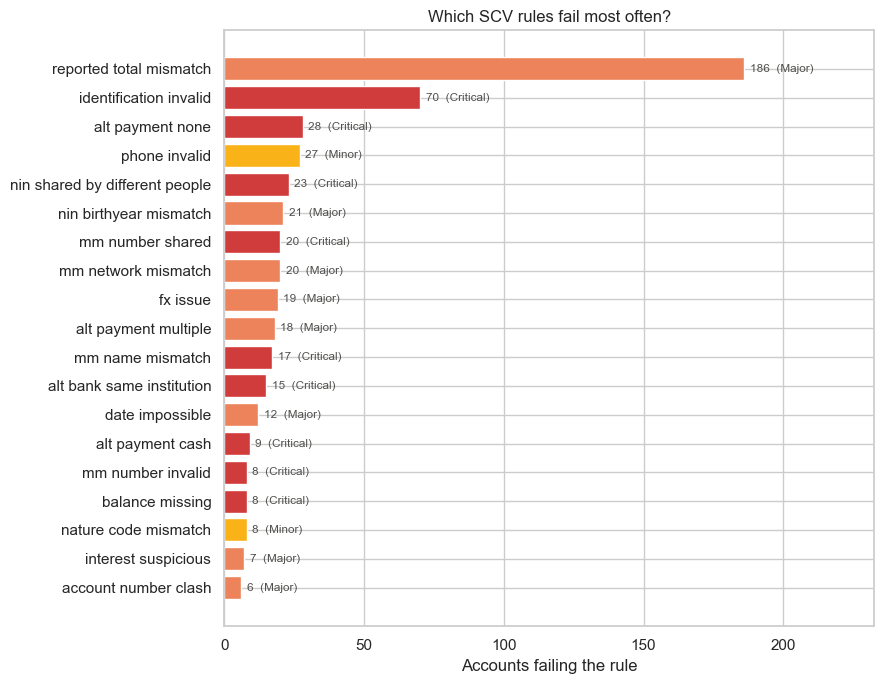

In [192]:
SEVERITY_COLOURS = {"Critical": COLOURS["critical"], "Major": COLOURS["serious"], "Minor": COLOURS["warning"]}

counts = rule_catalogue.assign(failing=[int(acct[r].sum()) for r in RULE_COLUMNS])
counts = counts[counts["failing"] > 0].sort_values("failing")
labels = counts["Rule"].str[4:].str.replace("_", " ")

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(labels, counts["failing"], color=counts["Severity"].map(SEVERITY_COLOURS))
for y, (value, sev) in enumerate(zip(counts["failing"], counts["Severity"])):
    ax.text(value + 2, y, f"{value}  ({sev})", va="center", fontsize=8.5, color="#52514e")
ax.set_xlabel("Accounts failing the rule")
ax.set_title("Which SCV rules fail most often?")
ax.set_xlim(0, counts["failing"].max() * 1.25)
plt.tight_layout()
plt.show()

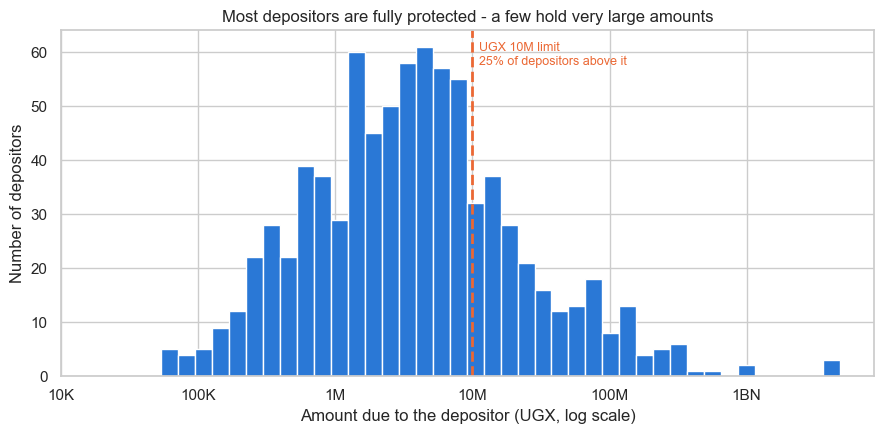

Why a log scale? Money is very skewed: on a normal scale almost all depositors squash into the first bar.


In [193]:
positive = dep.loc[dep["amount_due"] > 0, "amount_due"]
share_above = (positive > PROTECTION_LIMIT).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(np.log10(positive), bins=40, color=COLOURS["protected"], edgecolor="white")
ax.axvline(np.log10(PROTECTION_LIMIT), color=COLOURS["outstanding"], linestyle="--", linewidth=2)
ax.text(np.log10(PROTECTION_LIMIT) + 0.05, ax.get_ylim()[1] * 0.9,
        f"UGX 10M limit\n{share_above:.0%} of depositors above it", color=COLOURS["outstanding"], fontsize=9)
ticks = [4, 5, 6, 7, 8, 9]
ax.set_xticks(ticks, ["10K", "100K", "1M", "10M", "100M", "1BN"])
ax.set_xlabel("Amount due to the depositor (UGX, log scale)")
ax.set_ylabel("Number of depositors")
ax.set_title("Most depositors are fully protected - a few hold very large amounts")
plt.tight_layout()
plt.show()
print("Why a log scale? Money is very skewed: on a normal scale almost all depositors squash into the first bar.")

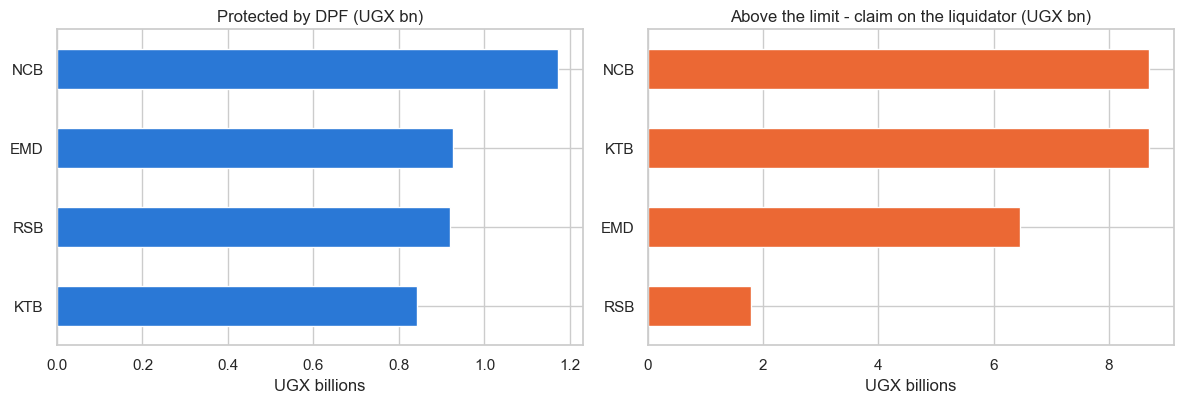

Two charts, not one dual-axis chart: the two amounts answer different questions.
⚠️ Look at the right-hand chart: a handful of extreme balances drive it. Day 5's anomaly detection finds them.


In [194]:
inst_totals = dep.groupby("institution_code")[["protected", "above_limit_claim"]].sum().div(1e9)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
inst_totals["protected"].sort_values().plot.barh(ax=axes[0], color=COLOURS["protected"])
axes[0].set_title("Protected by DPF (UGX bn)")
axes[0].set_xlabel("UGX billions")
inst_totals["above_limit_claim"].sort_values().plot.barh(ax=axes[1], color=COLOURS["outstanding"])
axes[1].set_title("Above the limit - claim on the liquidator (UGX bn)")
axes[1].set_xlabel("UGX billions")
for a in axes:
    a.set_ylabel("")
plt.tight_layout()
plt.show()
print("Two charts, not one dual-axis chart: the two amounts answer different questions.")
print("⚠️ Look at the right-hand chart: a handful of extreme balances drive it. Day 5's anomaly detection finds them.")

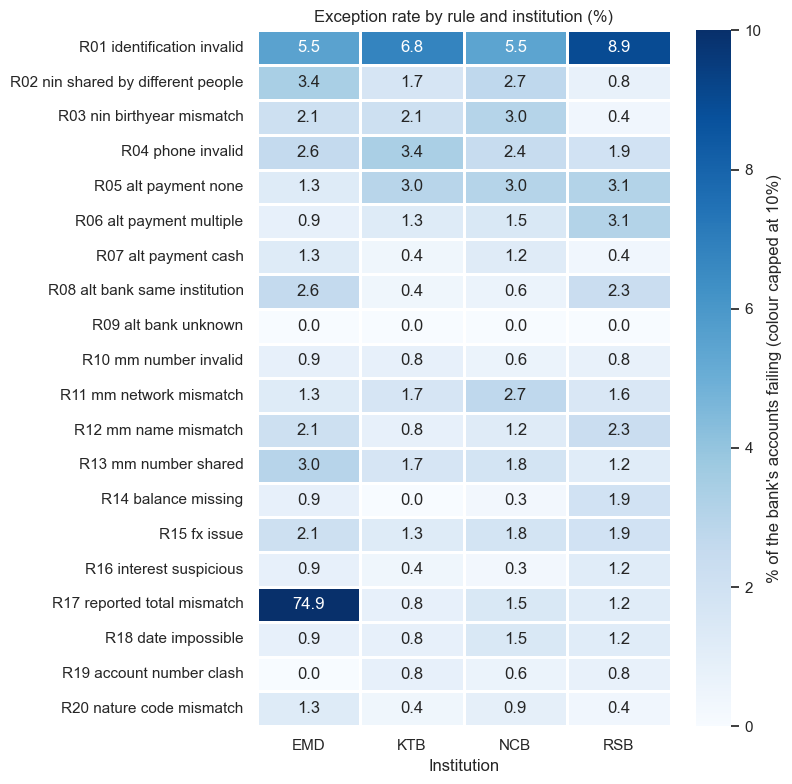

Read across a row to compare banks on one rule; down a column to see one bank's profile.
The colour scale stops at 10% so one extreme cell (EMD, R17 = 75%) does not wash out all the others.


In [195]:
category_of = dict(zip(rule_catalogue["Rule"], rule_catalogue["Category"]))
rate = (acct.groupby("institution_code")[RULE_COLUMNS].mean() * 100).T
rate.index = [r[:3] + " " + r[4:].replace("_", " ") for r in rate.index]

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(rate, annot=True, fmt=".1f", cmap="Blues", vmax=10, linewidths=1, linecolor="white",
            cbar_kws={"label": "% of the bank's accounts failing (colour capped at 10%)"}, ax=ax)
ax.set_title("Exception rate by rule and institution (%)")
ax.set_xlabel("Institution")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
print("Read across a row to compare banks on one rule; down a column to see one bank's profile.")
print("The colour scale stops at 10% so one extreme cell (EMD, R17 = 75%) does not wash out all the others.")

## 4.3 Beyond the bar chart

### UpSet plot — which problems occur *together*?
A Venn diagram becomes unreadable beyond 3 sets. An **UpSet** plot shows each *combination* as a bar, with
dots underneath saying which sets are in it. Here: the categories of exception each account has.

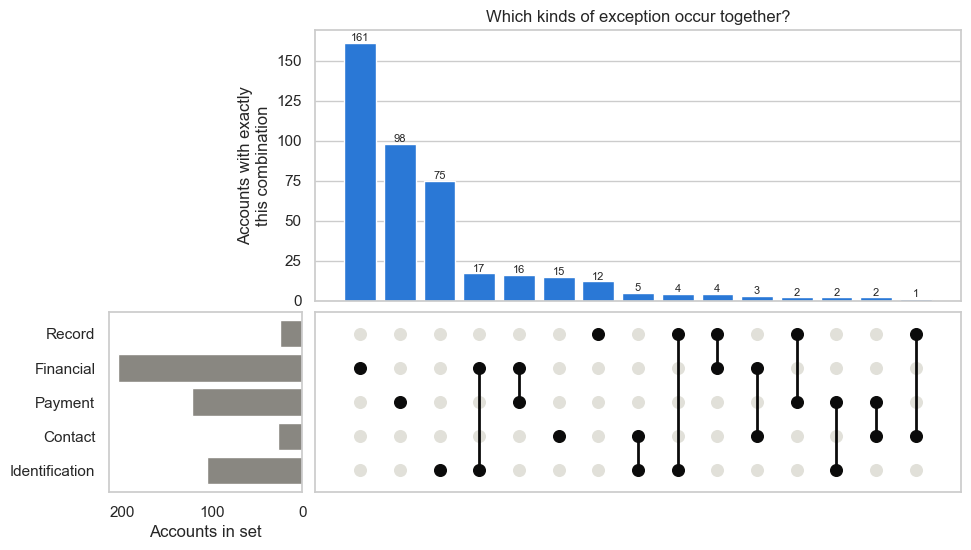

In [238]:
def upset_plot(flags, title, max_combinations=15, colour=COLOURS["protected"]):
    """flags: a table of True/False columns (one per set). Draws a simple UpSet plot."""
    sets = list(flags.columns)
    combos = flags.value_counts()                              # each row pattern and how often it occurs
    combos = combos[[any(pattern) for pattern in combos.index]].head(max_combinations)
    set_sizes = flags.sum()

    fig = plt.figure(figsize=(11, 6))
    grid = fig.add_gridspec(2, 2, height_ratios=[3, 2], width_ratios=[1.2, 4], hspace=0.05, wspace=0.03)
    ax_bars = fig.add_subplot(grid[0, 1])
    ax_dots = fig.add_subplot(grid[1, 1], sharex=ax_bars)
    ax_sets = fig.add_subplot(grid[1, 0], sharey=ax_dots)

    x = np.arange(len(combos))
    ax_bars.bar(x, combos.values, color=colour)
    for xi, v in zip(x, combos.values):
        ax_bars.text(xi, v, str(v), ha="center", va="bottom", fontsize=8)
    ax_bars.set_ylabel("Accounts with exactly\nthis combination")
    ax_bars.set_title(title)
    ax_bars.tick_params(labelbottom=False)

    for xi, pattern in zip(x, combos.index):
        active = [j for j, on in enumerate(pattern) if on]
        ax_dots.scatter([xi] * len(sets), range(len(sets)), s=70, color="#e1e0d9", zorder=1)
        ax_dots.scatter([xi] * len(active), active, s=70, color="#0b0b0b", zorder=2)
        if len(active) > 1:
            ax_dots.plot([xi, xi], [min(active), max(active)], color="#0b0b0b", linewidth=2, zorder=2)
    ax_dots.set_xticks([])
    ax_dots.grid(False)
    ax_dots.tick_params(labelleft=False)

    ax_sets.barh(range(len(sets)), set_sizes.values, color="#898781")
    ax_sets.set_yticks(range(len(sets)), sets)
    ax_sets.invert_xaxis()
    ax_sets.set_xlabel("Accounts in set")
    ax_sets.grid(False)
    plt.show()


categories = rule_catalogue["Category"].unique()
category_flags = pd.DataFrame({cat: acct[rule_catalogue.loc[rule_catalogue["Category"] == cat, "Rule"]].any(axis=1)
                               for cat in categories})
upset_plot(category_flags, "Which kinds of exception occur together?")

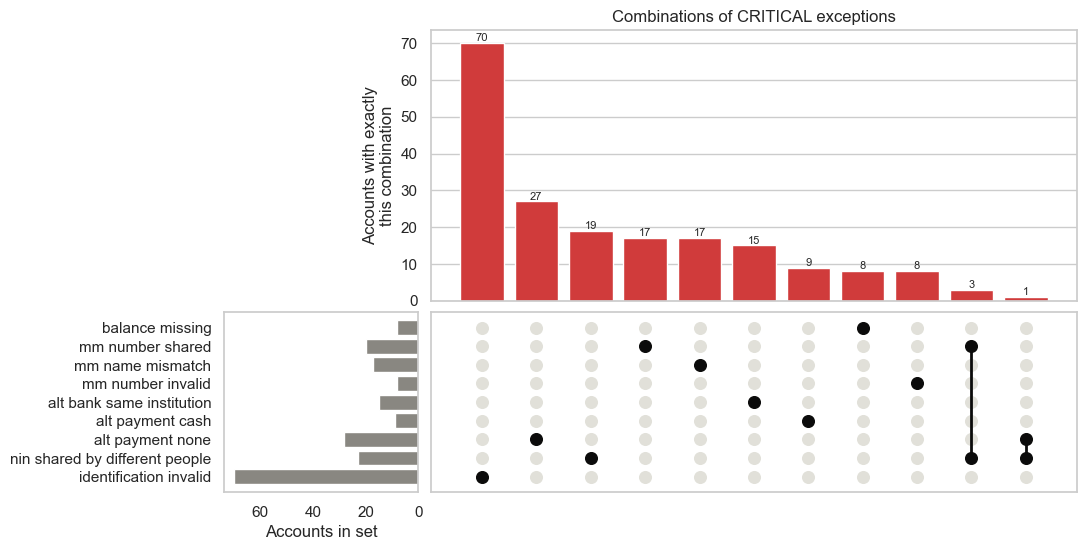

In [197]:
# The same idea for the CRITICAL rules only - what exactly blocks payouts?
critical_rules = rule_catalogue.loc[rule_catalogue["Severity"] == "Critical", "Rule"]
critical_flags = acct[critical_rules].rename(columns=lambda r: r[4:].replace("_", " "))
critical_flags = critical_flags.loc[:, critical_flags.sum() > 0]
upset_plot(critical_flags, "Combinations of CRITICAL exceptions", colour=COLOURS["critical"])

### Sankey diagram — following records through a process
The width of each band is the number of accounts. Read it left to right: **institution → alternative payment
channel → is the channel usable?** (Interactive: hover over the bands.)

In [239]:
def channel_type(row):
    if row["alt_channels"] == 0:
        return "None given"
    if row["alt_channels"] > 1:
        return "Several channels"
    if row["alt_is_cash"]:
        return "Cash (not allowed)"
    if row["alt_bank_given"]:
        return "Same bank (invalid)" if row["alt_bank_code"] == row["institution_code"] else "Other bank"
    if row["alt_mm_given"]:
        return "Mobile money"
    return "Other e-payment"


def sankey_from_columns(df, columns, title, colour_map=None):
    """Build a Sankey from 2+ categorical columns: each pair of neighbouring columns makes one set of links."""
    labels, index = [], {}
    for col in columns:
        for value in df[col].dropna().unique():
            key = (col, value)
            index[key] = len(labels)
            labels.append(str(value))
    sources, targets, values = [], [], []
    for left, right in zip(columns[:-1], columns[1:]):
        flows = df.groupby([left, right]).size().reset_index(name="n")
        for _, f in flows.iterrows():
            sources.append(index[(left, f[left])])
            targets.append(index[(right, f[right])])
            values.append(int(f["n"]))
    node_colours = [(colour_map or {}).get(lbl, "#9ec5f4") for lbl in labels]
    fig = go.Figure(go.Sankey(node=dict(label=labels, pad=18, thickness=16, color=node_colours),
                              link=dict(source=sources, target=targets, value=values, color="rgba(137,135,129,0.25)")))
    fig.update_layout(title=title, height=520, font_size=12)
    return fig


acct["Alternative channel"] = acct.apply(channel_type, axis=1)
acct["Channel status"] = np.where(acct["payment_ok"], "Usable channel", "Payment problem")
fig = sankey_from_columns(acct, ["institution_code", "Alternative channel", "Channel status"],
                          "From institution to alternative payment channel to usability (accounts)",
                          colour_map={"Usable channel": COLOURS["good"], "Payment problem": COLOURS["critical"]})
fig.show()

In [199]:
# A second Sankey at DEPOSITOR level: client type -> payout status
status_colours = {"Ready to pay": COLOURS["good"], "Ready with review": COLOURS["warning"],
                  "Needs payment details": COLOURS["serious"], "Blocked - identity": COLOURS["critical"],
                  "Blocked - amount unknown": COLOURS["critical"]}
fig = sankey_from_columns(dep, ["institution_code", "client_type", "payout_status"],
                          "Depositors: institution -> client type -> payout status", colour_map=status_colours)
fig.show()

### Waterfall — how "amount due" becomes "payable now"

In [200]:
positive_dep = dep[dep["amount_due"] > 0]
total_due = positive_dep["amount_due"].sum() / 1e9
above = positive_dep["above_limit_claim"].sum() / 1e9
protected_total = positive_dep["protected"].sum() / 1e9
held = positive_dep["held_back"].sum() / 1e9

fig = go.Figure(go.Waterfall(
    measure=["absolute", "relative", "total", "relative", "total"],
    x=["Amount due to depositors", "Above the 10M limit", "Protected by DPF", "Held back (liens, orders)", "Payable now"],
    y=[total_due, -above, 0, -held, 0],
    text=[f"{v:,.2f}" for v in [total_due, -above, protected_total, -held, protected_total - held]],
    textposition="outside",
    decreasing=dict(marker=dict(color=COLOURS["outstanding"])),
    increasing=dict(marker=dict(color=COLOURS["protected"])),
    totals=dict(marker=dict(color=COLOURS["protected"])),
))
fig.update_layout(title="From amount due to payable now (UGX bn, all four institutions)", yaxis_title="UGX billions",
                  height=450, showlegend=False)
fig.show()

### Treemap — where is the protected money? (click a box to zoom in)

In [201]:
fig = px.treemap(dep[dep["protected"] > 0], path=["institution_code", "client_type", "region"], values="protected",
                 color="institution_code", color_discrete_sequence=CATEGORY_ORDER_COLOURS,
                 title="Protected amount by institution, client type and region")
fig.update_traces(hovertemplate="%{label}<br>UGX %{value:,.0f}<extra></extra>")
fig.update_layout(height=520)
fig.show()

### What-if curve — what would a different limit cost, and whom would it cover?
A supervisory question answered with one loop. Two separate charts (different units), sharing the x-axis.

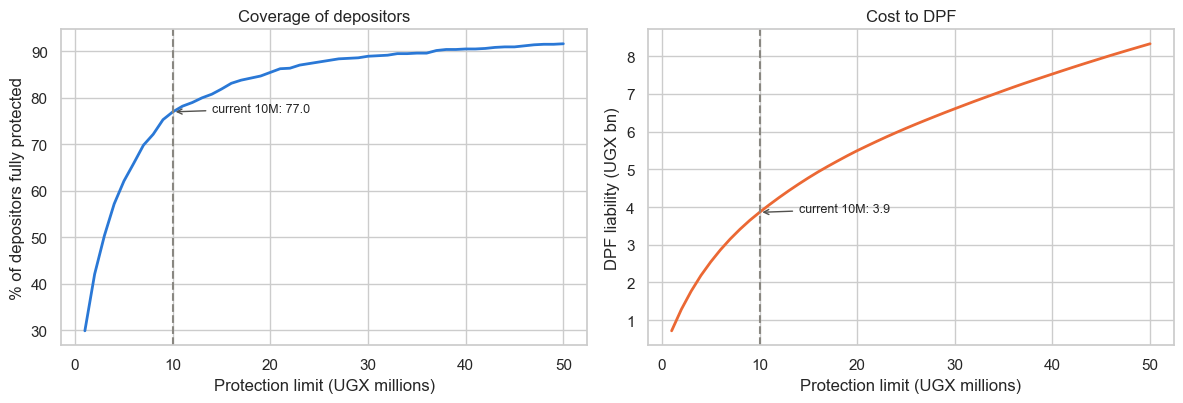

In [240]:
limits = np.arange(1_000_000, 50_000_001, 1_000_000)
due = dep["amount_due"].clip(lower=0)
pct_covered = [(dep["amount_due"] <= L).mean() * 100 for L in limits]
liability = [due.clip(upper=L).sum() / 1e9 for L in limits]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
axes[0].plot(limits / 1e6, pct_covered, color=COLOURS["protected"], linewidth=2)
axes[0].set_ylabel("% of depositors fully protected")
axes[0].set_title("Coverage of depositors")
axes[1].plot(limits / 1e6, liability, color=COLOURS["outstanding"], linewidth=2)
axes[1].set_ylabel("DPF liability (UGX bn)")
axes[1].set_title("Cost to DPF")
for a, values in zip(axes, [pct_covered, liability]):
    a.axvline(10, color="#898781", linestyle="--")
    a.annotate(f"current 10M: {values[9]:,.1f}", xy=(10, values[9]), xytext=(14, values[9]),
               arrowprops=dict(arrowstyle="->", color="#52514e"), fontsize=9)
    a.set_xlabel("Protection limit (UGX millions)")
plt.tight_layout()
plt.show()

### Map — exceptions by branch
(Uses each branch's coordinates from `Lookup_Branches`. The background map needs an internet connection.)

In [203]:
by_branch = acct.groupby(["Domicile Branch Name", "Latitude", "Longitude"]).agg(
    accounts=("Record ID", "count"), exception_rate=("has_exception", "mean")).reset_index()
by_branch["exception_rate"] = (by_branch["exception_rate"] * 100).round(1)

fig = px.scatter_geo(by_branch, lat="Latitude", lon="Longitude", size="accounts", color="exception_rate",
                     hover_name="Domicile Branch Name", color_continuous_scale="Blues", size_max=40,
                     title="Accounts and exception rate (%) by branch")
fig.update_geos(fitbounds="locations", showcountries=True, countrycolor="#c3c2b7", showland=True, landcolor="#f9f9f7")
fig.update_layout(height=520)
fig.show()

## 4.4 Visualising awareness & customer-satisfaction survey data

**Does survey data fit an SCV training?** Yes — DPF listed *awareness and customer satisfaction surveys* among
its visualisation challenges, and the techniques (categorical and Likert data, comparing waves and segments) are
different from transaction data. We keep it to one focused session.

The sheet `Survey_Awareness` holds a fictional two-wave survey (2025 and 2026) of the public.

### 🗣️ Case Study 4A — survey results need context
Before any chart, ask: who was sampled (and who was not)? How many answered each question? Are the two waves
comparable? Is a 3-point difference meaningful with this sample size?

In [241]:
survey = pd.read_excel(DATA_FILE, sheet_name="Survey_Awareness")
look(survey, n=3, title="Survey")
print(survey.groupby("Survey Wave").size().rename("respondents"))

--- Survey ---
900 rows x 18 columns


,Respondent ID,Survey Wave,Interview Date,Region,District,Area,Gender,Age Group,Education,Has Account at Financial Institution,Heard of DPF,Main Source of Information,Knows Coverage Limit,Q1 I trust banks to keep my money safe,Q2 I am confident my deposits are protected,Q3 DPF information is easy to understand,Q4 Satisfied with DPF services/communication,Q5 Likelihood to recommend saving in a bank (0-10)
0,R2025-0001,2025,2025-05-19,Central,Wakiso,Rural,Male,18-24,Secondary,No,No,Not aware,Don't know,Neutral,Neutral,NaN,NaN,10
1,R2025-0002,2025,2025-05-11,Eastern,Jinja,Rural,Female,50+,Primary,No,Yes,Social media,Correct (UGX 10M),Agree,Neutral,Disagree,Neutral,6
2,R2025-0003,2025,2025-05-17,Eastern,Jinja,Rural,Male,50+,Tertiary,Yes,No,Not aware,Don't know,Agree,Agree,NaN,NaN,6


Survey Wave
2025    459
2026    441
Name: respondents, dtype: int64


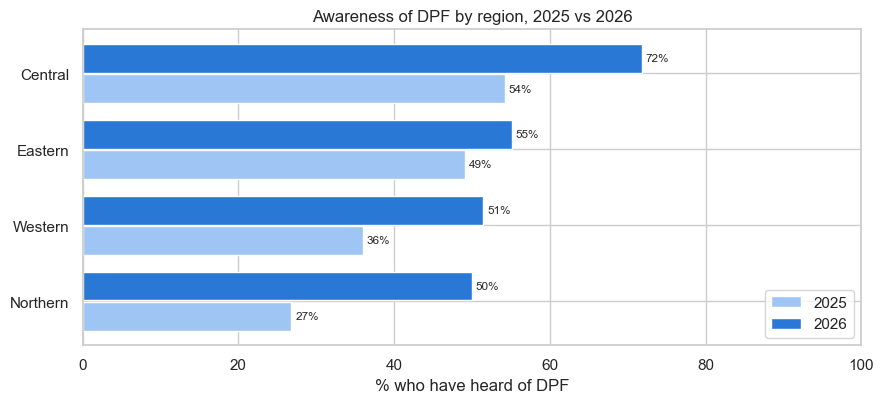

In [244]:
aware = (survey.assign(aware=survey["Heard of DPF"].eq("Yes"))
               .groupby(["Region", "Survey Wave"])["aware"].mean().mul(100).unstack())
aware = aware.sort_values(2026)

fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(aware))
ax.barh(y - 0.2, aware[2025], height=0.38, color="#9ec5f4", label="2025")
ax.barh(y + 0.2, aware[2026], height=0.38, color=COLOURS["protected"], label="2026")
for yi, (a, b) in enumerate(zip(aware[2025], aware[2026])):
    ax.text(a + 0.5, yi - 0.2, f"{a:.0f}%", va="center", fontsize=8.5)
    ax.text(b + 0.5, yi + 0.2, f"{b:.0f}%", va="center", fontsize=8.5)
ax.set_yticks(y, aware.index)
ax.set_xlabel("% who have heard of DPF")
ax.set_title("Awareness of DPF by region, 2025 vs 2026")
ax.legend(loc="lower right")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

### Likert items — use a **diverging** stacked bar
Disagree goes left of zero, agree to the right, neutral sits in the middle. The eye compares the
balance of opinion instantly — something a pie or a plain stacked bar cannot do.

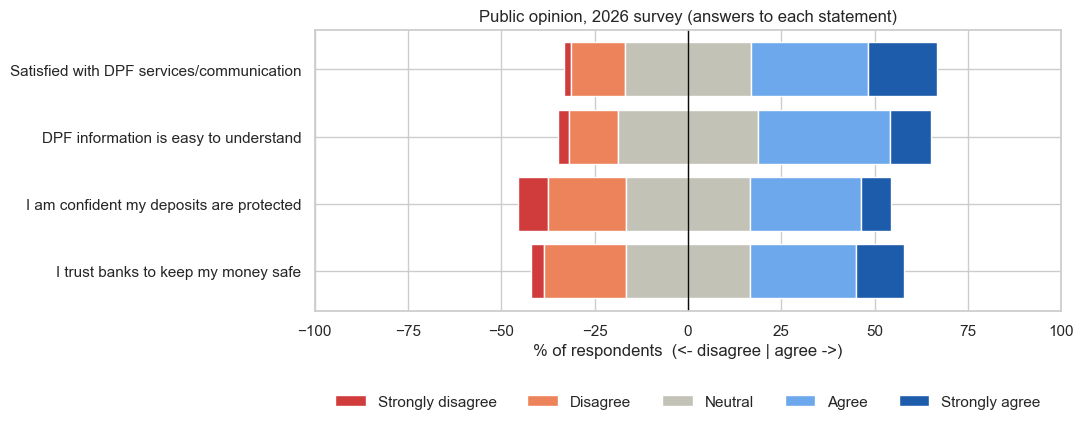

,Strongly disagree,Disagree,Neutral,Agree,Strongly agree
Q1 I trust banks to keep my money safe,3.60,22.00,33.10,28.60,12.70
Q2 I am confident my deposits are protected,8.20,20.90,33.10,29.70,8.20
Q3 DPF information is easy to understand,3.10,13.00,37.50,35.20,11.10
Q4 Satisfied with DPF services/communication,1.90,14.60,33.70,31.40,18.40


In [243]:
LIKERT = ["Strongly disagree", "Disagree", "Neutral", "Agree", "Strongly agree"]
LIKERT_COLOURS = ["#d03b3b", "#ec835a", "#c3c2b7", "#6da7ec", "#1c5cab"]   # red <-> grey <-> blue
questions = [c for c in survey.columns if c.startswith("Q") and "(0-10)" not in c]


def diverging_likert(data, items, title):
    pct = pd.DataFrame({q: data[q].value_counts(normalize=True).reindex(LIKERT, fill_value=0) * 100 for q in items}).T
    left_start = -(pct["Strongly disagree"] + pct["Disagree"] + pct["Neutral"] / 2)
    fig, ax = plt.subplots(figsize=(11, 0.75 * len(items) + 1.6))
    start = left_start.copy()
    for level, colour in zip(LIKERT, LIKERT_COLOURS):
        ax.barh(range(len(items)), pct[level], left=start, color=colour, edgecolor="white", label=level)
        start = start + pct[level]
    ax.axvline(0, color="#0b0b0b", linewidth=1)
    ax.set_yticks(range(len(items)), [i.split(" ", 1)[1] for i in items])
    ax.set_xlabel("% of respondents  (<- disagree | agree ->)")
    ax.set_title(title)
    ax.legend(ncol=5, bbox_to_anchor=(0.5, -0.25), loc="upper center", frameon=False)
    ax.set_xlim(-100, 100)
    plt.tight_layout()
    plt.show()
    return pct.round(1)


diverging_likert(survey[survey["Survey Wave"] == 2026], questions, "Public opinion, 2026 survey (answers to each statement)")

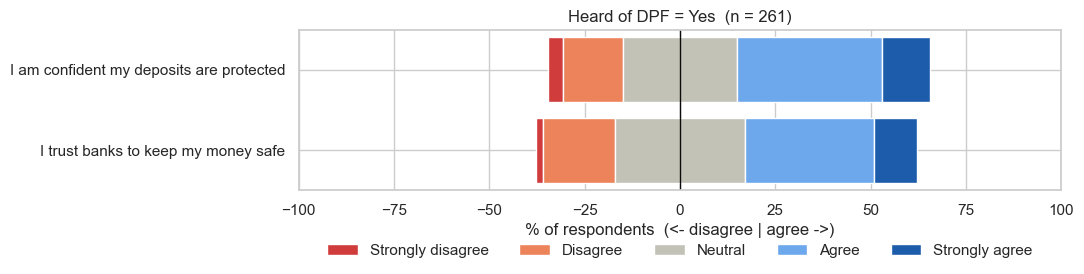

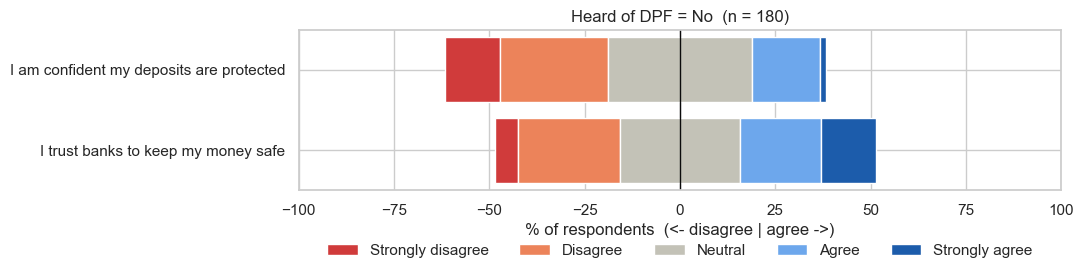

In [207]:
# Does knowing about DPF change confidence? Same chart, split by awareness
for status in ["Yes", "No"]:
    subset = survey[(survey["Survey Wave"] == 2026) & (survey["Heard of DPF"] == status)]
    diverging_likert(subset, ["Q1 I trust banks to keep my money safe", "Q2 I am confident my deposits are protected"],
                     f"Heard of DPF = {status}  (n = {len(subset)})")

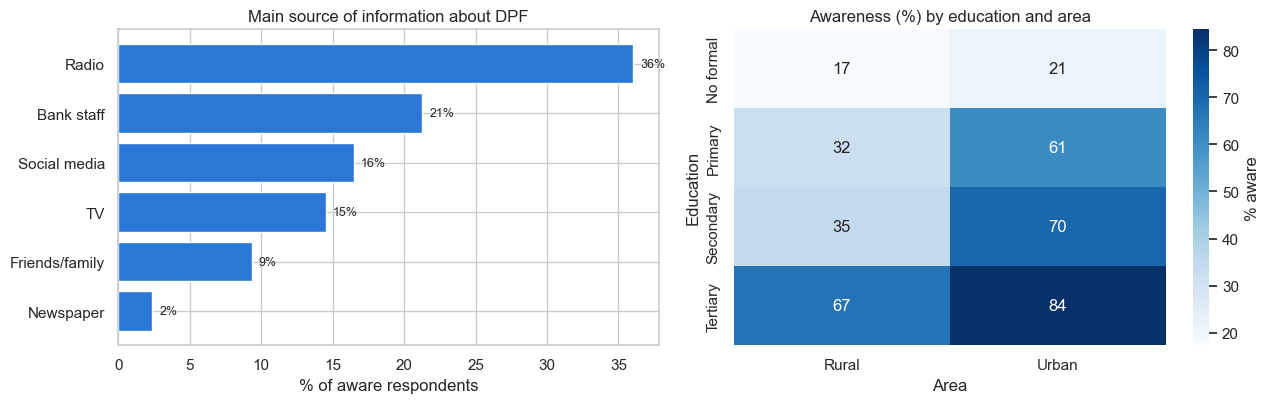

In [208]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Where did aware respondents hear about DPF?
sources = survey.loc[survey["Heard of DPF"] == "Yes", "Main Source of Information"].value_counts(normalize=True).mul(100).sort_values()
axes[0].barh(sources.index, sources.values, color=COLOURS["protected"])
for yi, v in enumerate(sources.values):
    axes[0].text(v + 0.5, yi, f"{v:.0f}%", va="center", fontsize=9)
axes[0].set_xlabel("% of aware respondents")
axes[0].set_title("Main source of information about DPF")

# Awareness by education and area (a heatmap of %)
heat = survey.assign(aware=survey["Heard of DPF"].eq("Yes")).pivot_table(
    index="Education", columns="Area", values="aware", aggfunc="mean").reindex(["No formal", "Primary", "Secondary", "Tertiary"]) * 100
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% aware"}, ax=axes[1])
axes[1].set_title("Awareness (%) by education and area")
plt.tight_layout()
plt.show()

Recommend group,Detractor (0-6),Passive (7-8),Promoter (9-10),Net score
Survey Wave,,,,
2025,45.80,32.50,21.80,-24.00
2026,45.10,32.70,22.20,-22.90


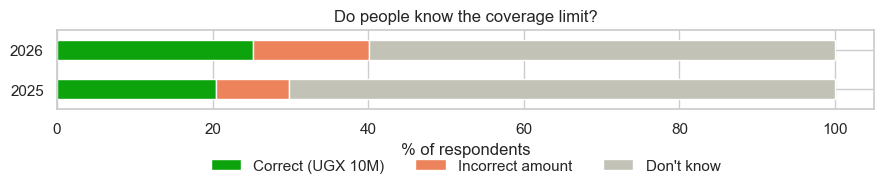

In [209]:
# Net Promoter-style score from the 0-10 question: % promoters (9-10) minus % detractors (0-6)
score = survey["Q5 Likelihood to recommend saving in a bank (0-10)"]
survey["Recommend group"] = pd.cut(score, bins=[-1, 6, 8, 10], labels=["Detractor (0-6)", "Passive (7-8)", "Promoter (9-10)"])
nps = survey.groupby("Survey Wave")["Recommend group"].value_counts(normalize=True).unstack() * 100
nps["Net score"] = nps["Promoter (9-10)"] - nps["Detractor (0-6)"]
display(nps.round(1))

knows = pd.crosstab(survey["Survey Wave"], survey["Knows Coverage Limit"], normalize="index") * 100
knows = knows[["Correct (UGX 10M)", "Incorrect amount", "Don't know"]]
ax = knows.plot.barh(stacked=True, figsize=(9, 2.6), color=[COLOURS["good"], COLOURS["serious"], "#c3c2b7"], edgecolor="white")
ax.set_xlabel("% of respondents")
ax.set_ylabel("")
ax.set_title("Do people know the coverage limit?")
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.45), loc="upper center", frameon=False)
plt.tight_layout()
plt.show()

> **Interpretation cautions for survey charts:** report the sample size (n) on every chart; avoid comparing
> small sub-groups (n < 30); say whether results are weighted; compare waves only if the questions and
> sampling were the same.

## 4.5 Dashboard design

### 🖥️ Case Study 4B — a supervisor has 90 seconds
The first screen should answer: *How many depositors? How much does DPF protect? What share of records have
problems, and where? How many depositors could we pay today? Is public awareness improving?*

| Principle | In practice |
|---|---|
| Audience first | **operational** (daily data quality per bank) vs **supervisory** (monthly exposure and readiness) |
| Headline numbers on top | 4–5 KPI tiles, each with a clear label and unit |
| One screen | if it scrolls, it is a report, not a dashboard |
| Consistent colour | same meaning in every panel; status colours only for status |
| Filters in one place | bank / client type / region (Tableau and Streamlit do this best) |

We build an **interactive Plotly dashboard** and save it as a single HTML file anyone can open in a browser.

In [210]:
kpi = {
    "Depositors": len(dep),
    "Protected (UGX bn)": dep["protected"].sum() / 1e9,
    "Accounts with exception (%)": acct["has_exception"].mean() * 100,
    "Depositors ready to pay (%)": (dep["payout_status"] == "Ready to pay").mean() * 100,
    "Aware of DPF, 2026 (%)": survey.loc[survey["Survey Wave"] == 2026, "Heard of DPF"].eq("Yes").mean() * 100,
}

fig = make_subplots(
    rows=3, cols=5,
    specs=[[{"type": "indicator"}] * 5,
           [{"type": "bar", "colspan": 3}, None, None, {"type": "bar", "colspan": 2}, None],
           [{"type": "bar", "colspan": 3}, None, None, {"type": "bar", "colspan": 2}, None]],
    row_heights=[0.16, 0.42, 0.42], vertical_spacing=0.09, horizontal_spacing=0.08,
    subplot_titles=["", "", "", "", "",
                    "Payout status of depositors by institution", "Protected vs above-limit (UGX bn)",
                    "Accounts failing each exception category, by institution", "Awareness of DPF by region (%)"],
)

for i, (label, value) in enumerate(kpi.items(), start=1):
    fmt = ",.0f" if label == "Depositors" else ",.1f"
    fig.add_trace(go.Indicator(mode="number", value=value, number={"valueformat": fmt, "font": {"size": 34}},
                               title={"text": label, "font": {"size": 13}}), row=1, col=i)

status_counts = pd.crosstab(dep["institution_code"], dep["payout_status"])
for status in ["Ready to pay", "Ready with review", "Needs payment details", "Blocked - amount unknown", "Blocked - identity"]:
    if status in status_counts:
        fig.add_trace(go.Bar(x=status_counts.index, y=status_counts[status], name=status,
                             marker_color=status_colours[status], legendgroup="status"), row=2, col=1)

fig.add_trace(go.Bar(x=inst_totals.index, y=inst_totals["protected"], name="Protected (UGX bn)",
                     marker_color=COLOURS["protected"], legendgroup="money"), row=2, col=4)
fig.add_trace(go.Bar(x=inst_totals.index, y=inst_totals["above_limit_claim"], name="Above limit (UGX bn)",
                     marker_color=COLOURS["outstanding"], legendgroup="money"), row=2, col=4)

cat_by_inst = category_flags.groupby(acct["institution_code"]).sum()
for colour, category in zip(CATEGORY_ORDER_COLOURS[2:], cat_by_inst.columns):   # skip blue/orange (they mean money)
    fig.add_trace(go.Bar(x=cat_by_inst.index, y=cat_by_inst[category], name=category, marker_color=colour,
                         legendgroup="category"), row=3, col=1)

fig.add_trace(go.Bar(x=aware.index, y=aware[2025], name="Survey 2025", marker_color="#9ec5f4", legendgroup="survey"), row=3, col=4)
fig.add_trace(go.Bar(x=aware.index, y=aware[2026], name="Survey 2026", marker_color="#184f95", legendgroup="survey"), row=3, col=4)

fig.update_layout(title="DPF Single Customer View - compliance & payout readiness dashboard (reporting date 30-09-2026)",
                  barmode="group", height=900, legend=dict(orientation="v", x=1.02, y=0.6), template="plotly_white")
fig.update_xaxes(type="category")
fig.update_yaxes(title_text="Depositors", row=2, col=1)
fig.update_yaxes(title_text="Accounts", row=3, col=1)
fig.update_yaxes(title_text="UGX bn", row=2, col=4)
fig.update_yaxes(title_text="% aware", row=3, col=4)
fig.show()

dashboard_file = OUTPUT_DIR / "DPF_SCV_Dashboard.html"
fig.write_html(dashboard_file, include_plotlyjs="cdn")
print("Saved - open this file in any browser or email it:", dashboard_file)

Saved - open this file in any browser or email it: DPF_outputs/DPF_SCV_Dashboard.html


### Optional: the same dashboard as a small web app with filters (Streamlit)
Streamlit turns a Python script into an interactive web page with dropdown filters. The cell below **writes**
the app file for you. To run it: open *Anaconda Prompt*, go to this folder, then
`pip install streamlit` (once) and `streamlit run dpf_dashboard_app.py`. A browser tab opens.

In [211]:
APP_CODE = r"""
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="DPF SCV dashboard", layout="wide")
dep = pd.read_pickle("DPF_outputs/dep.pkl")
acct = pd.read_pickle("DPF_outputs/acct.pkl")

st.title("DPF Single Customer View - dashboard")
banks = st.sidebar.multiselect("Institution", sorted(dep["institution_code"].unique()), default=sorted(dep["institution_code"].unique()))
types = st.sidebar.multiselect("Client type", sorted(dep["client_type"].unique()), default=sorted(dep["client_type"].unique()))
d = dep[dep["institution_code"].isin(banks) & dep["client_type"].isin(types)]
a = acct[acct["institution_code"].isin(banks) & acct["Client Type"].isin(types)]

c1, c2, c3, c4 = st.columns(4)
c1.metric("Depositors", f"{len(d):,}")
c2.metric("Protected (UGX bn)", f"{d['protected'].sum() / 1e9:,.2f}")
c3.metric("Accounts with exception", f"{a['has_exception'].mean():.1%}")
c4.metric("Ready to pay", f"{(d['payout_status'] == 'Ready to pay').mean():.1%}")

left, right = st.columns(2)
left.plotly_chart(px.histogram(d, x="institution_code", color="payout_status", title="Payout status"), use_container_width=True)
rules = a.filter(regex=r"^R\d\d_").sum().sort_values().tail(10)
right.plotly_chart(px.bar(rules, orientation="h", title="Top 10 failing rules"), use_container_width=True)
st.dataframe(d.sort_values("protected", ascending=False).head(50))
"""
Path("dpf_dashboard_app.py").write_text(APP_CODE)
print("Wrote dpf_dashboard_app.py  ->  run with:  streamlit run dpf_dashboard_app.py")

Wrote dpf_dashboard_app.py  ->  run with:  streamlit run dpf_dashboard_app.py


---
## 🧪 DAY 4 LAB TASKS — visualise the payout programme

Use `payout_clean` and your Day 3 `check_payout()` results.

| # | Task | Chart |
|---|---|---|
| 1 | How has money gone out over time? Plot the **cumulative amount paid** by payment date. Mark the closure date. | line chart |
| 2 | Compare payment status (Paid / Pending / Failed / Returned) across regions as **% of claims**. | 100% stacked bar |
| 3 | Show the flow **Region → Payment channel → Payment status** | Sankey (`sankey_from_columns`) |
| 4 | Which payout risks occur together? Use your P1–P7 columns. | UpSet (`upset_plot`) |
| 5 | Build a 4-panel Plotly dashboard (2 KPI tiles + 2 charts) and save it as `DPF_outputs/payout_dashboard.html` | make_subplots |
| ⭐ | Write one sentence under each chart: *what should a manager do because of this chart?* | — |

In [212]:
# Task 1

In [213]:
# Task 2

In [214]:
# Task 3

In [215]:
# Task 4

In [216]:
# Task 5

## ✅ Day 4 exit ticket
For one chart you made today write: **Audience** (who looks at it?) · **Question** (what does it answer?) ·
**Evidence** (which data?) · **Action** (what would the viewer do next?). A chart without a question is decoration.

---
---
# DAY 5 — Predictive Analytics, Machine Learning, Tableau & Capstone

**Objective:** use machine learning where it genuinely helps DPF — finding unusual records rules miss, and
predicting who is unaware of DPF so campaigns can be targeted — then build an interactive Tableau dashboard
and present a capstone.

## 🗓️ Day 5 — schedule

| Time | Session |
|---|---|
| 9:00 – 9:30 | Intro to predictive & advanced analytics — what ML can and cannot do for DPF |
| 9:30 – 10:30 | ML part 1 (unsupervised): anomaly detection with engineered features, explained flags, evaluation |
| 10:30 – 10:45 | Break |
| 10:45 – 11:30 | ML part 2 (supervised): predicting awareness of DPF — train/test, metrics, interpretation |
| 11:30 – 1:00 | Tableau: connect to the Python outputs, build views, LOD & what-if parameter, dashboard, publish safely |
| 1:00 – 1:30 | Capstone preparation in groups |
| 1:30 – 2:15 | Lunch |
| 2:15 – 3:30 | Capstone presentations (Python pipeline + Tableau dashboard + findings) |
| 3:30 – 4:00 | Wrap-up, resource pack handover, sustainability plan |

In [217]:
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, precision_score, recall_score)

acct = pd.read_pickle(OUTPUT_DIR / "acct.pkl")       # start from the saved Day 3 results
dep = pd.read_pickle(OUTPUT_DIR / "dep.pkl")
acct["Alternative channel"] = acct.apply(channel_type, axis=1)     # (added on Day 4)
print("scikit-learn ready; accounts:", len(acct))

scikit-learn ready; accounts: 1058


## 5.1 What machine learning can — and cannot — do here

| | **Rules** (Days 1–3) | **Unsupervised ML** (anomaly detection) | **Supervised ML** (prediction) |
|---|---|---|---|
| Question | Does the record meet a known requirement? | Does it look unusual compared with the rest? | Given what we know, what is likely? |
| Needs | the rule, written down | numbers describing each record | past examples **with the answer** (labels) |
| Output | pass / fail + reason | an "unusualness" score | a probability |
| DPF example | NIN missing | balance 300× bigger than similar depositors | which groups are unlikely to know about DPF |

**ML never replaces rules or people.** It *prioritises* where humans look. A flagged record is a question, not a verdict.

### 🤖 Case Study 5 — rule failure vs unusual behaviour
Record A has an invalid NIN but ordinary amounts — rules catch it, a model would not. Record B has a valid NIN
but a balance of UGX 4.8 billion in a personal savings account — no rule we wrote catches it. Which tool for which?

## 5.2 ML part 1 — anomaly detection, done properly

The simplest approach feeds raw amounts straight into the model. That mostly finds *big* accounts (which are
usually legitimate). Better: describe each account with **features that capture "odd for its kind"**.

| Feature | Plain-English meaning | Catches |
|---|---|---|
| `log_ugx_value` | size of the account (log scale) | extreme balances |
| `balance_vs_peers` | how far the size is from others of the same client type | an individual with a company-size balance |
| `interest_ratio` | accrued interest ÷ balance | interest larger than the balance, negative interest |
| `fx_ratio` | bank's exchange rate ÷ reference rate | rate typed as 368 instead of 3,680, or 1 for USD |
| `npa_ratio` | loans to offset ÷ deposits | huge loans netted against small deposits |
| `age_at_opening` | years between birth/registration and account opening | accounts opened before birth |
| `account_age` | years since the account was opened | data-entry date errors |

In [245]:
def make_features(df):
    f = pd.DataFrame(index=df.index)
    value = df["ugx_value"]
    f["log_ugx_value"] = np.log10(1 + value.abs())          # size, whether in credit or overdrawn
    peer_median = f.groupby(df["Client Type"])["log_ugx_value"].transform("median")
    f["balance_vs_peers"] = f["log_ugx_value"] - peer_median
    f["interest_ratio"] = (df["Interest Due (Accrued)"] / df["Current Balance"].abs().replace(0, np.nan)).clip(-5, 5)
    f["fx_ratio"] = (df["Exchange Rate Applicable"] / df["reference_rate"]).fillna(0)     # missing rate -> 0 (very odd)
    f["npa_ratio"] = np.log10(1 + df["npa_ugx"]) - np.log10(1 + value.clip(lower=0))
    f["age_at_opening"] = (df["Date of Account Opening"] - df["Date of Birth /Registration/Formation"]).dt.days / 365.25
    f["account_age"] = (REPORTING_DATE - df["Date of Account Opening"]).dt.days / 365.25
    return f


features = make_features(acct)
look(features, n=5, title="Engineered features")
features.describe().round(2)

--- Engineered features ---
1,058 rows x 7 columns


,log_ugx_value,balance_vs_peers,interest_ratio,fx_ratio,npa_ratio,age_at_opening,account_age
0,7.66,1.39,0.00,1.00,-7.66,18.79,5.20
1,6.79,0.52,0.00,1.00,-6.79,38.51,28.17
2,6.74,0.47,0.00,1.00,-6.74,47.92,2.09
3,7.89,0.39,0.02,1.00,0.07,6.15,12.53
4,6.93,0.66,0.00,1.00,-1.52,24.04,5.03


,log_ugx_value,balance_vs_peers,interest_ratio,fx_ratio,npa_ratio,age_at_opening,account_age
count,"1,050.00","1,050.00","1,050.00","1,058.00","1,050.00","1,058.00","1,058.00"
mean,6.46,-0.01,0.02,0.99,-5.53,31.91,12.12
std,0.77,0.67,0.17,0.12,2.46,17.10,9.42
min,4.73,-2.38,-0.03,0.00,-9.68,-18.32,0.25
25%,5.91,-0.48,0.00,1.00,-6.82,20.59,4.06
50%,6.42,0.00,0.00,1.00,-6.26,29.47,10.44
75%,6.91,0.43,0.00,1.00,-5.58,44.05,18.38
max,9.68,3.41,2.96,1.00,7.78,127.93,78.49


In [219]:
anomaly_model = Pipeline([
    ("fill_blanks", SimpleImputer(strategy="median")),   # models cannot handle NaN
    ("scale", RobustScaler()),                           # put features on comparable scales, robust to outliers
    ("forest", IsolationForest(n_estimators=300, contamination=0.04, random_state=42)),
])
anomaly_model.fit(features)

acct["anomaly_flag"] = anomaly_model.predict(features) == -1          # -1 = anomaly
acct["anomaly_score"] = -anomaly_model.score_samples(features)        # higher = more unusual
print(f"Flagged as unusual: {acct['anomaly_flag'].sum()} accounts ({acct['anomaly_flag'].mean():.1%})")

Flagged as unusual: 43 accounts (4.1%)


### Why was a record flagged? Explain it in words
For each flagged account we show the two features that are furthest from normal (measured in "typical spreads"
from the median). An unexplained flag will not be trusted by the people who must act on it.

In [246]:
NICE_NAMES = {"log_ugx_value": "size of account", "balance_vs_peers": "size vs similar depositors",
              "interest_ratio": "interest vs balance", "fx_ratio": "exchange rate vs reference",
              "npa_ratio": "loans vs deposits", "age_at_opening": "age at account opening",
              "account_age": "years since opening"}

median = features.median()
spread = (features.quantile(0.75) - features.quantile(0.25)).replace(0, 1)
distance = ((features - median) / spread).abs()


def explain(i, top=2):
    worst = distance.loc[i].sort_values(ascending=False).head(top)
    return "; ".join(f"unusual {NICE_NAMES[f]}" for f in worst.index)


acct["anomaly_reason"] = ""
acct.loc[acct["anomaly_flag"], "anomaly_reason"] = [explain(i) for i in acct.index[acct["anomaly_flag"]]]

review_queue = acct[acct["anomaly_flag"]].sort_values("anomaly_score", ascending=False)[
    ["Record ID", "institution_code", "Client Type", "Account Title/Name", "Account Currency", "Current Balance",
     "Interest Due (Accrued)", "Exchange Rate Applicable", "anomaly_score", "anomaly_reason", "has_exception"]]
review_queue.head(12)

,Record ID,institution_code,Client Type,Account Title/Name,Account Currency,Current Balance,Interest Due (Accrued),Exchange Rate Applicable,anomaly_score,anomaly_reason,has_exception
622,SCV00626,NCB,Company Account,Kigezi Rotary Club,USD,"244,565.22","2,688.81",368.00,0.69,unusual interest vs balance; unusual size of a...,True
788,SCV00793,NCB,Company Account,Kagera Teachers SACCO,EUR,175.78,0.60,1.00,0.68,unusual loans vs deposits; unusual size vs sim...,True
431,SCV00435,KTB,Individual Account,Geoffrey Nantongo,USD,"27,263.62",36.73,368.00,0.67,unusual loans vs deposits; unusual size vs sim...,True
875,SCV00880,RSB,Company Account,Rwenzori Traders Ltd,USD,"46,721.12","1,289.89",368.00,0.66,unusual interest vs balance; unusual loans vs ...,True
758,SCV00763,NCB,Individual Account,Grace Ainembabazi,UGX,"4,794,728,910.32","70,269.95",1.00,0.64,unusual size vs similar depositors; unusual si...,False
76,SCV00077,EMD,Individual Account,Olivia Wasswa,UGX,"6,716,292.49","19,902,927.44",1.00,0.64,unusual interest vs balance; unusual years sin...,True
324,SCV00326,KTB,Company Account,Savannah Hardware Ltd,UGX,"203,360,782.70","7,332,001.31",1.00,0.63,unusual interest vs balance; unusual loans vs ...,True
915,SCV00920,RSB,Individual Account,Henry Okello,UGX,"88,177.25",0.00,1.00,0.63,unusual years since opening; unusual size of a...,True
350,SCV00352,KTB,Individual Account,Otieno Odhiambo,UGX,"4,541,678,633.25","12,937.38",1.00,0.63,unusual size vs similar depositors; unusual si...,False
128,SCV00130,EMD,Individual Account,Grace Nansubuga,UGX,"4,268,422,258.10","2,076.19",1.00,0.62,unusual size vs similar depositors; unusual si...,True


### Is the improved model actually better? Measure it.
We cannot know the truth for every record, but we **do** know some numeric problems from our rules
(exchange-rate issues, suspicious interest, impossible dates). A good anomaly detector should find many of
them *without being told*. We compare the simple approach with the improved one.

- **Recall** = of the known numeric problems, what share did the model flag?
- **Precision** = of the flagged accounts, what share are known problems? (Not everything else is wrong —
  some may be genuine finds the rules missed.)

In [221]:
known_numeric_problem = acct["R15_fx_issue"] | acct["R16_interest_suspicious"] | acct["R18_date_impossible"]

# Simple approach: raw money columns only
raw_features = acct[["Current Balance", "Interest Due (Accrued)", "ugx_value", "npa_ugx"]].fillna(0)
simple_model = IsolationForest(contamination=0.04, random_state=42).fit(raw_features)
simple_flag = simple_model.predict(raw_features) == -1

comparison = pd.DataFrame({
    "Approach": ["Simple (raw amounts only)", "Improved (engineered features)"],
    "Accounts flagged": [simple_flag.sum(), acct["anomaly_flag"].sum()],
    "Known problems found": [(simple_flag & known_numeric_problem).sum(), (acct["anomaly_flag"] & known_numeric_problem).sum()],
    "Recall %": [recall_score(known_numeric_problem, simple_flag) * 100, recall_score(known_numeric_problem, acct["anomaly_flag"]) * 100],
    "Precision %": [precision_score(known_numeric_problem, simple_flag) * 100, precision_score(known_numeric_problem, acct["anomaly_flag"]) * 100],
}).round(1)
print("Known numeric problems in the data:", known_numeric_problem.sum())
comparison

Known numeric problems in the data: 38


,Approach,Accounts flagged,Known problems found,Recall %,Precision %
0,Simple (raw amounts only),43,7,18.40,16.30
1,Improved (engineered features),43,27,71.10,62.80


In [222]:
# Rules vs model: the 2 x 2 table
two_by_two = pd.crosstab(acct["has_exception"].map({True: "Rule exception", False: "No rule exception"}),
                         acct["anomaly_flag"].map({True: "Model: unusual", False: "Model: normal"}))
display(two_by_two)

model_only = acct[acct["anomaly_flag"] & ~acct["has_exception"]]
print("Unusual but passing every rule - the model's added value. Investigate these first:")
model_only.sort_values("anomaly_score", ascending=False)[
    ["Record ID", "Client Type", "Account Title/Name", "Account Currency", "Current Balance", "anomaly_reason"]].head(8)

anomaly_flag,Model: normal,Model: unusual
has_exception,,
No rule exception,629,8
Rule exception,386,35


Unusual but passing every rule - the model's added value. Investigate these first:


,Record ID,Client Type,Account Title/Name,Account Currency,Current Balance,anomaly_reason
758,SCV00763,Individual Account,Grace Ainembabazi,UGX,"4,794,728,910.32",unusual size vs similar depositors; unusual si...
350,SCV00352,Individual Account,Otieno Odhiambo,UGX,"4,541,678,633.25",unusual size vs similar depositors; unusual si...
530,SCV00534,Company Account,Kagera Teachers SACCO,UGX,"608,312,910.49",unusual interest vs balance; unusual size of a...
402,SCV00405,Company Account,Bugisu Farmers Cooperative Society,UGX,"611,809,734.41",unusual loans vs deposits; unusual size of acc...
415,SCV00418,Company Account,Ssese Investment Club,UGX,"250,527,122.60",unusual interest vs balance; unusual size of a...
1005,SCV01011,Company Account,Kiira Boda Boda SACCO,UGX,"29,884,098.86",unusual interest vs balance; unusual loans vs ...
282,SCV00284,Company Account,Kasese Health Centre Ltd,UGX,"-182,499.25",unusual loans vs deposits; unusual size vs sim...
444,SCV00448,Company Account,Acholi Health Centre Ltd,UGX,"-1,114,157.01",unusual loans vs deposits; unusual size vs sim...


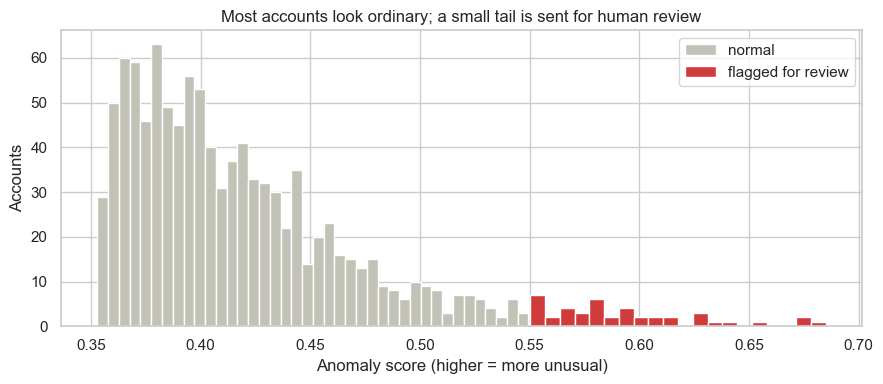

Review queue saved: DPF_outputs/anomaly_review_queue.xlsx


In [223]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(acct.loc[~acct["anomaly_flag"], "anomaly_score"], bins=40, color="#c3c2b7", label="normal")
ax.hist(acct.loc[acct["anomaly_flag"], "anomaly_score"], bins=20, color=COLOURS["critical"], label="flagged for review")
ax.set_xlabel("Anomaly score (higher = more unusual)")
ax.set_ylabel("Accounts")
ax.set_title("Most accounts look ordinary; a small tail is sent for human review")
ax.legend()
plt.tight_layout()
plt.show()

review_queue.to_excel(OUTPUT_DIR / "anomaly_review_queue.xlsx", index=False)
print("Review queue saved:", OUTPUT_DIR / "anomaly_review_queue.xlsx")

### 🔬 Case Study 5A — investigate before acting
1. Look at the original values. 2. Check the business rules. 3. Compare with similar records.
4. Is there a legitimate explanation (e.g. a large estate)? 5. Document the outcome.
6. Only then decide: data correction, new rule, or no action.

💬 One of the model-only finds is an individual savings account of several **billion** shillings.
What rule would you add so that next month's run catches it without ML?

## 5.3 ML part 2 — predicting awareness of DPF (supervised learning)

**Business question:** DPF's awareness campaigns cost money. *Which groups are least likely to have heard of
DPF?* A model trained on the survey answers that, and lets us score any profile.

**Steps:** choose target and features → split into **training** and **test** sets → train → compare with a
**baseline** → measure on the test set → interpret → use.

In [224]:
FEATURES = ["Region", "Area", "Gender", "Age Group", "Education", "Has Account at Financial Institution", "Survey Wave"]
X = survey[FEATURES].astype(str)                      # all categories (wave as text: 2025 / 2026)
y = (survey["Heard of DPF"] == "Yes").astype(int)     # 1 = aware

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print("Training rows:", len(X_train), " Test rows:", len(X_test), f" Aware in training set: {y_train.mean():.1%}")

Training rows: 675  Test rows: 225  Aware in training set: 51.3%


In [225]:
encode = ColumnTransformer([("categories", OneHotEncoder(drop="first"), FEATURES)])

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
logit = Pipeline([("encode", encode), ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
tree = Pipeline([("encode", encode), ("model", DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=42))]).fit(X_train, y_train)

results = []
for name, model in [("Baseline (always guess the majority)", baseline), ("Logistic regression", logit), ("Decision tree (3 levels)", tree)]:
    probability = model.predict_proba(X_test)[:, 1]
    results.append({"Model": name, "Accuracy %": accuracy_score(y_test, model.predict(X_test)) * 100,
                    "ROC AUC": roc_auc_score(y_test, probability)})
pd.DataFrame(results).round(3)

,Model,Accuracy %,ROC AUC
0,Baseline (always guess the majority),51.11,0.50
1,Logistic regression,71.11,0.80
2,Decision tree (3 levels),68.89,0.75


**Reading the metrics:** *Accuracy* = share of correct predictions (compare with the baseline, not with 100%).
*ROC AUC* = how well the model ranks aware above unaware people: 0.5 is a coin toss, 1.0 is perfect.

              precision    recall  f1-score   support

   Not aware       0.73      0.65      0.69       110
       Aware       0.70      0.77      0.73       115

    accuracy                           0.71       225
   macro avg       0.71      0.71      0.71       225
weighted avg       0.71      0.71      0.71       225



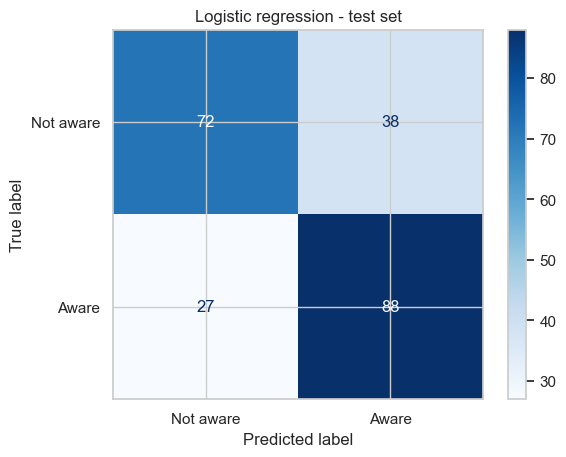

In [226]:
print(classification_report(y_test, logit.predict(X_test), target_names=["Not aware", "Aware"]))
ConfusionMatrixDisplay.from_estimator(logit, X_test, y_test, display_labels=["Not aware", "Aware"], cmap="Blues")
plt.title("Logistic regression - test set")
plt.show()

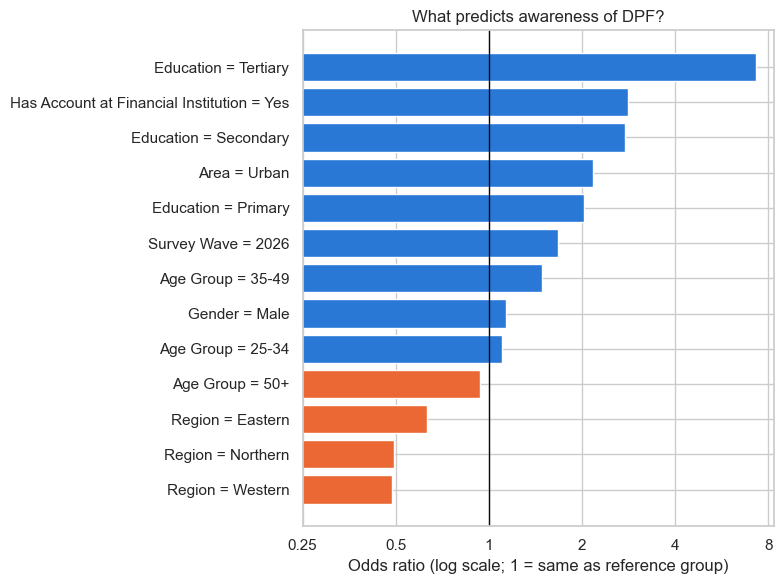

Reference groups (left out of the chart): the first category of each feature, e.g. Region = Central, Education = No formal.


In [227]:
# Interpret: odds ratios. > 1 means MORE likely to be aware than the reference group, < 1 LESS likely.
names = logit.named_steps["encode"].get_feature_names_out()
odds = pd.DataFrame({"Feature": [n.replace("categories__", "").replace("_", " = ") for n in names],
                     "Odds ratio": np.exp(logit.named_steps["model"].coef_[0])}).sort_values("Odds ratio")

fig, ax = plt.subplots(figsize=(8, 6))
colours = [COLOURS["outstanding"] if v < 1 else COLOURS["protected"] for v in odds["Odds ratio"]]
ax.barh(odds["Feature"], odds["Odds ratio"], color=colours)
ax.axvline(1, color="#0b0b0b", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"])
ax.minorticks_off()
ax.set_xlabel("Odds ratio (log scale; 1 = same as reference group)")
ax.set_title("What predicts awareness of DPF?")
plt.tight_layout()
plt.show()
print("Reference groups (left out of the chart): the first category of each feature, e.g. Region = Central, Education = No formal.")

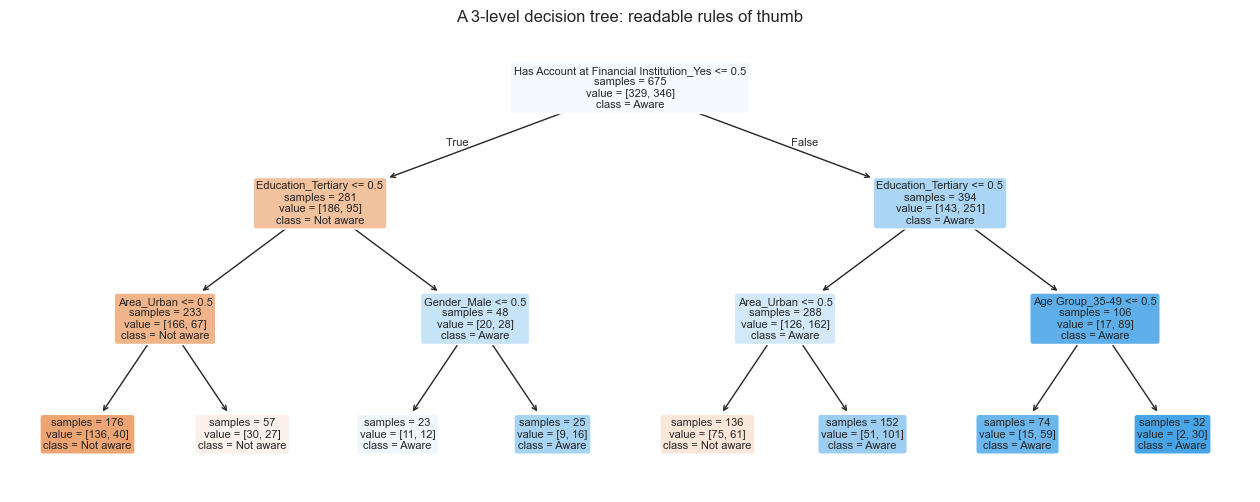

In [228]:
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(tree.named_steps["model"], feature_names=[n.replace("categories__", "") for n in names],
          class_names=["Not aware", "Aware"], filled=True, rounded=True, fontsize=8, impurity=False, ax=ax)
ax.set_title("A 3-level decision tree: readable rules of thumb")
plt.show()

In [229]:
# USE the model: score profiles to decide where campaigns should go
profiles = pd.DataFrame([
    {"Region": "Northern", "Area": "Rural", "Gender": "Female", "Age Group": "18-24", "Education": "Primary",
     "Has Account at Financial Institution": "No", "Survey Wave": "2026"},
    {"Region": "Central", "Area": "Urban", "Gender": "Male", "Age Group": "35-49", "Education": "Tertiary",
     "Has Account at Financial Institution": "Yes", "Survey Wave": "2026"},
    {"Region": "Eastern", "Area": "Rural", "Gender": "Male", "Age Group": "50+", "Education": "Secondary",
     "Has Account at Financial Institution": "Yes", "Survey Wave": "2026"},
])
profiles["Predicted chance of being aware"] = [f"{p:.0%}" for p in logit.predict_proba(profiles[FEATURES])[:, 1]]
profiles

,Region,Area,Gender,Age Group,Education,Has Account at Financial Institution,Survey Wave,Predicted chance of being aware
0,Northern,Rural,Female,18-24,Primary,No,2026,19%
1,Central,Urban,Male,35-49,Tertiary,Yes,2026,95%
2,Eastern,Rural,Male,50+,Secondary,Yes,2026,56%


> **Use with care.** The model describes *this* survey's respondents. It shows association, not cause
> (radio may raise awareness — or aware people may remember radio). Never use such a model to treat
> individual depositors differently; use it to **plan** campaigns, then measure the effect in the next wave.

---
## 🧪 DAY 5 LAB TASKS (homework, or during capstone preparation)

| # | Task | Skills |
|---|---|---|
| 1 | **Predict failed payments.** In `payout_clean`, keep claims that are not *Pending*. Target = status is *Failed* or *Returned*. Features: `Payment Channel`, `provider_std`, `Region`, and your Day 3 flags P5 (shared number) and P6 (name mismatch). Train a logistic regression; compare accuracy with the baseline; report ROC AUC. Which feature matters most? | train/test split, pipeline, odds ratios |
| 2 | **Unusual payments.** Build features per claim: verified claim (log), amount paid ÷ verified claim, days from closure to payment. Run an Isolation Forest and list the 10 most unusual claims with a reason. Do they match your P2–P4 rule flags? | feature engineering, IsolationForest |

In [230]:
# Task 1

In [231]:
# Task 2

## 5.4 Tableau — interactive dashboards from the Python outputs

**Why both?** Python does the heavy lifting that must be **repeatable and auditable** (cleaning, rules,
the per-depositor calculation). Tableau is excellent for **exploring and sharing** the results with
drag-and-drop filters. The hand-over point is a tidy data file.

### Step 1 — export Tableau-ready data (one Excel file, several sheets)

In [232]:
TABLEAU_FILE = OUTPUT_DIR / "DPF_Tableau_Data.xlsx"

accounts_out = acct[["Record ID", "depositor_key", "institution_code", "Contributing Institution", "Client Type",
                     "Account Title/Name", "Account Number", "Domicile Branch Name", "Region", "Latitude", "Longitude",
                     "Account Currency", "ugx_value", "npa_ugx", "Alternative channel",
                     "payout_status", "has_exception", "has_critical", "n_rules_failed", "risk_score",
                     "anomaly_flag", "anomaly_score"] + RULE_COLUMNS].copy()
accounts_out = accounts_out.rename(columns={"depositor_key": "Depositor Key", "institution_code": "Institution Code",
                                            "ugx_value": "UGX Value", "npa_ugx": "NPA UGX", "payout_status": "Payout Status"})
bool_cols = accounts_out.select_dtypes("bool").columns
accounts_out[bool_cols] = accounts_out[bool_cols].astype(int)          # Tableau sums 1/0 easily

depositors_out = dep.rename(columns={"depositor_key": "Depositor Key", "institution_code": "Institution Code"}).copy()
depositors_out["fully_protected"] = depositors_out["fully_protected"].astype(int)
depositors_out["any_account_not_computable"] = depositors_out["any_account_not_computable"].astype(int)

exceptions_out = pd.read_pickle(OUTPUT_DIR / "exception_register.pkl").rename(columns={"institution_code": "Institution Code"})
survey_out = survey.drop(columns=["Recommend group"], errors="ignore")

with pd.ExcelWriter(TABLEAU_FILE, engine="openpyxl") as writer:
    accounts_out.to_excel(writer, sheet_name="Accounts", index=False)
    depositors_out.to_excel(writer, sheet_name="Depositors", index=False)
    exceptions_out.to_excel(writer, sheet_name="Exceptions", index=False)
    survey_out.to_excel(writer, sheet_name="Survey", index=False)
    branches.to_excel(writer, sheet_name="Branches", index=False)
print("Tableau file written:", TABLEAU_FILE)
for name, t in [("Accounts", accounts_out), ("Depositors", depositors_out), ("Exceptions", exceptions_out), ("Survey", survey_out)]:
    print(f"  {name:<11} {t.shape[0]:>5} rows x {t.shape[1]} columns")

Tableau file written: DPF_outputs/DPF_Tableau_Data.xlsx
  Accounts     1058 rows x 42 columns
  Depositors    894 rows x 21 columns
  Exceptions    522 rows x 16 columns
  Survey        900 rows x 18 columns


### Step 2 — install and connect
1. Install **Tableau Public** (free) from **https://public.tableau.com** → *Create* → *Download the app*
   (or use **Tableau Desktop** if DPF has a licence).
2. Open Tableau → under **Connect** choose **Microsoft Excel** → select `DPF_outputs/DPF_Tableau_Data.xlsx`.
3. On the **Data Source** page drag **Accounts** onto the canvas. Then drag **Depositors** next to it — Tableau
   draws a *relationship* (noodle): set it to `Depositor Key = Depositor Key`. Drag **Exceptions** and relate it
   to Accounts on `Record ID = Record ID`. Keep **Survey** as a separate data source (Data → New Data Source).
4. ⚠️ **Check the data types** (the small icon above each column): `Record ID`, `Account Number`, `Depositor Key`
   must be **Abc (string)** — the same identifier lesson as Day 1. Set `Latitude`/`Longitude` to
   *Geographic Role → Latitude / Longitude*.

> **⚠️ Data protection:** saving in Tableau **Public** publishes the workbook on the internet for anyone to see.
> Use it only with this **dummy** data. Real SCV data stays inside DPF (Tableau Desktop/Server, or local files).

### Step 3 — build the views (one worksheet each)

| # | Worksheet | How |
|---|---|---|
| 1 | **KPI tiles** | Drag `Depositor Key` (Depositors) to *Text* → change to *Count (Distinct)*. Make calculated fields (below) for Protected (UGX bn), Exception rate, Ready-to-pay %. One small sheet per KPI, or Measure Names/Values on Text. |
| 2 | **Exceptions heatmap** | From **Exceptions**: `Rule` → Rows, `Institution Code` → Columns, `Record ID` (Count) → *Colour* and *Label*. Marks: *Square*. Sort rules by count. |
| 3 | **Payout readiness** | From **Depositors**: `Institution Code` → Rows, `Depositor Key` (Count Distinct) → Columns, `Payout Status` → Colour. Edit colours: green Ready, amber review, red Blocked. |
| 4 | **Branch map** | Double-click `Latitude` and `Longitude` (Accounts). `Domicile Branch Name` → Detail, `Record ID` (Count) → Size, `Exception rate` → Colour. |
| 5 | **Awareness** | Survey source: `Region` → Rows, `Survey Wave` → Columns (as discrete), `Aware %` (calc below) → Text/Colour. |
| 6 | **What-if limit** | Depositors source: create the **Protection Limit** parameter, show the control, put `Protected (what-if)` in a bar by institution. Move the slider: 10M → 20M. |

### Calculated fields (Analysis → Create Calculated Field)
```
Exception rate        :  SUM([Has Exception]) / COUNT([Record ID])
Protected (UGX bn)    :  SUM([Protected]) / 1000000000
Ready to pay %        :  SUM(IF [Payout Status] = "Ready to pay" THEN 1 ELSE 0 END) / COUNT([Depositor Key])
Aware %               :  SUM(IF [Heard Of Dpf] = "Yes" THEN 1 ELSE 0 END) / COUNT([Respondent Id])

// Parameter "Protection Limit": Integer, current value 10000000, range 1000000 to 50000000, step 1000000
Protected (what-if)   :  MIN(MAX([Amount Due], 0), [Protection Limit])

// LOD expression: recompute a depositor's amount due from the ACCOUNTS table, like Python's groupby
Depositor amount due (LOD) : { FIXED [Depositor Key] : SUM([UGX Value]) - SUM([NPA UGX]) }
```
✅ **Check your Tableau against Python:** put `Depositor Key` on Rows and `Depositor amount due (LOD)` next to
`Amount Due` from the Depositors sheet — they must match. (Tableau field names may show with different capitals.)

### Step 4 — assemble the dashboard
1. **Dashboard → New Dashboard**; size *Automatic* (or 1366 × 768).
2. Drag the KPI sheets across the top, heatmap and readiness bar in the middle, map and awareness at the bottom.
3. Add a filter: on the readiness sheet click `Institution Code` filter → *Apply to Worksheets → All Using Related Data Sources*.
4. **Dashboard → Actions → Add Action → Filter**: clicking a bank in the readiness chart filters the heatmap and map.
5. Add a title, the reporting date and a one-line *"what to do next"* text box.
6. Save: Tableau Public → *File → Save to Tableau Public* (dummy data only!); Tableau Desktop → *File → Save As .twbx*.

### Tableau lab checklist
- [ ] Data types checked (IDs are strings)
- [ ] Relationships set (Accounts–Depositors, Accounts–Exceptions)
- [ ] Six worksheets built, colours consistent with the Python charts
- [ ] LOD amount-due matches Python for 3 depositors you pick
- [ ] What-if parameter working
- [ ] Dashboard with filter action and title

## 5.5 Capstone project

**Brief:** *A new SCV return has arrived. In groups of 3–4, take it from raw file to decisions.*
Use the `SCV_Dummy_Data` sheet (or, for an extra challenge, the four raw exports) and present in **7 minutes**.

### Deliverables
| # | Deliverable | Contents |
|---|---|---|
| 1 | **Data product** | cleaned SCV, depositor-level protection, rule flags, anomaly flags (Python) |
| 2 | **Quality report** | exception counts by rule and bank; % of accounts with an exception; top 3 issues |
| 3 | **Supervisory dashboard** | Tableau (or Plotly) — at least 4 views, one filter |
| 4 | **Findings** | three findings in the four-part format below |
| 5 | **Recommendation** | one thing DPF should change in its process, and why |

### The four-part finding
| Part | Question | Example |
|---|---|---|
| Finding | What does the data show? | 18 accounts use one mobile-money number |
| Evidence | Which table/chart shows it? | Rule R13 list; Sankey of payment channels |
| Meaning | What could it mean? | account-opening error, or diversion risk |
| Next step | What should a person check? | hold payouts; ask the banks to re-verify KYC |

### Assessment rubric
| Criterion | Weight |
|---|---|
| Pipeline runs end to end without manual edits | 25% |
| Correctness of the protected-deposit calculation (per depositor) | 20% |
| Quality and clarity of exception reporting | 20% |
| Dashboard design (question-first, consistent colour, readable) | 20% |
| Findings & recommendation (four-part, actionable) | 15% |

In [233]:
# CAPSTONE WORKSPACE - the full pipeline in one cell (change the sheet name to run on another file)
raw_c = read_scv("SCV_Dummy_Data")
clean_c, log_c = clean_scv(raw_c, branches)
acct_c, dep_c = compute_protection(clean_c)
acct_c = apply_rules(add_payment_columns(acct_c))
acct_c["identity_ok"] = ~(acct_c["R01_identification_invalid"] | acct_c["R02_nin_shared_by_different_people"])
acct_c["payment_ok"] = ~acct_c[payment_rules].any(axis=1)
dep_c["payout_status"] = dep_c["depositor_key"].map({k: readiness(g) for k, g in acct_c.groupby("depositor_key")})

print(f"{len(raw_c)} records -> {len(acct_c)} accounts -> {len(dep_c)} depositors")
print(f"Accounts with an exception: {acct_c['has_exception'].mean():.1%}")
print(f"Protected exposure: UGX {dep_c['protected'].sum() / 1e9:,.2f} bn")
print(dep_c["payout_status"].value_counts().to_string())

1064 records -> 1058 accounts -> 894 depositors
Accounts with an exception: 39.8%
Protected exposure: UGX 3.86 bn
payout_status
Ready to pay                709
Blocked - identity           87
Needs payment details        62
Ready with review            28
Blocked - amount unknown      8


In [234]:
# Your group's analysis continues here (add cells as needed)

## 5.6 Wrap-up — taking it back to your desk

### Everything this week, as a reusable toolkit
The file **`dpf_scv_toolkit.py`** (in the training pack) contains every function from this notebook —
cleaning, rules, the per-depositor calculation and the reports — plus one `run_pipeline()` function.
Next month's SCV run becomes:

In [235]:
try:
    import dpf_scv_toolkit as tk
    result = tk.run_pipeline(DATA_FILE, sheet="SCV_Dummy_Data", output_dir=OUTPUT_DIR / "toolkit_run")
    print(result["summary"])
except ModuleNotFoundError:
    print("Put dpf_scv_toolkit.py in the same folder as this notebook to try this cell.")

Put dpf_scv_toolkit.py in the same folder as this notebook to try this cell.


### Suggested next steps for DPF (sustainability plan)
1. **Standardise:** agree the target schema and one mapping dictionary per contributing institution;
   keep them in a shared folder with version control.
2. **Automate:** run `run_pipeline()` on every SCV return; send each institution its exception report
   within an agreed number of days; track the exception register (Open → Queried → Resolved).
3. **Measure:** a monthly data-quality score per institution (exception rate, critical exceptions, readiness %)
   — and share the trend with institutions.
4. **Strengthen rules:** add rules for what the anomaly model found (e.g. individual balances above a threshold).
5. **Survey:** keep the same questions each wave so awareness trends are comparable; target campaigns using the model.
6. **People:** nominate 2–3 "data champions" who own the toolkit, and run a short refresher after 3 months.

# 🧠 Final self-assessment
Rate yourself in words, not numbers.

**I can explain…** why identifiers are text · how conditional validation works · why blanks need business
context · how mappings consolidate bank files · why protection is computed per depositor · how severity and
payout readiness combine rules · how to choose a chart from a question · why ML supports, not replaces, rules.

**I can do…** load and inspect an SCV file · clean NINs and phones with LOOK → ACT → CHECK · consolidate four
formats · compute protected amounts · generate exception reports for every bank in one loop · build a dashboard
in Plotly and Tableau · run and explain an anomaly model.

**I still need help with…** *(write it down — this is the most useful line on the page)*

---
## 5.7 The Day 5 report as a dashboard (Streamlit)

Today's results (the anomaly review queue, rules vs model, the awareness model and the capstone run) are
turned into a **reporting dashboard**: a web page a supervisor can open, filter and download from, without
opening this notebook.

### What you need
| # | What | How |
|---|---|---|
| 1 | **Streamlit** (once) | In *Anaconda Prompt*: `pip install streamlit "pyarrow<21"` (the `pyarrow` part avoids a clash with NumPy 1.x) |
| 2 | Everything else | Already installed for this course: pandas, plotly, scikit-learn, openpyxl |
| 3 | **Today's results saved** | Run this notebook **from the top**, then STEP 1 and STEP 2 below, then **save the notebook (Ctrl + S)**: the *Notebook charts* tab reads the charts from the saved file |
| 4 | **Start the dashboard** | **Either** run STEP 3 below (the dashboard opens inside this notebook), **or** in *Anaconda Prompt*, `cd` to this folder, then `streamlit run dpf_day5_dashboard.py` |

A browser tab opens at `http://localhost:8501`. Stop it with **Ctrl + C** in the prompt window.
When you re-run the notebook (for example next month's SCV return), re-run the two cells below and refresh the page.

### What the dashboard shows
| Tab | Report content | Notebook section |
|---|---|---|
| Summary | Headline KPIs and the key findings, written out in sentences | 5.2, 5.3, 5.5 |
| Anomaly review | Flagged accounts with the reason, filters, score chart, branch map | 5.2 |
| Rules vs model | The 2 × 2 table, simple vs improved model, the "model-only" finds | 5.2 |
| Awareness | Model metrics, odds ratios, awareness by region and wave, score a profile | 5.3 |
| Capstone run | Accounts, depositors, protected exposure and payout readiness for the capstone file | 5.5 |
| Notebook charts | **Every chart in this notebook** (Days 1–5), under the notebook's own headings: the Sankeys, waterfall, treemap, map and KPI dashboard stay interactive; matplotlib/seaborn charts are shown as the notebook drew them | 2.2, 4.2–4.4, 5.2–5.3 |
| Downloads | The whole Day 5 report as **one Excel workbook**, plus each table as CSV | — |

> **⚠️ Data protection:** the dashboard runs **on your own computer** and reads only the files in `DPF_outputs/day5/`.
> Do not deploy it to Streamlit Community Cloud or any public site with real SCV data.

In [236]:
# STEP 1 - save today's results for the dashboard (run after all the Day 5 cells above)
import joblib

DAY5_DIR = OUTPUT_DIR / "day5"
DAY5_DIR.mkdir(parents=True, exist_ok=True)

# 1. Accounts with the anomaly results (only the columns the report needs)
report_cols = ["Record ID", "institution_code", "Contributing Institution", "Client Type", "Account Title/Name",
               "Domicile Branch Name", "Region", "Latitude", "Longitude", "Account Currency", "Current Balance",
               "Interest Due (Accrued)", "Exchange Rate Applicable", "ugx_value", "has_exception", "n_rules_failed",
               "anomaly_flag", "anomaly_score", "anomaly_reason"] + RULE_COLUMNS
acct_day5 = acct[[c for c in report_cols if c in acct.columns]].copy()
acct_day5["known_numeric_problem"] = known_numeric_problem
acct_day5.to_pickle(DAY5_DIR / "accounts_anomaly.pkl")

# 2. Rules vs model
comparison.to_pickle(DAY5_DIR / "model_comparison.pkl")
two_by_two.to_pickle(DAY5_DIR / "rules_vs_model.pkl")

# 3. Awareness model: metrics on the test set, odds ratios, the survey and the trained model itself
model_metrics = pd.DataFrame([
    {"Model": name,
     "Accuracy %": accuracy_score(y_test, m.predict(X_test)) * 100,
     "ROC AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
     "Recall (aware) %": recall_score(y_test, m.predict(X_test), zero_division=0) * 100,
     "Precision (aware) %": precision_score(y_test, m.predict(X_test), zero_division=0) * 100}
    for name, m in [("Baseline (always guess the majority)", baseline), ("Logistic regression", logit),
                    ("Decision tree (3 levels)", tree)]]).round(3)
model_metrics.to_pickle(DAY5_DIR / "awareness_metrics.pkl")
odds.to_pickle(DAY5_DIR / "awareness_odds.pkl")
survey.to_pickle(DAY5_DIR / "survey.pkl")
joblib.dump({"model": logit, "features": FEATURES}, DAY5_DIR / "awareness_model.joblib")

# 4. Capstone run
acct_c.to_pickle(DAY5_DIR / "capstone_accounts.pkl")
dep_c.to_pickle(DAY5_DIR / "capstone_depositors.pkl")

pd.Series({"reporting_date": str(pd.Timestamp(REPORTING_DATE).date()),
           "data_file": str(DATA_FILE),
           "created": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")}).to_pickle(DAY5_DIR / "meta.pkl")

for f in sorted(DAY5_DIR.iterdir()):
    print(f"  saved {f.name}")
print("Day 5 results saved in", DAY5_DIR)

  saved accounts_anomaly.pkl
  saved awareness_metrics.pkl
  saved awareness_model.joblib
  saved awareness_odds.pkl
  saved capstone_accounts.pkl
  saved capstone_depositors.pkl
  saved meta.pkl
  saved model_comparison.pkl
  saved rules_vs_model.pkl
  saved survey.pkl
Day 5 results saved in DPF_outputs/day5


In [ ]:
%%writefile dpf_day5_dashboard.py
# STEP 2 - write the dashboard script. Running this cell saves everything below as dpf_day5_dashboard.py
"""
DPF Single Customer View - Day 5 reporting dashboard
=====================================================

What it is
    A small web page that shows the results of the training notebook so a
    supervisor can read, filter and download them without opening the notebook.

Where the content comes from (everything is from the notebook)
    1. Tables and numbers: the notebook (section 5.7, "STEP 1") saves its Day 5
       results as files in DPF_outputs/day5/. This script only READS those files.
       It does no cleaning and no modelling of its own.
    2. Charts: the "Notebook charts" tab reads the saved notebook file
       (DPF_SCV_5Day_Training_NotebookV2.ipynb) and shows every chart it drew, Days 1-5,
       under the notebook's own headings. Interactive Plotly charts (Sankey, treemap,
       waterfall, map, KPI dashboard) are redrawn as interactive charts; matplotlib and
       seaborn charts are shown as the exact pictures the notebook made.
       => Save the notebook (Ctrl + S) after running it, so the saved charts are current.

How to run it
    In Anaconda Prompt, in the folder that holds this file:
        pip install streamlit "pyarrow<21"      (once)
        streamlit run dpf_day5_dashboard.py
    A browser tab opens at http://localhost:8501. Stop it with Ctrl + C.
    (Or use STEP 3 in section 5.7 of the notebook to open it inside the notebook.)

How Streamlit works, in one paragraph
    Streamlit runs this whole file from top to bottom every time the user
    touches a filter or button. Each st.something(...) call draws one piece of
    the page (a title, a chart, a table). There are no callbacks: the value of
    a filter is simply the return value of the call that draws it.
"""

import base64               # notebook pictures are stored as base64 text inside the .ipynb file
import json                 # a .ipynb notebook file is JSON
from datetime import datetime
from io import BytesIO      # an in-memory "file", used to build the Excel download
from pathlib import Path    # works with file paths on Windows and Mac alike

import joblib               # loads the trained awareness model saved by the notebook
import pandas as pd
import plotly.express as px  # interactive charts
import plotly.io as pio      # rebuilds the notebook's saved Plotly charts
import streamlit as st       # turns this script into a web page


# =============================================================================
# 1. SETTINGS
# =============================================================================

HERE = Path(__file__).parent                       # the folder this script is in

# Folder where the notebook saved the Day 5 results (STEP 1 of section 5.7).
DAY5_DIR = HERE / "DPF_outputs" / "day5"

# The training notebook; its saved charts are shown in the "Notebook charts" tab.
NOTEBOOK_FILE = HERE / "DPF_SCV_5Day_Training_NotebookV2.ipynb"

# One colour per meaning, used the same way on every chart (as in the notebook).
COLOURS = {
    "critical": "#c0392b",   # red    - blocked / flagged / a problem
    "review":   "#e6a23c",   # amber  - needs a person to look at it
    "ok":       "#2e8b57",   # green  - fine / ready
    "neutral":  "#c3c2b7",   # grey   - background, "normal"
    "dark":     "#1f3b57",   # navy   - plain bars with no good/bad meaning
}

# Colour for each payout status the notebook produces.
STATUS_COLOURS = {
    "Ready to pay":             COLOURS["ok"],
    "Ready with review":        "#8fbf6a",          # light green: ready, but check first
    "Needs payment details":    COLOURS["review"],
    "Blocked - identity":       COLOURS["critical"],
    "Blocked - amount unknown": "#7b1d14",          # dark red
}

# The columns shown in the anomaly review queue table, in this order.
REVIEW_COLUMNS = [
    "Record ID", "institution_code", "Client Type", "Account Title/Name", "Account Currency",
    "Current Balance", "Interest Due (Accrued)", "Exchange Rate Applicable",
    "anomaly_score", "anomaly_reason", "has_exception",
]

# Page title, browser-tab icon and a wide layout (use the whole screen width).
# This must be the first Streamlit call in the script.
st.set_page_config(page_title="DPF Day 5 report", page_icon="📊", layout="wide")

# Make charts and tables fill their column.
# Newer Streamlit (1.46+) spells this width="stretch"; older versions use use_container_width=True.
# WIDE holds whichever one this computer's Streamlit understands; we pass it as **WIDE.
streamlit_version = tuple(int(part) for part in st.__version__.split(".")[:2])
WIDE = {"width": "stretch"} if streamlit_version >= (1, 46) else {"use_container_width": True}


# =============================================================================
# 2. LOADING THE DATA
# =============================================================================

@st.cache_data   # read the files once, then reuse them (Streamlit re-runs the script on every click)
def load_results():
    """Read every .pkl file in DAY5_DIR into a dictionary: {file name: table}.

    Returns None if the folder does not exist yet (the notebook has not been run).
    """
    if not DAY5_DIR.exists():
        return None
    return {path.stem: pd.read_pickle(path) for path in DAY5_DIR.glob("*.pkl")}


@st.cache_resource   # load the model once and keep it in memory
def load_awareness_model():
    """Load the trained awareness model: {"model": the pipeline, "features": its input columns}."""
    path = DAY5_DIR / "awareness_model.joblib"
    return joblib.load(path) if path.exists() else None


@st.cache_data
def load_notebook_charts(notebook_path, last_saved):
    """Collect every chart saved in the notebook, in notebook order.

    A notebook file stores each cell's results ("outputs"). A matplotlib/seaborn chart
    is saved as a PNG picture ("image/png"); a Plotly chart is saved as its full
    definition ("application/vnd.plotly.v1+json"), so it can be redrawn exactly.

    `last_saved` is not used inside; it is there so the cache refreshes when the
    notebook is saved again.

    Returns a list of dicts: day, section (the heading above the chart), cell number,
    kind ("plotly" or "image") and the chart itself.
    """
    notebook = json.loads(Path(notebook_path).read_text(encoding="utf-8"))
    charts = []
    day, section = "Setup", ""

    for cell_number, cell in enumerate(notebook["cells"]):
        text = "".join(cell["source"])

        # Text cells: remember the latest "# DAY n" and the latest ## / ### heading.
        if cell["cell_type"] == "markdown":
            for line in text.splitlines():
                if line.startswith("# DAY"):
                    day = line.lstrip("# ").split(" — ")[0].title()      # "# DAY 4 — Visual..." -> "Day 4"
                elif line.startswith("##"):
                    section = line.lstrip("# ").strip()
            continue

        # Code cells: keep each chart in the cell's outputs.
        for output in cell.get("outputs", []):
            data = output.get("data", {})
            if "application/vnd.plotly.v1+json" in data:
                charts.append({"day": day, "section": section, "cell": cell_number,
                               "kind": "plotly", "chart": data["application/vnd.plotly.v1+json"]})
            elif "image/png" in data:
                png = data["image/png"]
                png = "".join(png) if isinstance(png, list) else png
                charts.append({"day": day, "section": section, "cell": cell_number,
                               "kind": "image", "chart": base64.b64decode(png)})
    return charts


def to_excel(sheets):
    """Turn {sheet name: table} into the bytes of one Excel workbook (for the download button)."""
    buffer = BytesIO()
    with pd.ExcelWriter(buffer, engine="openpyxl") as writer:
        for name, table in sheets.items():
            # Keep the index only when it means something (e.g. the 2 x 2 table's row labels).
            keep_index = not isinstance(table.index, pd.RangeIndex)
            table.to_excel(writer, sheet_name=name[:31], index=keep_index)   # Excel allows 31 characters
    return buffer.getvalue()


def to_csv(table):
    """Turn one table into CSV bytes (for a download button)."""
    keep_index = not isinstance(table.index, pd.RangeIndex)
    return table.to_csv(index=keep_index).encode("utf-8")


def bar_chart(series, title, horizontal=False):
    """A plain one-colour bar chart of a pandas Series (labels = index, bar length = values)."""
    fig = px.bar(series, orientation="h" if horizontal else "v", title=title,
                 labels={"value": "Accounts", "index": ""}, color_discrete_sequence=[COLOURS["dark"]])
    return fig.update_layout(showlegend=False)


# ---- Read everything; stop with a clear message if the notebook has not been run ----
results = load_results()
if results is None:
    st.error(f"No Day 5 results found in `{DAY5_DIR}`. "
             "Run the notebook from the top, then the cells in section 5.7.")
    st.stop()   # nothing else on the page can work without the data

accounts = results["accounts_anomaly"]          # one row per account, with anomaly_flag / score / reason
comparison = results["model_comparison"]        # simple vs improved anomaly model (recall, precision)
metrics = results["awareness_metrics"]          # awareness model results on the test set
odds_ratios = results["awareness_odds"]         # what predicts awareness (odds ratios)
survey = results["survey"]                      # the awareness survey answers
capstone_accounts = results["capstone_accounts"]
capstone_depositors = results["capstone_depositors"]
meta = results.get("meta", pd.Series(dtype=str))   # reporting date and when the results were saved


# =============================================================================
# 3. SIDEBAR FILTERS
# =============================================================================
# The filters narrow the accounts shown in the Summary, Anomaly review and Rules vs model tabs.

st.sidebar.header("Filters")

all_banks = sorted(accounts["institution_code"].dropna().unique())
all_client_types = sorted(accounts["Client Type"].dropna().unique())

chosen_banks = st.sidebar.multiselect("Institution", all_banks, default=all_banks)
chosen_client_types = st.sidebar.multiselect("Client type", all_client_types, default=all_client_types)

st.sidebar.caption(f"Reporting date: {meta.get('reporting_date', '-')}  \n"
                   f"Results saved: {meta.get('created', '-')}")
st.sidebar.caption("Filters apply to the Summary, Anomaly review and Rules vs model tabs.")

# The accounts that match the filters, and the subsets the report talks about.
in_view = accounts[accounts["institution_code"].isin(chosen_banks)
                   & accounts["Client Type"].isin(chosen_client_types)]
flagged = in_view[in_view["anomaly_flag"]]           # the model thinks these look unusual
model_only = flagged[~flagged["has_exception"]]      # unusual, yet they pass every rule


# =============================================================================
# 4. HEADLINE NUMBERS (used in the Summary tab and in the Excel download)
# =============================================================================

simple_model = comparison.iloc[0]       # first row  = raw amounts only
improved_model = comparison.iloc[-1]    # last row   = engineered features
logistic = metrics[metrics["Model"] == "Logistic regression"].iloc[0]
baseline = metrics[metrics["Model"].str.startswith("Baseline")].iloc[0]

share_aware = (survey["Heard of DPF"] == "Yes").mean()
share_ready = (capstone_depositors["payout_status"] == "Ready to pay").mean()
protected_bn = capstone_depositors["protected"].sum() / 1e9


def percent_of(part, whole):
    """part / whole, safe when whole is 0 (e.g. every filter cleared)."""
    return part / whole if whole else 0


# =============================================================================
# 5. ONE FUNCTION PER TAB
# =============================================================================

def summary_tab():
    """Headline KPIs and the key findings, written as sentences for a report."""
    c1, c2, c3, c4, c5 = st.columns(5)
    c1.metric("Accounts checked", f"{len(in_view):,}")
    c2.metric("Flagged as unusual", f"{len(flagged):,}",
              f"{percent_of(len(flagged), len(in_view)):.1%} of accounts", delta_color="off")
    c3.metric("Unusual, passing every rule", f"{len(model_only):,}", "investigate first", delta_color="off")
    c4.metric("Known problems found (recall)", f"{improved_model['Recall %']:.0f}%",
              f"{improved_model['Recall %'] - simple_model['Recall %']:+.0f} pts vs simple model")
    c5.metric("Awareness model ROC AUC", f"{logistic['ROC AUC']:.2f}", "0.5 = coin toss", delta_color="off")

    st.subheader("Key findings")

    # The most common reason for a flag. Reasons look like "unusual X; unusual Y", so split them first.
    reasons = flagged["anomaly_reason"].str.split("; ").explode().value_counts()

    findings = [
        f"**{len(flagged):,} of {len(in_view):,} accounts** ({percent_of(len(flagged), len(in_view)):.1%}) "
        "were flagged as unusual for human review.",
        f"**{len(model_only):,} flagged accounts pass every rule.** "
        "These are the model's added value and should be investigated first.",
        f"Using engineered features, the model finds **{improved_model['Recall %']:.0f}%** of the known "
        f"numeric problems, compared with **{simple_model['Recall %']:.0f}%** using raw amounts only.",
    ]
    if len(reasons):
        findings.append(f"The most common reason for a flag is **{reasons.index[0]}** ({reasons.iloc[0]} accounts).")
    findings += [
        f"**{share_aware:.0%}** of survey respondents have heard of DPF. The awareness model ranks respondents "
        f"with ROC AUC **{logistic['ROC AUC']:.2f}**. Its accuracy is {logistic['Accuracy %']:.1f}%, against "
        f"{baseline['Accuracy %']:.1f}% for always guessing the majority answer.",
        f"Capstone run: **{len(capstone_accounts):,} accounts, {len(capstone_depositors):,} depositors**, "
        f"protected exposure **UGX {protected_bn:,.2f} bn**, {share_ready:.1%} of depositors ready to pay.",
    ]
    st.markdown("\n".join(f"{number}. {text}" for number, text in enumerate(findings, start=1)))
    st.info("A flagged record is a question, not a verdict. "
            "ML prioritises where people look; it does not replace the rules.")


def anomaly_tab():
    """The review queue: which accounts look unusual, and why."""
    if in_view.empty:
        st.warning("No accounts match the filters.")
        return

    # --- Controls ---
    lowest, highest = float(in_view["anomaly_score"].min()), float(in_view["anomaly_score"].max())
    # Start the slider at the model's own cut-off (the lowest score that was flagged).
    start = float(flagged["anomaly_score"].min()) if len(flagged) else highest
    threshold = st.slider("Show accounts with an anomaly score of at least", lowest, highest, start)
    only_model_finds = st.checkbox("Only accounts that pass every rule (model-only finds)")

    queue = in_view[in_view["anomaly_score"] >= threshold]
    if only_model_finds:
        queue = queue[~queue["has_exception"]]

    left, right = st.columns(2)

    # --- Chart 1: how the scores are spread, with the threshold marked (notebook 5.2 histogram) ---
    labelled = in_view.assign(Flag=in_view["anomaly_flag"].map({True: "Flagged for review", False: "Normal"}))
    histogram = px.histogram(labelled, x="anomaly_score", color="Flag", nbins=60, title="Anomaly score distribution",
                             color_discrete_map={"Flagged for review": COLOURS["critical"], "Normal": COLOURS["neutral"]})
    histogram.add_vline(x=threshold, line_dash="dash")
    left.plotly_chart(histogram, **WIDE)

    # --- Chart 2: the reasons given for the accounts in the queue ---
    reasons = queue["anomaly_reason"].replace("", pd.NA).dropna().str.split("; ").explode().value_counts()
    right.plotly_chart(bar_chart(reasons.sort_values(), "Why accounts were flagged", horizontal=True), **WIDE)

    # --- Chart 3: the queue by institution ---
    by_bank = queue.groupby("institution_code").size()
    left.plotly_chart(bar_chart(by_bank, "Accounts in this view, by institution"), **WIDE)

    # --- Chart 4: map of the branches those accounts belong to ---
    has_coordinates = {"Latitude", "Longitude"}.issubset(queue.columns) and queue["Latitude"].notna().any()
    if has_coordinates:
        right.plotly_chart(branch_map(queue), **WIDE)

    # --- The table itself, plus a download ---
    st.subheader(f"Review queue: {len(queue):,} accounts")
    table = queue.sort_values("anomaly_score", ascending=False)[REVIEW_COLUMNS]
    st.dataframe(table, hide_index=True, **WIDE)
    st.download_button("Download this review queue (CSV)", to_csv(table), "day5_anomaly_review_queue.csv", "text/csv")


def branch_map(queue):
    """A map with one bubble per branch; bubble size = number of accounts in the queue."""
    branches = (queue.dropna(subset=["Latitude", "Longitude"])
                .groupby(["Domicile Branch Name", "Latitude", "Longitude"]).size()
                .rename("Accounts").reset_index())

    # Plotly 5.24+ renamed scatter_mapbox -> scatter_map (and mapbox_style -> map_style).
    # Use whichever this computer has.
    if hasattr(px, "scatter_map"):
        make_map, style = px.scatter_map, {"map_style": "open-street-map"}
    else:
        make_map, style = px.scatter_mapbox, {"mapbox_style": "open-street-map"}

    fig = make_map(branches, lat="Latitude", lon="Longitude", size="Accounts", hover_name="Domicile Branch Name",
                   zoom=5.5, height=380, title="Branches of the accounts in this view",
                   color_discrete_sequence=[COLOURS["critical"]])
    return fig.update_layout(margin=dict(l=0, r=0, t=40, b=0), **style)


def rules_vs_model_tab():
    """How the anomaly model compares with the 20 rules (notebook 5.2)."""
    left, right = st.columns(2)

    # The 2 x 2 table: rule exception yes/no  x  model unusual yes/no (same as the notebook's crosstab)
    two_by_two = pd.crosstab(in_view["has_exception"].map({True: "Rule exception", False: "No rule exception"}),
                             in_view["anomaly_flag"].map({True: "Model: unusual", False: "Model: normal"}))
    left.subheader("Rules vs model (2 × 2)")
    left.dataframe(two_by_two, **WIDE)
    left.caption("Bottom-right cell = unusual but passing every rule: the model's added value.")

    right.subheader("Simple vs improved anomaly model")
    right.dataframe(comparison, hide_index=True, **WIDE)

    # Recall and precision side by side for the two approaches
    long_format = comparison.melt(id_vars="Approach", value_vars=["Recall %", "Precision %"],
                                  var_name="Measure", value_name="%")
    st.plotly_chart(px.bar(long_format, x="Measure", y="%", color="Approach", barmode="group",
                           title="Finding the known numeric problems (whole dataset)",
                           color_discrete_sequence=[COLOURS["neutral"], COLOURS["dark"]]), **WIDE)

    st.subheader(f"Model-only finds: {len(model_only):,} accounts")
    st.dataframe(model_only.sort_values("anomaly_score", ascending=False)[
        ["Record ID", "institution_code", "Client Type", "Account Title/Name",
         "Account Currency", "Current Balance", "anomaly_reason"]], hide_index=True, **WIDE)


def awareness_tab():
    """The supervised model: who is likely to have heard of DPF (notebook 5.3)."""
    st.subheader("Awareness model: test-set results")
    st.dataframe(metrics, hide_index=True, **WIDE)

    left, right = st.columns(2)

    # --- Odds ratios: above 1 = more likely aware than the reference group ---
    chart_data = odds_ratios.assign(
        Direction=odds_ratios["Odds ratio"].map(lambda v: "More likely aware" if v >= 1 else "Less likely aware"))
    odds_chart = px.bar(chart_data, x="Odds ratio", y="Feature", orientation="h", color="Direction",
                        log_x=True, height=520, title="What predicts awareness of DPF? (1 = same as reference group)",
                        color_discrete_map={"More likely aware": COLOURS["ok"], "Less likely aware": COLOURS["critical"]})
    odds_chart.add_vline(x=1, line_color="black")
    left.plotly_chart(odds_chart, **WIDE)

    # --- Awareness % by region, one bar per survey wave (notebook 4.4) ---
    aware_by_region = (survey.assign(aware=survey["Heard of DPF"].eq("Yes"),
                                     wave=survey["Survey Wave"].astype(str))
                       .groupby(["Region", "wave"])["aware"].mean().mul(100).round(1)
                       .rename("Aware %").reset_index())
    right.plotly_chart(px.bar(aware_by_region, x="Region", y="Aware %", color="wave", barmode="group",
                              title="Awareness of DPF by region and survey wave", height=520,
                              labels={"wave": "Survey wave"},
                              color_discrete_sequence=[COLOURS["neutral"], COLOURS["dark"]]), **WIDE)

    # --- Score a profile with the trained model (notebook 5.3, "USE the model") ---
    saved = load_awareness_model()
    if saved is None:
        return
    st.subheader("Score a profile (for campaign planning)")
    boxes = st.columns(4)
    profile = {}
    for i, feature in enumerate(saved["features"]):
        choices = sorted(survey[feature].astype(str).unique())
        profile[feature] = boxes[i % 4].selectbox(feature, choices, key=feature)   # 4 dropdowns per row
    chance = saved["model"].predict_proba(pd.DataFrame([profile]))[0, 1]          # column 1 = "aware"
    st.metric("Predicted chance of being aware of DPF", f"{chance:.0%}")
    st.caption("Shows association, not cause. Use it to plan campaigns, "
               "never to treat individual depositors differently.")


def capstone_tab():
    """The full pipeline run on the capstone file (notebook section 5.5)."""
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Accounts", f"{len(capstone_accounts):,}")
    c2.metric("Depositors", f"{len(capstone_depositors):,}")
    c3.metric("Accounts with an exception", f"{capstone_accounts['has_exception'].mean():.1%}")
    c4.metric("Protected exposure (UGX bn)", f"{protected_bn:,.2f}")

    left, right = st.columns(2)

    status = capstone_depositors.groupby(["institution_code", "payout_status"]).size().rename("Depositors").reset_index()
    left.plotly_chart(px.bar(status, x="institution_code", y="Depositors", color="payout_status",
                             title="Payout readiness by institution", color_discrete_map=STATUS_COLOURS), **WIDE)

    # Rule columns are named R01_..., R02_... ; each is True/False per account, so the sum is a count.
    rule_counts = capstone_accounts.filter(regex=r"^R\d\d_").sum().sort_values().tail(10)
    right.plotly_chart(bar_chart(rule_counts, "Top 10 failing rules", horizontal=True), **WIDE)

    protected_by_bank = (capstone_depositors.groupby("institution_code")["protected"].sum()
                         .div(1e9).round(3).rename("Protected (UGX bn)").reset_index())
    st.dataframe(protected_by_bank, hide_index=True, **WIDE)


def notebook_charts_tab():
    """Every chart the notebook drew (Days 1-5), shown under the notebook's own headings."""
    if not NOTEBOOK_FILE.exists():
        st.warning(f"Notebook not found: `{NOTEBOOK_FILE.name}`. Keep it in the same folder as this script.")
        return

    last_saved = NOTEBOOK_FILE.stat().st_mtime
    charts = load_notebook_charts(str(NOTEBOOK_FILE), last_saved)
    if not charts:
        st.warning("The saved notebook has no charts yet. Run it from the top, then save it (Ctrl + S).")
        return

    st.caption(f"{len(charts)} charts read from `{NOTEBOOK_FILE.name}`, "
               f"saved {datetime.fromtimestamp(last_saved):%Y-%m-%d %H:%M}. "
               "Interactive charts can be zoomed and hovered; the others are the notebook's own pictures.")

    # Warn if the notebook was saved BEFORE the latest results: its charts may be out of date.
    created = meta.get("created")
    if created and datetime.fromtimestamp(last_saved) < datetime.strptime(created, "%Y-%m-%d %H:%M"):
        st.warning("The notebook was saved before the latest results were created, so these charts may be "
                   "out of date. Save the notebook (Ctrl + S) and refresh this page.")

    # Choose a day; then optionally one section of that day.
    days = list(dict.fromkeys(chart["day"] for chart in charts))       # in notebook order, no repeats
    day = st.radio("Day", days, horizontal=True)
    of_day = [chart for chart in charts if chart["day"] == day]
    sections = list(dict.fromkeys(chart["section"] for chart in of_day))
    section = st.selectbox("Section", ["All sections"] + sections)
    if section != "All sections":
        of_day = [chart for chart in of_day if chart["section"] == section]

    # Draw them, with a heading whenever the section changes.
    current_section = None
    for number, chart in enumerate(of_day):
        if chart["section"] != current_section:
            current_section = chart["section"]
            st.subheader(current_section)
        if chart["kind"] == "plotly":
            # Rebuild the notebook's Plotly figure from its saved definition (skip settings this Plotly lacks).
            figure = pio.from_json(json.dumps(chart["chart"]), skip_invalid=True)
            st.plotly_chart(figure, key=f"nb_chart_{chart['cell']}_{number}", **WIDE)
        else:
            st.image(chart["chart"])
        st.caption(f"Notebook cell {chart['cell'] + 1}")


def downloads_tab():
    """The whole Day 5 report as one Excel workbook, and each table as CSV."""
    st.subheader("Download the Day 5 report")

    # The Excel report covers ALL accounts (it ignores the sidebar filters).
    all_flagged = accounts["anomaly_flag"]
    summary = pd.DataFrame({
        "Measure": ["Accounts checked", "Flagged as unusual", "Unusual but passing every rule",
                    "Anomaly recall (improved) %", "Awareness model ROC AUC", "Survey: aware of DPF %",
                    "Capstone accounts", "Capstone depositors", "Capstone protected (UGX bn)",
                    "Capstone ready to pay %"],
        "Value": [len(accounts), int(all_flagged.sum()), int((all_flagged & ~accounts["has_exception"]).sum()),
                  round(improved_model["Recall %"], 1), round(logistic["ROC AUC"], 3), round(share_aware * 100, 1),
                  len(capstone_accounts), len(capstone_depositors), round(protected_bn, 3),
                  round(share_ready * 100, 1)],
    })
    review_queue = (accounts[all_flagged].sort_values("anomaly_score", ascending=False)
                    .drop(columns=["Latitude", "Longitude"], errors="ignore"))

    sheets = {
        "Summary": summary,
        "Anomaly review queue": review_queue,
        "Rules vs model": results["rules_vs_model"],
        "Model comparison": comparison,
        "Awareness metrics": metrics,
        "Awareness odds ratios": odds_ratios,
        "Capstone depositors": capstone_depositors,
    }

    st.download_button("Download full report (Excel)", to_excel(sheets), "DPF_Day5_Report.xlsx",
                       "application/vnd.openxmlformats-officedocument.spreadsheetml.sheet", type="primary")
    st.caption("The Excel report ignores the sidebar filters and covers all accounts.")

    st.divider()
    for name, table in sheets.items():
        file_name = f"day5_{name.lower().replace(' ', '_')}.csv"
        st.download_button(f"{name} (CSV)", to_csv(table), file_name, "text/csv", key=f"csv_{name}")


# =============================================================================
# 6. THE PAGE
# =============================================================================

st.title("DPF Single Customer View - Day 5 report")
st.caption("Predictive analytics: anomaly detection, awareness model and capstone run. Dummy training data.")

tabs = st.tabs(["Summary", "Anomaly review", "Rules vs model", "Awareness", "Capstone run",
                "Notebook charts", "Downloads"])
tab_functions = [summary_tab, anomaly_tab, rules_vs_model_tab, awareness_tab, capstone_tab,
                 notebook_charts_tab, downloads_tab]

for tab, draw in zip(tabs, tab_functions):
    with tab:      # everything drawn inside this block appears on that tab
        draw()


### STEP 3 — open the dashboard inside this notebook
Streamlit is a **web server**, not a chart, so it cannot draw directly in a cell. The cell below starts the server
in the background (with the same Python as this notebook) and shows the page in an embedded frame. You can also
open http://localhost:8501 in your browser. The notebook stays usable while the dashboard runs.
Run **STEP 4** to stop it. Restarting the kernel also stops it.

In [ ]:
# STEP 3 - start the dashboard in the background and show it here
import subprocess, sys, time, urllib.request
from IPython.display import IFrame, display

PORT = 8501
URL = f"http://localhost:{PORT}"


def dashboard_is_up():
    """True if a Streamlit server is answering on PORT."""
    try:
        return urllib.request.urlopen(f"{URL}/_stcore/health", timeout=1).read() == b"ok"
    except OSError:
        return False


if dashboard_is_up():
    print("The dashboard is already running.")
else:
    # sys.executable = this notebook's Python, so it uses the same packages (and finds streamlit if installed here)
    dashboard_process = subprocess.Popen(
        [sys.executable, "-m", "streamlit", "run", "dpf_day5_dashboard.py",
         "--server.headless", "true",          # do not open a browser tab by itself
         "--server.port", str(PORT)],
        stdout=subprocess.DEVNULL, stderr=subprocess.PIPE)
    for _ in range(60):                       # wait up to 30 seconds for it to start
        if dashboard_is_up() or dashboard_process.poll() is not None:
            break
        time.sleep(0.5)

if dashboard_is_up():
    print("Dashboard running at", URL, "(also open it in your browser for a full-size view)")
    display(IFrame(URL, width="100%", height=900))
else:
    print("The dashboard did not start. The error was:")
    print(dashboard_process.stderr.read().decode(errors="replace")[-2000:])
    print('If it says "No module named streamlit", run:  %pip install streamlit "pyarrow<21"  then restart the kernel.')

In [ ]:
# STEP 4 - stop the dashboard started in STEP 3
try:
    dashboard_process.terminate()
    dashboard_process.wait(timeout=10)
    print("Dashboard stopped.")
except NameError:
    print("No dashboard was started from this notebook session (nothing to stop).")

✅ **You should see** `Writing dpf_day5_dashboard.py` (or `Overwriting …`) after STEP 2, and the dashboard with six tabs after STEP 3. Use **Downloads → Download full report (Excel)** to get `DPF_Day5_Report.xlsx` to attach to the report.

| If you see… | It means… | Do this |
|---|---|---|
| `'streamlit' is not recognized` | Streamlit is not installed, or you are not in Anaconda Prompt | `pip install streamlit "pyarrow<21"` in Anaconda Prompt |
| *No Day 5 results found* on the page | Step 1 did not run | Run the notebook from the top, then both cells above |
| The frame in STEP 3 is blank | Your browser blocked the embedded page | Open http://localhost:8501 in the browser instead |
| `NameError` in Step 1 | An earlier Day 3–5 cell was skipped | Kernel → Restart & Run All |
| `pyarrow requires NumPy 2.0 or newer` | A too-new pyarrow was installed | `pip install "pyarrow<21"`, then restart streamlit |
| The page shows old numbers | The dashboard is still using results it loaded earlier | Re-run Step 1, then press **C** → *Clear caches* on the page, or restart streamlit |